In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import re

# ============================================================
# SINGLE CELL - CLINICAL GROUPING + SMOKING ANALYSIS + MUTATIONS
#
# PANCREAS OVERALL ANALYSIS
# Tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Output principali in memoria:
# - df_with_groups
# - clinical
# - pancreas_smoking_summary
# - df
# - df_mutations
# - df_final
# - df_final_grouped
#
# Compatibilità:
# Le celle successive del notebook useranno:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'istologia originale, se presente, viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
#
# La nuova variabile clinica di stratificazione è:
#   smoking_group
#
# Gruppi:
#   Never
#   Former/Current Smoker
# ============================================================


# ============================================================
# 0. Paths e parametri
# ============================================================

data_dir = Path("data_pancreas")

input_file = data_dir / "filtered_data_PANCREAS.csv"

# Prova prima a cercare data_mutations.txt dentro data_pancreas.
# Se non lo trova, usa il path classico data/data_mutations.txt.
mutation_file_candidates = [
    data_dir / "data_mutations.txt",
    Path("data") / "data_mutations.txt"
]

file_path_mutations = None
for candidate in mutation_file_candidates:
    if candidate.exists():
        file_path_mutations = candidate
        break

if file_path_mutations is None:
    raise FileNotFoundError(
        "File mutazioni non trovato. Ho cercato in:\n"
        + "\n".join(str(p) for p in mutation_file_candidates)
    )

SAVE_OUTPUTS = True

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

output_dir = data_dir / "clinical_to_network_smoking_pancreas_all"
output_dir.mkdir(parents=True, exist_ok=True)

# Possibili nomi della colonna smoking nel dataset filtrato
smoking_col_candidates = [
    "Smoking History (NLP)",
    "Smoking History",
    "SMOKING",
    "Smoking",
    "smoking",
    "Tobacco Smoking History",
    "Tobacco Use",
    "Smoke",
    "smoke"
]


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def collapse_duplicate_columns(df_in):
    """
    Rimuove/gestisce colonne duplicate.
    Se esistono duplicati con stesso nome, tiene la prima occorrenza.
    """
    return df_in.loc[:, ~df_in.columns.duplicated()].copy()


def find_smoking_column(columns, candidates):
    """
    Cerca automaticamente la colonna smoking nel dataset.
    """
    for candidate in candidates:
        if candidate in columns:
            return candidate

    raise ValueError(
        "Colonna smoking non trovata nel dataset. "
        f"Colonne disponibili: {list(columns)}"
    )


def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker

    Il dataset pancreas contiene già questi due valori:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


def extract_patient_id_from_barcode(series):
    """
    Estrae Patient_ID da Tumor_Sample_Barcode in modo robusto.

    Gestisce casi tipo:
    - P-0000000-T01
    - TCGA-XX-XXXX-...
    - altri barcode con suffisso tumorale dopo -T
    """
    barcode = series.astype(str).str.strip()

    patient_id = barcode.str.extract(r"^(P-\d+)", expand=False)

    missing = patient_id.isna()
    patient_id.loc[missing] = barcode.loc[missing].str.extract(
        r"^(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})",
        expand=False
    )

    missing = patient_id.isna()
    patient_id.loc[missing] = barcode.loc[missing].str.replace(
        r"-T.*$",
        "",
        regex=True
    )

    return patient_id


# ============================================================
# 1. Load filtered clinical dataset
# ============================================================

df_raw = pd.read_csv(input_file, low_memory=False)
df_raw = collapse_duplicate_columns(df_raw)

smoking_original_col = find_smoking_column(
    df_raw.columns,
    smoking_col_candidates
)

print(f"Colonna smoking identificata: {smoking_original_col}")
print(f"File mutazioni usato: {file_path_mutations}")

rename_map = {
    "Patient_ID": "PATIENT_ID",
    "PATIENT ID": "PATIENT_ID",
    "PATIENT_ID": "PATIENT_ID",
    "Oncotree Code": "ORIGINAL_ONCOTREE_CODE",
    "ONCOTREE_CODE": "ORIGINAL_ONCOTREE_CODE",
    "Oncotree_Code": "ORIGINAL_ONCOTREE_CODE",
    smoking_original_col: "SMOKING"
}

df_raw = df_raw.rename(columns=rename_map)
df_raw = collapse_duplicate_columns(df_raw)


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_cols = {
    "PATIENT_ID",
    "SMOKING"
}

missing_cols = required_cols - set(df_raw.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in filtered_data_PANCREAS.csv: {missing_cols}"
    )

# Se non esiste una colonna istologica, la creo comunque come informazione non disponibile
if "ORIGINAL_ONCOTREE_CODE" not in df_raw.columns:
    df_raw["ORIGINAL_ONCOTREE_CODE"] = "Unknown"


# ============================================================
# 3. Preprocessing smoking
# ============================================================

df_raw["PATIENT_ID"] = df_raw["PATIENT_ID"].astype(str).str.strip()
df_raw["ORIGINAL_ONCOTREE_CODE"] = (
    df_raw["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

df_raw["SMOKING_RAW"] = df_raw["SMOKING"].astype(str).str.strip()

# Variabile clinica principale per le analisi successive
df_raw["smoking_group"] = df_raw["SMOKING_RAW"].apply(assign_smoking_group)

df_raw = df_raw.dropna(
    subset=[
        "PATIENT_ID",
        "smoking_group"
    ]
).copy()

# Gruppo unico pancreas
df_raw["ONCOTREE_CODE"] = PANCREAS_GROUP
df_raw["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 4. Patient-level clinical table - pancreas overall
# ============================================================

clinical = (
    df_raw[
        [
            "PATIENT_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "SMOKING_RAW",
            "smoking_group"
        ]
    ]
    .drop_duplicates(["PATIENT_ID"])
    .copy()
)

print("\nPatient-level clinical table - pancreas overall:")
print("Patients:", clinical["PATIENT_ID"].nunique())
print("Rows:", clinical.shape[0])

print("\nSmoking distribution - pancreas overall:")
safe_display(
    clinical
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 5. Smoking summary - pancreas overall
# ============================================================

pancreas_smoking_summary = (
    clinical
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
)

total_patients = clinical["PATIENT_ID"].nunique()

pancreas_smoking_summary["total_patients"] = total_patients
pancreas_smoking_summary["percentage"] = (
        pancreas_smoking_summary["n_patients"]
        / pancreas_smoking_summary["total_patients"]
        * 100
).round(2)

pancreas_smoking_summary = pancreas_smoking_summary.sort_values(
    ["ONCOTREE_CODE", "smoking_group"]
).reset_index(drop=True)

print("\nSmoking summary - pancreas overall:")
safe_display(pancreas_smoking_summary)


# ============================================================
# 6. Merge smoking group back into original filtered dataset
# ============================================================

df_with_groups = df_raw.copy()

print("\nSmoking group distribution in filtered pancreas dataset:")
safe_display(
    df_with_groups
    .drop_duplicates(["PATIENT_ID"])
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "smoking_group"
        ]
    )
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 7. Prepare df for downstream notebook compatibility
# ============================================================
# Da questo punto in poi:
# - df["ONCOTREE_CODE"] contiene sempre PANCREAS_ALL
# - df["ORIGINAL_ONCOTREE_CODE"] conserva l'eventuale istologia originale
# - df["smoking_group"] contiene Never oppure Former/Current Smoker

df = df_with_groups.copy()
df = collapse_duplicate_columns(df)

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Hugo_Symbol": "Hugo_Symbol"
})

df = collapse_duplicate_columns(df)

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SMOKING_RAW",
    "smoking_group"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti dopo la creazione del gruppo pancreas overall: {missing_df_cols}"
    )

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()
df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL

unique_patients = df["Patient_ID"].dropna().unique()

print("\nPatients in pancreas overall clinical dataframe:", len(unique_patients))

print("\nPancreas overall group used as ONCOTREE_CODE:")
safe_display(
    df[
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "SMOKING_RAW",
            "smoking_group"
        ]
    ]
    .drop_duplicates()
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 8. Load mutations
# ============================================================

df_mutations = pd.read_csv(
    file_path_mutations,
    sep="\t",
    low_memory=False
)

if "Patient_ID" in df_mutations.columns:
    df_mutations["Patient_ID"] = df_mutations["Patient_ID"].astype(str).str.strip()

elif "PATIENT_ID" in df_mutations.columns:
    df_mutations = df_mutations.rename(columns={"PATIENT_ID": "Patient_ID"})
    df_mutations["Patient_ID"] = df_mutations["Patient_ID"].astype(str).str.strip()

elif "Tumor_Sample_Barcode" in df_mutations.columns:
    df_mutations["Patient_ID"] = extract_patient_id_from_barcode(
        df_mutations["Tumor_Sample_Barcode"]
    )

else:
    raise ValueError(
        "Nel file mutazioni manca sia Patient_ID sia Tumor_Sample_Barcode."
    )

df_final = df_mutations[
    df_mutations["Patient_ID"].isin(unique_patients)
].copy()

print("\nMutation rows after patient filtering:", df_final.shape[0])
print("Mutation patients:", df_final["Patient_ID"].nunique())


# ============================================================
# 9. Mutation dataframe annotated by pancreas overall + smoking
# ============================================================

patient_group_map_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SMOKING_RAW",
    "smoking_group"
]

patient_group_map = (
    df[patient_group_map_cols]
    .drop_duplicates(["Patient_ID"])
    .copy()
)

df_final_grouped = df_final.merge(
    patient_group_map,
    on="Patient_ID",
    how="inner"
)

print("\nGrouped mutation dataframe created in memory - pancreas overall:")
print("Rows:", df_final_grouped.shape[0])
print("Patients:", df_final_grouped["Patient_ID"].nunique())

print("\nMutation patients by pancreas overall smoking_group:")
safe_display(
    df_final_grouped
    .drop_duplicates(["Patient_ID"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 10. Optional saving
# ============================================================

if SAVE_OUTPUTS:
    pancreas_smoking_summary.to_csv(
        output_dir / "smoking_distribution_pancreas_all.csv",
        index=False
    )

    df_with_groups.to_csv(
        output_dir / "filtered_data_PANCREAS_with_smoking_groups_PANCREAS_ALL.csv",
        index=False
    )

    clinical.to_csv(
        output_dir / "clinical_smoking_groups_pancreas_all.csv",
        index=False
    )

    df_final_grouped.to_csv(
        output_dir / "mutations_with_smoking_groups_PANCREAS_ALL.csv",
        index=False
    )

    print("\nCSV intermedi salvati in:")
    print(output_dir)


# ============================================================
# 11. Compatibility aliases
# ============================================================

oncotree_smoking_summary = pancreas_smoking_summary
group_smoking_summary = pancreas_smoking_summary

print("\nNota finale:")
print(
    "Da questo punto in poi il notebook userà ONCOTREE_CODE = PANCREAS_ALL, "
    "quindi tutti i pazienti pancreatici sono analizzati insieme."
)
print(
    "Il codice istologico originale, se presente, è conservato in ORIGINAL_ONCOTREE_CODE "
    "ma non viene usato per separare i pazienti."
)
print(
    "La feature clinica usata per la stratificazione è smoking_group, "
    "derivata dalla colonna Smoking History (NLP)."
)

Colonna smoking identificata: Smoking History (NLP)
File mutazioni usato: data\data_mutations.txt

Patient-level clinical table - pancreas overall:
Patients: 886
Rows: 886

Smoking distribution - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Smoking summary - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,total_patients,percentage
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,886,40.74
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,886,59.26



Smoking group distribution in filtered pancreas dataset:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Patients in pancreas overall clinical dataframe: 886

Pancreas overall group used as ONCOTREE_CODE:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Mutation rows after patient filtering: 4204
Mutation patients: 886

Grouped mutation dataframe created in memory - pancreas overall:
Rows: 4204
Patients: 886

Mutation patients by pancreas overall smoking_group:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



CSV intermedi salvati in:
data_pancreas\clinical_to_network_smoking_pancreas_all

Nota finale:
Da questo punto in poi il notebook userà ONCOTREE_CODE = PANCREAS_ALL, quindi tutti i pazienti pancreatici sono analizzati insieme.
Il codice istologico originale, se presente, è conservato in ORIGINAL_ONCOTREE_CODE ma non viene usato per separare i pazienti.
La feature clinica usata per la stratificazione è smoking_group, derivata dalla colonna Smoking History (NLP).


***
## CO-OCCURRENCE ANALYSIS - LUNG CANCER

## Filter unique patients

In [2]:
# show me how many unique patients have mutations in these genes
unique_patients = df['Patient_ID'].unique()
unique_patients

array(['P-0089443', 'P-0088810', 'P-0088735', 'P-0088679', 'P-0088577',
       'P-0088583', 'P-0088053', 'P-0088293', 'P-0088382', 'P-0087475',
       'P-0085539', 'P-0087935', 'P-0085182', 'P-0086144', 'P-0086357',
       'P-0086888', 'P-0086142', 'P-0085308', 'P-0086548', 'P-0086688',
       'P-0086627', 'P-0086550', 'P-0085651', 'P-0066677', 'P-0083108',
       'P-0085645', 'P-0084904', 'P-0085728', 'P-0085614', 'P-0085336',
       'P-0085236', 'P-0085294', 'P-0084721', 'P-0012792', 'P-0082689',
       'P-0083790', 'P-0083693', 'P-0083746', 'P-0082278', 'P-0083507',
       'P-0083290', 'P-0083218', 'P-0083163', 'P-0081378', 'P-0082860',
       'P-0082971', 'P-0082974', 'P-0082999', 'P-0083026', 'P-0083087',
       'P-0083067', 'P-0082870', 'P-0062729', 'P-0065035', 'P-0056105',
       'P-0038819', 'P-0039794', 'P-0045466', 'P-0029597', 'P-0029823',
       'P-0030773', 'P-0031153', 'P-0031431', 'P-0033383', 'P-0026123',
       'P-0028118', 'P-0029023', 'P-0022156', 'P-0023197', 'P-00

In [3]:
df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [4]:
# given df_mutations, filter by unique_patients
df_final = df_mutations[df_mutations['Patient_ID'].isin(unique_patients)]
print(df_final[['Hugo_Symbol', 'Patient_ID']])

       Hugo_Symbol Patient_ID
340          CSF1R  P-0089443
341           TP53  P-0089443
342          U2AF1  P-0089443
343          PREX2  P-0089443
344           KRAS  P-0089443
...            ...        ...
206661        MEN1  P-0010490
206701        KRAS  P-0010691
206702        TP53  P-0010691
206703       PTPRT  P-0010691
206704      BCL2L1  P-0010691

[4204 rows x 2 columns]


In [5]:
df_final['Patient_ID'].value_counts()

Patient_ID
P-0043903    121
P-0070191     37
P-0032979     26
P-0033131     22
P-0043580     20
            ... 
P-0019789      1
P-0051469      1
P-0009225      1
P-0036211      1
P-0058589      1
Name: count, Length: 886, dtype: int64

# Structural Variant

In [6]:
file_path_structural = Path("data") / "data_sv.txt"

df_structural = pd.read_csv(file_path_structural, sep='\t')
df_structural.head()

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Connection_Type,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,3to3,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,5to5,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,5to3,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,5to5,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,3to5,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...


In [7]:
df_structural["Patient_ID"] = (
    df_structural["Sample_Id"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [8]:
df_structural

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...,P-0022424
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...,P-0015002
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...,P-0067067
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...,P-0056185
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...,P-0014522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6884,P-0073984-T01-IM7,SOMATIC,ZNRF3,NaN,22,22,29247410.0,29442727.0,IGR: 32Kb before ZNRF3(+),Exon 6 of ZNRF3(+),...,ZNRF3 (NM_001206998): rearrangement: g.2924741...,NaN,NaN,195317.0,10766.0,13674.0,0.0,3.0,Note: The ZNRF3 rearrangement is an inversion ...,P-0073984
6885,P-0051867-T01-IM6,SOMATIC,ZRSR2,ZRSR2,X,X,15815003.0,15827409.0,Intron of ZRSR2(+):3Kb before exon 3,Exon 7 of ZRSR2(+),...,ZRSR2 (NM_005089) rearrangement: c.122-2992_c....,yes,unknown,12406.0,4694.0,12421.0,0.0,16.0,Note: The ZRSR2 rearrangement is an intragenic...,P-0051867
6886,P-0059443-T01-IM7,SOMATIC,ZRSR2,ZNF804A,X,2,15808580.0,186012111.0,5-UTR of ZRSR2(+):38bp before coding start,IGR: 549Kb before ZNF804A(+),...,ZRSR2 (NM_005089) rearrangement: t(2;X)(q31.2;...,yes,unknown,0.0,0.0,0.0,0.0,14.0,Note: The ZRSR2 rearrangement is a translocati...,P-0059443
6887,P-0076134-T01-IM7,SOMATIC,ZYG11B,NTRK1,1,1,53282489.0,156835688.0,Intron of ZYG11B(+):188bp after exon 13,Intron of NTRK1(+):1Kb before exon 4,...,ZYG11B (NM_024646) - NTRK1 (NM_002529) fusion:...,yes,unknown,103553199.0,535464.0,746890.0,0.0,39.0,Note: The ZYG11B - NTRK1 fusion involves ZYG11...,P-0076134


In [9]:
# Keep only patients in df_structural that are also present in df filtered
# unique_patients = df['Patient_ID'].unique()
patients_in_data_filtered = set(df['Patient_ID'].dropna().astype(str).str.strip())

df_structural_filtered = df_structural[df_structural['Patient_ID'].astype(str).str.strip().isin(patients_in_data_filtered)].copy()

print(f"Patients in df: {len(unique_patients)}")
print(f"Patients in df_structural before: {df_structural['Patient_ID'].nunique()}")
print(f"Patients kept in df_structural_filtered: {df_structural_filtered['Patient_ID'].nunique()}")

df_structural_filtered

Patients in df: 886
Patients in df_structural before: 5398
Patients kept in df_structural_filtered: 150


,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
24,P-0020763-T01-IM6,SOMATIC,AEBP2,RECQL,12,12,19703521.0,21624495.0,IGR: 110Kb before AEBP2(+),Exon 14 of RECQL(-),...,AEBP2 (NM_001114176) - RECQL (NM_032941) rearr...,yes,unknown,1920974.0,6871.0,14267.0,0.0,33.0,Note: The RECQL rearrangement results in the d...,P-0020763
25,P-0065035-T02-IM7,SOMATIC,AGAP1,RAF1,NaN,NaN,NaN,NaN,NaN,NaN,...,POSITIVE FOR GENE FUSIONS IN THE INVESTIGATION...,yes,unknown,NaN,NaN,NaN,NaN,NaN,Lab Notes Run Number: ArcherV4-CLIN-20210084 M...,P-0065035
42,P-0063444-T01-IM7,SOMATIC,AIRE,TMPRSS2,21,21,42861585.0,45713450.0,Intron of TMPRSS2(-):65bp before exon 4,Intron of AIRE(+):221bp before exon 11,...,AIRE (NM_000383) - TMPRSS2 (NM_001135099) rear...,yes,unknown,2851865.0,114466.0,150548.0,0.0,21.0,Note: The AIRE - TMPRSS2 rearrangement is an i...,P-0063444
60,P-0038541-T01-IM6,SOMATIC,AKT1,CEP128,14,14,81040246.0,105242111.0,Intron of CEP128(-):6Kb after exon 19,Exon 5 of AKT1(-),...,AKT1 (NM_001014431) - CEP128 (NM_152446) rearr...,yes,unknown,24201865.0,74765.0,103646.0,1.0,72.0,Note: The AKT1 - CEP128 rearrangement is a del...,P-0038541
68,P-0069621-T01-IM7,SOMATIC,AKT3,AKT3,1,1,231415948.0,243708884.0,Promoter of GNPAT(+):39Kb from tx start,Exon 11 of AKT3(-),...,AKT3 (NM_005465) rearrangement: c.1179:AKT3_ch...,yes,unknown,12292936.0,57824.0,100978.0,0.0,14.0,Note: The AKT3 rearrangement is a deletion of ...,P-0069621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6714,P-0009647-T01-IM5,SOMATIC,TUBGCP3,BRCA2,13,13,32906232.0,113176627.0,Intron of BRCA2(+): 177bp before exon 10,Intron of TUBGCP3(-): 7bp after exon 14,...,TUBGCP3 (NM_006322) - BRCA2 (NM_000059) rearra...,yes,unknown,80270395.0,437275.0,496125.0,0.0,5.0,Note: TUBGCP3 (NM_006322) - BRCA2 (NM_000059) ...,P-0009647
6733,P-0067017-T01-IM7,SOMATIC,UPK3A,EP300,22,22,41572752.0,45682724.0,Intron of EP300(+):24bp before exon 31,Intron of UPK3A(+):747bp after exon 2,...,UPK3A (NM_006953) - EP300 (NM_001429) rearrang...,yes,unknown,4109972.0,39395.0,54909.0,0.0,22.0,Note: The UPK3A - EP300 rearrangement is a dup...,P-0067017
6804,P-0073744-T01-IM7,SOMATIC,XPO1,XPO1,8,2,40114439.0,61706061.0,IGR: 103Kb before C8orf4(+),Exon 25 of XPO1(-),...,XPO1 (NM_003400) rearrangement: t(2;8)(p15;p11...,yes,unknown,0.0,0.0,0.0,0.0,28.0,Note: The XPO1 rearrangement is a translocatio...,P-0073744
6859,P-0024556-T01-IM6,SOMATIC,ZFHX3,ZFHX3,16,16,72718236.0,72993629.0,IGR: 99Kb before ZFHX3(-),Exon 2 of ZFHX3(-),...,ZFHX3 (NM_006885) Rearrangement: chr16:g.72718...,yes,unknown,275393.0,76018.0,112721.0,0.0,4.0,Note: The ZFHX3 Rearrangement results in the d...,P-0024556


In [10]:
# Group by patient and gene, combining Site1 and Site2 into one gene column
patient_gene_structural = (
    df_structural_filtered[["Patient_ID", "Site1_Hugo_Symbol", "Site2_Hugo_Symbol"]]
    .melt(
        id_vars=["Patient_ID"],
        value_vars=["Site1_Hugo_Symbol", "Site2_Hugo_Symbol"],
        value_name="Gene"
    )
    [["Patient_ID", "Gene"]]
    .dropna()
)

patient_gene_counts = (
    patient_gene_structural
    .groupby(["Patient_ID", "Gene"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
    .sort_values(["Patient_ID", "count"], ascending=[True, False])
)

patient_gene_counts

,Patient_ID,Gene,count
0,P-0005821,ARID1A,2
1,P-0006412,BRAF,1
2,P-0006412,LUC7L2,1
3,P-0006617,ALK,1
4,P-0006617,ASAP2,1
...,...,...,...
238,P-0082974,TP53,1
239,P-0084721,GNAS,1
240,P-0084904,TGFBR1,1
241,P-0085308,FGFR4,1


In [11]:
patient_gene_structural

,Patient_ID,Gene
0,P-0020763,AEBP2
1,P-0065035,AGAP1
2,P-0063444,AIRE
3,P-0038541,AKT1
4,P-0069621,AKT3
...,...,...
353,P-0009647,BRCA2
354,P-0067017,EP300
355,P-0073744,XPO1
356,P-0024556,ZFHX3


In [12]:
#show sorted by count
patient_gene_counts.sort_values("count", ascending=False).head(30)

,Patient_ID,Gene,count
159,P-0061836,ARID5B,4
178,P-0064764,BRAF,3
0,P-0005821,ARID1A,2
180,P-0064764,SND1,2
168,P-0062813,FGFR1,2
98,P-0038811,TSC2,2
170,P-0063444,ICOSLG,2
95,P-0038557,SMAD4,2
174,P-0064070,STAT3,2
92,P-0037803,CDKN2B-AS1,2


# CNA

In [13]:
import pandas as pd
df_cna = pd.read_csv("data/data_cna.txt", sep="\t", low_memory=False)  # se tab

# Rinomina le colonne per estrarre Patient_ID dai nomi dei campioni
import re
df_cna.columns = ['Hugo_Symbol'] + [re.sub(r'^(P-\d+).*', r'\1', col) for col in df_cna.columns[1:]]

df_cna

,Hugo_Symbol,P-0008840,P-0050951,P-0086178,P-0020358,P-0089413,P-0033156,P-0044605,P-0077282,P-0037126,...,P-0011072,P-0072579,P-0050748,P-0087758,P-0062922,P-0052296,P-0048082,P-0069255,P-0060577,P-0070319
0,TAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
1,ERRFI1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
2,STK19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
3,CRKL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SCG5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
697,PDPK1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
698,BAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
699,SDHB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
700,SDHD,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
# fai una colonna con patient_ID e una con hugo_symbol , dove quando per il paziente x c'e' un nuemro diverso da 0 e
# nan allora crea la riga paziente coppiata con gene name e ovviamente ci possono essere piu geni per paziente
# Trasforma in formato lungo e filtra per valori diversi da 0 e non NaN
df_cna_long = df_cna.melt(id_vars=['Hugo_Symbol'], var_name='Patient_ID', value_name='CNA_Value')
df_cna_long = df_cna_long[(df_cna_long['CNA_Value'] != 0) & (df_cna_long['CNA_Value'].notna())]
df_cna_long = df_cna_long[['Patient_ID', 'Hugo_Symbol']]

df_cna_long

,Patient_ID,Hugo_Symbol
1579,P-0086178,CDKN2B
1581,P-0086178,CDKN2A
1676,P-0086178,CDK4
1710,P-0086178,CDKN2Ap14ARF
1892,P-0086178,KMT2B
...,...,...
17572235,P-0069255,H3C13
17572236,P-0069255,H3C14
17572293,P-0069255,MYC
17572370,P-0069255,AGO2


In [15]:
# Keep only patients in df_cna_long that are also present in df
patients_in_data_filtered = set(df["Patient_ID"].dropna().astype(str).str.strip())

df_cna_filtered = df_cna_long[
    df_cna_long["Patient_ID"].astype(str).str.strip().isin(patients_in_data_filtered)
].copy()

print(f"Patients in df: {df['Patient_ID'].nunique()}")
print(f"Patients in df_cna_long before: {df_cna_long['Patient_ID'].nunique()}")
print(f"Patients kept in df_cna_filtered: {df_cna_filtered['Patient_ID'].nunique()}")

df_cna_filtered

Patients in df: 886
Patients in df_cna_long before: 11689
Patients kept in df_cna_filtered: 458


,Patient_ID,Hugo_Symbol
41719,P-0086548,PRKCI
43612,P-0034859,SMAD4
69772,P-0058427,CDK6
127221,P-0024328,CSF3R
127356,P-0024328,RAD54L
...,...,...
17572047,P-0069255,MCL1
17572235,P-0069255,H3C13
17572236,P-0069255,H3C14
17572293,P-0069255,MYC


In [16]:
# merge df_final con df_cna_long per avere una tabella finale con tutte le mutazioni e le CNA dei pazienti filtrati
# Usa how='outer' per complementare i due dataset: mantiene tutte le righe da entrambi
df_merge = df_final.merge(df_cna_filtered, on=['Patient_ID', 'Hugo_Symbol'], how='outer', suffixes=('_mut', '_cna'))
df_merge[['Hugo_Symbol', 'Patient_ID']]

,Hugo_Symbol,Patient_ID
0,BARD1,P-0000314
1,BCOR,P-0000314
2,BCOR,P-0000314
3,FAT1,P-0000314
4,HIST1H1C,P-0000314
...,...,...
6230,MSH3,P-0089443
6231,PREX2,P-0089443
6232,SMAD4,P-0089443
6233,TP53,P-0089443


In [17]:
# Add Patient_ID-Hugo_Symbol associations from patient_gene_counts into df_merge

# Normalize columns from patient_gene_counts to match df_merge keys
pgc_pairs = (
    patient_gene_counts[["Patient_ID", "Gene"]]
    .rename(columns={"Patient_ID": "Patient_ID", "Gene": "Hugo_Symbol"})
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Existing key pairs in df_merge
merge_pairs = (
    df_merge[["Patient_ID", "Hugo_Symbol"]]
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Keep only associations not already present in df_merge
missing_pairs = (
    pgc_pairs
    .merge(merge_pairs, on=["Patient_ID", "Hugo_Symbol"], how="left", indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns=["_merge"])
)

before_rows = len(df_merge)

# Append missing pairs (other columns become NaN for new rows)
if len(missing_pairs) > 0:
    df_merge = pd.concat([df_merge, missing_pairs], ignore_index=True, sort=False)

# Final deduplication by key
df_merge = df_merge.drop_duplicates(subset=["Patient_ID", "Hugo_Symbol"], keep="first")

after_rows = len(df_merge)

print(f"New associations added from patient_gene_counts: {len(missing_pairs)}")
print(f"Rows before: {before_rows}")
print(f"Rows after: {after_rows}")
print(df_merge[["Patient_ID", "Hugo_Symbol"]].head(20))

New associations added from patient_gene_counts: 231
Rows before: 6235
Rows after: 6358
   Patient_ID Hugo_Symbol
0   P-0000314       BARD1
1   P-0000314        BCOR
3   P-0000314        FAT1
4   P-0000314    HIST1H1C
5   P-0000314      INPP4B
6   P-0000314       PARP1
7   P-0002458      ARID1A
8   P-0002458      CDKN2A
9   P-0002458    HIST1H3B
10  P-0002458        KRAS
11  P-0002458       SMAD4
12  P-0004796        KRAS
13  P-0004796       SMAD4
14  P-0004796        TP53
15  P-0004806        KRAS
16  P-0004839       BRCA2
17  P-0004839       HLA-A
18  P-0004839        KRAS
19  P-0004839       PBRM1
20  P-0004839       SMAD4


In [18]:
df_merge["Patient_ID"].nunique()

886

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# Final annotation with clinical / pancreas overall / smoking information
# ============================================================
#
# In questa versione NON separiamo per istologia / ONCOTREE_CODE.
# Tutti i pazienti pancreatici vengono trattati come un unico gruppo:
#
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'eventuale istologia originale viene conservata solo come informazione
# descrittiva in ORIGINAL_ONCOTREE_CODE, ma NON viene usata per dividere
# i pazienti.
#
# Variabile clinica:
#   smoking_group
#
# Gruppi attesi:
#   Never
#   Former/Current Smoker
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

data_dir = Path("data_pancreas")


# ============================================================
# Helper
# ============================================================

def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


# ============================================================
# 0. Basic column harmonization
# ============================================================

# Patient_ID in df
if "Patient_ID" not in df.columns and "PATIENT_ID" in df.columns:
    df = df.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Patient_ID" not in df.columns:
    raise ValueError("Colonna Patient_ID non trovata in df.")

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()


# Patient_ID in df_merge
if "Patient_ID" not in df_merge.columns and "PATIENT_ID" in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Patient_ID" not in df_merge.columns:
    raise ValueError("Colonna Patient_ID non trovata in df_merge.")

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()


# ============================================================
# 1. Preserve original Oncotree / histology information if available
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df.columns:

    if "Oncotree Code" in df.columns:
        df["ORIGINAL_ONCOTREE_CODE"] = df["Oncotree Code"].astype(str)

    elif "ONCOTREE_CODE" in df.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD, PNET, ecc.,
        # lo salvo come originale prima di sovrascriverlo.
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)

    else:
        df["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df["ORIGINAL_ONCOTREE_CODE"] = (
    df["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)


# ============================================================
# 2. Force one single pancreas group
# ============================================================

df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 3. Smoking preprocessing
# ============================================================

# Se smoking_group è già stato creato nella cella precedente, lo riuso.
# Altrimenti provo a crearlo dalla colonna originale del dataset.
if "smoking_group" not in df.columns:

    smoking_col_candidates = [
        "Smoking History (NLP)",
        "Smoking History",
        "SMOKING",
        "Smoking",
        "smoking",
        "Tobacco Smoking History",
        "Tobacco Use",
        "Smoke",
        "smoke"
    ]

    smoking_original_col = None

    for col in smoking_col_candidates:
        if col in df.columns:
            smoking_original_col = col
            break

    if smoking_original_col is None:
        raise ValueError(
            "Colonna smoking non trovata. "
            "Nel dataset pancreas dovrebbe chiamarsi 'Smoking History (NLP)'."
        )

    df["SMOKING_RAW"] = df[smoking_original_col].astype(str).str.strip()
    df["smoking_group"] = df["SMOKING_RAW"].apply(assign_smoking_group)

else:
    # Se smoking_group esiste già, creo comunque SMOKING_RAW se manca.
    if "SMOKING_RAW" not in df.columns:
        df["SMOKING_RAW"] = df["smoking_group"].astype(str).str.strip()

    df["smoking_group"] = df["smoking_group"].apply(assign_smoking_group)


# Se SMOKING_RAW è stringa "nan", la pulisco
df.loc[
    df["SMOKING_RAW"].astype(str).str.lower().isin(["nan", "none", ""]),
    "SMOKING_RAW"
] = np.nan

df.loc[df["smoking_group"].isna(), "SMOKING_RAW"] = np.nan


# ============================================================
# 4. Clinical annotation table - pancreas overall
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SMOKING_RAW",
    "smoking_group"
]

clinical_cols = [
    col for col in clinical_cols
    if col in df.columns
]

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE", "smoking_group"])
    .drop_duplicates(subset=["Patient_ID"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nSmoking distribution in clinical annotation - pancreas overall:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 5. Add pancreas overall group and smoking group to mutations + CNA + SV merge
# ============================================================

# Evito colonne duplicate/suffissi _x/_y se df_merge contiene già annotazioni cliniche
clinical_annotation_cols_to_remove = [
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SMOKING_RAW",
    "smoking_group",
    "AGE",
    "age_group",
    "sex_group",
    "SEX",
    "SEX_RAW"
]

df_merge_base = df_merge.drop(
    columns=[
        col for col in clinical_annotation_cols_to_remove
        if col in df_merge.columns
    ],
    errors="ignore"
).copy()

df_merge_annotated = df_merge_base.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group"
    ]
).copy()

# Riaffermo il gruppo unico, per sicurezza
df_merge_annotated["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_annotated["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 6. Deduplication
# ============================================================
#
# Ora NON deduplico rispetto all'istologia originale.
# Ogni riga resta specifica per:
# paziente + gene + pancreas overall + gruppo smoking.
# ============================================================

dedup_subset = [
    "Patient_ID",
    "Hugo_Symbol",
    "ONCOTREE_CODE",
    "smoking_group"
]

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=dedup_subset,
    keep="first"
).copy()


# ============================================================
# 7. Final checks
# ============================================================

print("\nFinal annotated merge - pancreas overall:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by pancreas group:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby("ONCOTREE_CODE")
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nRows and genes by pancreas group:")
display(
    df_merge_annotated
    .groupby("ONCOTREE_CODE")
    .agg(
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nSmoking group distribution - pancreas overall:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)

print("\nGenes by pancreas group and smoking group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 8. Save one single annotated merge file
# ============================================================

output_file = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_SMOKING.csv"
)

df_merge_annotated.to_csv(output_file, index=False)

print("\nSaved single annotated merge file:")
print(output_file)

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'SMOKING_RAW', 'smoking_group']
Clinical annotation rows: 886
Clinical annotation patients: 886

Smoking distribution in clinical annotation - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Final annotated merge - pancreas overall:
Rows: 6358
Patients: 886
Genes: 559

Patients by pancreas group:


,n_patients
ONCOTREE_CODE,
PANCREAS_ALL,886



Rows and genes by pancreas group:


,n_rows,n_genes,n_patients
ONCOTREE_CODE,,,
PANCREAS_ALL,6358,559,886



Smoking group distribution - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker,"PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Genes by pancreas group and smoking group:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,n_rows,n_genes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,2603,439
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,3755,486



Saved single annotated merge file:
data_pancreas\CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_SMOKING.csv


***
***

## NETWORK ANALYSIS
clinical survival groups → two co-occurrence networks → hub comparison

In [21]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# Add smoking_group to clinical merged dataset
# PANCREAS OVERALL ANALYSIS
#
# Tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Gruppo unico:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# Merge:
#   solo su Patient_ID
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

# File con smoking_group calcolato per pancreas generale
groups_path = (
        data_dir
        / "clinical_to_network_smoking_pancreas_all"
        / "filtered_data_PANCREAS_with_smoking_groups_PANCREAS_ALL.csv"
)

# File usato per la rete clinical-to-network
merge_path = data_dir / "CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_SMOKING.csv"

# Output finale
output_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv"
)


# ============================================================
# Helper
# ============================================================

def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


# ============================================================
# 1. Load files
# ============================================================

df_groups = pd.read_csv(groups_path, low_memory=False)
df_merge = pd.read_csv(merge_path, low_memory=False)

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Uniform column names
# ============================================================

df_groups = df_groups.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",
    "Included Oncotree Codes": "Included_Oncotree_Codes",

    "Smoking History (NLP)": "SMOKING_RAW",
    "Smoking History": "SMOKING_RAW",
    "Smoking_History_NLP": "SMOKING_RAW",
    "SMOKING": "SMOKING_RAW",
    "Smoking": "SMOKING_RAW",
    "smoking": "SMOKING_RAW",

    "smoking_group": "smoking_group",
    "SMOKING_GROUP": "smoking_group"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
})

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 3. Check required columns
# ============================================================

if "Patient_ID" not in df_groups.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file smoking groups pancreas all."
    )

if "smoking_group" not in df_groups.columns and "SMOKING_RAW" not in df_groups.columns:
    raise ValueError(
        "Nel file smoking groups pancreas all manca sia smoking_group sia SMOKING_RAW. "
        "Nel dataset originale la colonna dovrebbe chiamarsi 'Smoking History (NLP)'."
    )

if "Patient_ID" not in df_merge.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file CLINICAL_merged_mutations_cna_sv.csv."
    )

if "Hugo_Symbol" not in df_merge.columns:
    raise ValueError(
        "Colonna Hugo_Symbol mancante nel file CLINICAL_merged_mutations_cna_sv.csv."
    )


# ============================================================
# 4. Preprocessing smoking group
# ============================================================

df_groups["Patient_ID"] = df_groups["Patient_ID"].astype(str).str.strip()
df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()

# Se SMOKING_RAW non esiste ma smoking_group sì, lo creo come copia descrittiva
if "SMOKING_RAW" not in df_groups.columns and "smoking_group" in df_groups.columns:
    df_groups["SMOKING_RAW"] = df_groups["smoking_group"].astype(str).str.strip()

# Creo smoking_group se non è già presente
if "smoking_group" not in df_groups.columns:
    df_groups["smoking_group"] = df_groups["SMOKING_RAW"].apply(assign_smoking_group)
else:
    df_groups["smoking_group"] = df_groups["smoking_group"].apply(assign_smoking_group)

# Pulizia valori mancanti
df_groups["SMOKING_RAW"] = df_groups["SMOKING_RAW"].astype(str).str.strip()

df_groups.loc[
    df_groups["SMOKING_RAW"].str.lower().isin(["nan", "none", "", "unknown", "not available"]),
    "SMOKING_RAW"
] = np.nan

df_groups.loc[df_groups["smoking_group"].isna(), "SMOKING_RAW"] = np.nan


# ============================================================
# 5. Preserve original histology / Oncotree information if available
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df_groups.columns:

    if "ONCOTREE_CODE" in df_groups.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD, PNET, ecc.,
        # lo salvo come istologia originale.
        df_groups["ORIGINAL_ONCOTREE_CODE"] = df_groups["ONCOTREE_CODE"].astype(str)

    else:
        df_groups["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df_groups["ORIGINAL_ONCOTREE_CODE"] = (
    df_groups["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

# Ora forzo il gruppo unico pancreas
df_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
df_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 6. Build patient annotation table
# ============================================================
#
# Non usiamo Patient_ID + ONCOTREE_CODE.
# Ora ogni paziente appartiene a un solo gruppo:
# PANCREAS_ALL
# ============================================================

annotation_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "ORIGINAL_ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "SMOKING_RAW",
    "smoking_group"
]

patient_groups = (
    df_groups[annotation_cols]
    .dropna(
        subset=[
            "Patient_ID",
            "ONCOTREE_CODE",
            "smoking_group"
        ]
    )
    .drop_duplicates(["Patient_ID"])
    .copy()
)

patient_groups["Patient_ID"] = patient_groups["Patient_ID"].astype(str).str.strip()
patient_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
patient_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 7. Remove old survival / smoking / age / sex / group columns if already present
# ============================================================

cols_to_remove = [
    # vecchie colonne survival
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",

    # eventuali vecchie colonne smoking
    "smoking_group",
    "SMOKING",
    "SMOKING_RAW",
    "Smoking History (NLP)",
    "Smoking History",
    "Smoking_History_NLP",

    # eventuali vecchie colonne age
    "age_group",
    "AGE",
    "Current Age",
    "Age",

    # eventuali vecchie colonne sex
    "sex_group",
    "SEX",
    "SEX_RAW",
    "Sex",
    "Gender",

    # eventuali vecchie colonne gruppi / istologia
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge = df_merge.drop(columns=cols_to_remove_existing)


# ============================================================
# 8. Merge smoking groups using only Patient_ID
# ============================================================

df_merge_with_groups = df_merge.merge(
    patient_groups,
    on="Patient_ID",
    how="left"
)

df_merge_with_groups = df_merge_with_groups.loc[
                       :,
                       ~df_merge_with_groups.columns.duplicated()
                       ].copy()

# Per sicurezza riaffermo il gruppo unico pancreas
df_merge_with_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_with_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 9. Final cleaning
# ============================================================

df_merge_with_groups = df_merge_with_groups.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group"
    ]
).copy()

df_merge_with_groups = df_merge_with_groups.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group"
    ],
    keep="first"
).copy()


# ============================================================
# 10. Save output
# ============================================================

df_merge_with_groups.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)

print("\nRows:", df_merge_with_groups.shape[0])
print("Patients:", df_merge_with_groups["Patient_ID"].nunique())
print("Genes:", df_merge_with_groups["Hugo_Symbol"].nunique())


# ============================================================
# 11. Summary checks
# ============================================================

print("\nPancreas group distribution:")

display(
    df_merge_with_groups
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)


print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")

display(
    df_merge_with_groups
    .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)


print("\nSmoking group distribution - PANCREAS_ALL:")

display(
    df_merge_with_groups
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


print("\nGenes by PANCREAS_ALL and smoking group:")

display(
    df_merge_with_groups
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


print("\nMissing smoking_group:")
print(df_merge_with_groups["smoking_group"].isna().sum())

print("\nMissing SMOKING_RAW:")
print(df_merge_with_groups["SMOKING_RAW"].isna().sum())

print("\nMissing ORIGINAL_ONCOTREE_CODE:")
print(df_merge_with_groups["ORIGINAL_ONCOTREE_CODE"].isna().sum())

print("\nNota finale:")
print(
    "Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. "
    "L'eventuale istologia originale è conservata solo in ORIGINAL_ONCOTREE_CODE "
    "e non viene usata per separare i pazienti. "
    "La stratificazione clinica è basata su smoking_group."
)

Saved:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv

Rows: 6358
Patients: 886
Genes: 559

Pancreas group distribution:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
PANCREAS_ALL,Pancreas - all histologies,886,6358,559



Original Oncotree Code distribution inside PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,ORIGINAL_ONCOTREE_CODE,n_patients
2,PANCREAS_ALL,Pancreas - all histologies,PAAD,807
5,PANCREAS_ALL,Pancreas - all histologies,PANET,46
1,PANCREAS_ALL,Pancreas - all histologies,PAAC,14
6,PANCREAS_ALL,Pancreas - all histologies,UCP,8
3,PANCREAS_ALL,Pancreas - all histologies,PAASC,7
0,PANCREAS_ALL,Pancreas - all histologies,MCN,2
4,PANCREAS_ALL,Pancreas - all histologies,PANEC,2



Smoking group distribution - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never



Genes by PANCREAS_ALL and smoking group:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,n_rows,n_genes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,2603,439
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,3755,486



Missing smoking_group:
0

Missing SMOKING_RAW:
0

Missing ORIGINAL_ONCOTREE_CODE:
0

Nota finale:
Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. L'eventuale istologia originale è conservata solo in ORIGINAL_ONCOTREE_CODE e non viene usata per separare i pazienti. La stratificazione clinica è basata su smoking_group.



#### 1. Aggiunta di `survival_group` al dataset merged clinico-mutazionale

In [22]:
from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# Final annotation with clinical / pancreas overall / smoking information
#
# PANCREAS OVERALL:
# tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Gruppo unico:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'eventuale istologia originale viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
# ma NON viene usata per dividere i pazienti.
#
# Variabile clinica:
#   smoking_group
# ============================================================

required_vars = ["df", "df_merge"]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima le celle che creano df e df_merge."
    )


# ============================================================
# 0. Parametri
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

data_dir = Path("data_pancreas")


# ============================================================
# Helper
# ============================================================

def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["nan", "none", "unknown", "not available", "na", "n/a"]:
        return np.nan

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


# ============================================================
# 1. Normalizzazione colonne clinical df
# ============================================================

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Smoking History (NLP)": "SMOKING_RAW",
    "Smoking History": "SMOKING_RAW",
    "Smoking_History_NLP": "SMOKING_RAW",
    "SMOKING": "SMOKING_RAW",
    "Smoking": "SMOKING_RAW",
    "smoking": "SMOKING_RAW",

    "smoking_group": "smoking_group",
    "SMOKING_GROUP": "smoking_group",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Gene": "Hugo_Symbol",
    "Hugo_Symbol": "Hugo_Symbol"
})

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Check colonne richieste
# ============================================================

if "Patient_ID" not in df.columns:
    raise ValueError("Colonna Patient_ID mancante in df clinical.")

if "smoking_group" not in df.columns and "SMOKING_RAW" not in df.columns:
    raise ValueError(
        "Colonna smoking non trovata in df clinical. "
        "Nel dataset pancreas dovrebbe chiamarsi 'Smoking History (NLP)'."
    )

required_merge_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_merge_cols = required_merge_cols - set(df_merge.columns)

if missing_merge_cols:
    raise ValueError(
        f"Colonne mancanti in df_merge: {missing_merge_cols}"
    )


# ============================================================
# 3. Preprocessing Patient_ID e smoking
# ============================================================

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()

# Se SMOKING_RAW non esiste ma smoking_group sì, lo creo come copia descrittiva
if "SMOKING_RAW" not in df.columns and "smoking_group" in df.columns:
    df["SMOKING_RAW"] = df["smoking_group"].astype(str).str.strip()

# Creo smoking_group se non esiste già
if "smoking_group" not in df.columns:
    df["smoking_group"] = df["SMOKING_RAW"].apply(assign_smoking_group)
else:
    df["smoking_group"] = df["smoking_group"].apply(assign_smoking_group)

# Pulizia SMOKING_RAW
df["SMOKING_RAW"] = df["SMOKING_RAW"].astype(str).str.strip()

df.loc[
    df["SMOKING_RAW"].str.lower().isin(
        ["nan", "none", "", "unknown", "not available", "na", "n/a"]
    ),
    "SMOKING_RAW"
] = np.nan

df.loc[df["smoking_group"].isna(), "SMOKING_RAW"] = np.nan

if df["smoking_group"].dropna().empty:
    raise ValueError(
        "smoking_group è vuota. Controlla che la colonna "
        "'Smoking History (NLP)' contenga valori validi."
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str).str.strip()


# ============================================================
# 4. Preservo eventuale istologia originale
# ============================================================
#
# Se il dataset aveva PAAD, PNET, ecc., li salvo in ORIGINAL_ONCOTREE_CODE.
# Poi sovrascrivo ONCOTREE_CODE con PANCREAS_ALL.
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df.columns:

    if "ONCOTREE_CODE" in df.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD / PNET / altri codici,
        # lo salvo come istologia originale.
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)

    else:
        df["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df["ORIGINAL_ONCOTREE_CODE"] = (
    df["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

# Forzo il gruppo unico pancreas
df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Oncotree_Group"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 5. Creo tabella clinica paziente-pancreas overall
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "SMOKING_RAW",
    "smoking_group"
]

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE", "smoking_group"])
    .drop_duplicates(["Patient_ID"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nClinical annotation - PANCREAS_ALL:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        ),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .sort_values("n_patients", ascending=False)
)

print("\nSmoking distribution in clinical annotation - PANCREAS_ALL:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# 6. Pulizia eventuali vecchie colonne cliniche in df_merge
# ============================================================

cols_to_remove = [
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",

    # vecchie colonne survival
    "survival_group",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",

    # eventuali colonne smoking già presenti
    "SMOKING",
    "SMOKING_RAW",
    "smoking_group",
    "Smoking History (NLP)",
    "Smoking History",
    "Smoking_History_NLP",

    # eventuali colonne age
    "AGE",
    "Current Age",
    "Age",
    "age_group",

    # eventuali colonne sex
    "SEX",
    "SEX_RAW",
    "Sex",
    "Gender",
    "sex_group"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge_clean = df_merge.drop(
    columns=cols_to_remove_existing
).copy()


# ============================================================
# 7. Merge mutazioni + CNA + SV con annotazione clinica smoking
# ============================================================
#
# Ora il merge è SOLO su Patient_ID.
# Non usiamo Patient_ID + ONCOTREE_CODE perché non stiamo più separando
# per istologia.
# ============================================================

df_merge_annotated = df_merge_clean.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group"
    ]
).copy()

# Per sicurezza riaffermo gruppo unico pancreas
df_merge_annotated["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_annotated["Oncotree_Group"] = PANCREAS_GROUP
df_merge_annotated["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 8. Deduplication
# ============================================================
#
# Ogni riga resta specifica per:
# paziente + gene + PANCREAS_ALL + gruppo smoking.
# ============================================================

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group"
    ],
    keep="first"
).copy()


# ============================================================
# 9. Report finale
# ============================================================

print("\nFinal annotated merge - PANCREAS_ALL:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by pancreas group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)

print("\nSmoking group distribution - PANCREAS_ALL:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)

print("\nGenes by PANCREAS_ALL and smoking group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)

print("\nMissing smoking_group:")
print(df_merge_annotated["smoking_group"].isna().sum())

print("\nMissing SMOKING_RAW:")
print(df_merge_annotated["SMOKING_RAW"].isna().sum())

print("\nMissing ORIGINAL_ONCOTREE_CODE:")
print(df_merge_annotated["ORIGINAL_ONCOTREE_CODE"].isna().sum())


# ============================================================
# 10. Save one single annotated merge file
# ============================================================

output_file = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv"
)

df_merge_annotated.to_csv(
    output_file,
    index=False
)

print("\nSaved single annotated merge file:")
print(output_file)


# ============================================================
# 11. Compatibility aliases
# ============================================================

df_merge_with_groups = df_merge_annotated.copy()

print("\nNota finale:")
print(
    "Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. "
    "Tutti i pazienti pancreatici sono analizzati insieme, "
    "senza separazione per istologia."
)
print(
    "L'eventuale istologia originale è conservata in ORIGINAL_ONCOTREE_CODE "
    "solo come informazione descrittiva."
)
print(
    "La stratificazione clinica usata è smoking_group, derivata dalla feature "
    "'Smoking History (NLP)'."
)

Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Oncotree_Group', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'SMOKING_RAW', 'smoking_group']
Clinical annotation rows: 886
Clinical annotation patients: 886

Clinical annotation - PANCREAS_ALL:


,,n_patients,original_oncotree_codes,original_smoking_values
ONCOTREE_CODE,Included_Oncotree_Codes,,,
PANCREAS_ALL,Pancreas - all histologies,886,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP","Former/Current Smoker, Never"



Smoking distribution in clinical annotation - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never



Final annotated merge - PANCREAS_ALL:
Rows: 6358
Patients: 886
Genes: 559

Patients by pancreas group:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
PANCREAS_ALL,Pancreas - all histologies,886,6358,559


... (3 outputs left out)

,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never



Genes by PANCREAS_ALL and smoking group:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,n_rows,n_genes
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,2603,439
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,3755,486



Missing smoking_group:
0

Missing SMOKING_RAW:
0

Missing ORIGINAL_ONCOTREE_CODE:
0

Saved single annotated merge file:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv

Nota finale:
Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. Tutti i pazienti pancreatici sono analizzati insieme, senza separazione per istologia.
L'eventuale istologia originale è conservata in ORIGINAL_ONCOTREE_CODE solo come informazione descrittiva.
La stratificazione clinica usata è smoking_group, derivata dalla feature 'Smoking History (NLP)'.


#### 2. Costruzione delle network HIGH/LOW per `LUAD_NSCLC` e `LUSC_NSCLC`

Loaded:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv

Smoking group distribution - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,original_smoking_values
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,Former/Current Smoker
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,Never



Original Oncotree Code distribution inside PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,ORIGINAL_ONCOTREE_CODE,n_patients
2,PANCREAS_ALL,Pancreas - all histologies,PAAD,807
5,PANCREAS_ALL,Pancreas - all histologies,PANET,46
1,PANCREAS_ALL,Pancreas - all histologies,PAAC,14
6,PANCREAS_ALL,Pancreas - all histologies,UCP,8
3,PANCREAS_ALL,Pancreas - all histologies,PAASC,7
0,PANCREAS_ALL,Pancreas - all histologies,MCN,2
4,PANCREAS_ALL,Pancreas - all histologies,PANEC,2



GROUP: PANCREAS_ALL (Pancreas - all histologies)
SMOKING GROUP: Never
Patients: 525
Genes: 486
Edges after filters: 88
KRAS subgraph: 39 genes, 75 edges


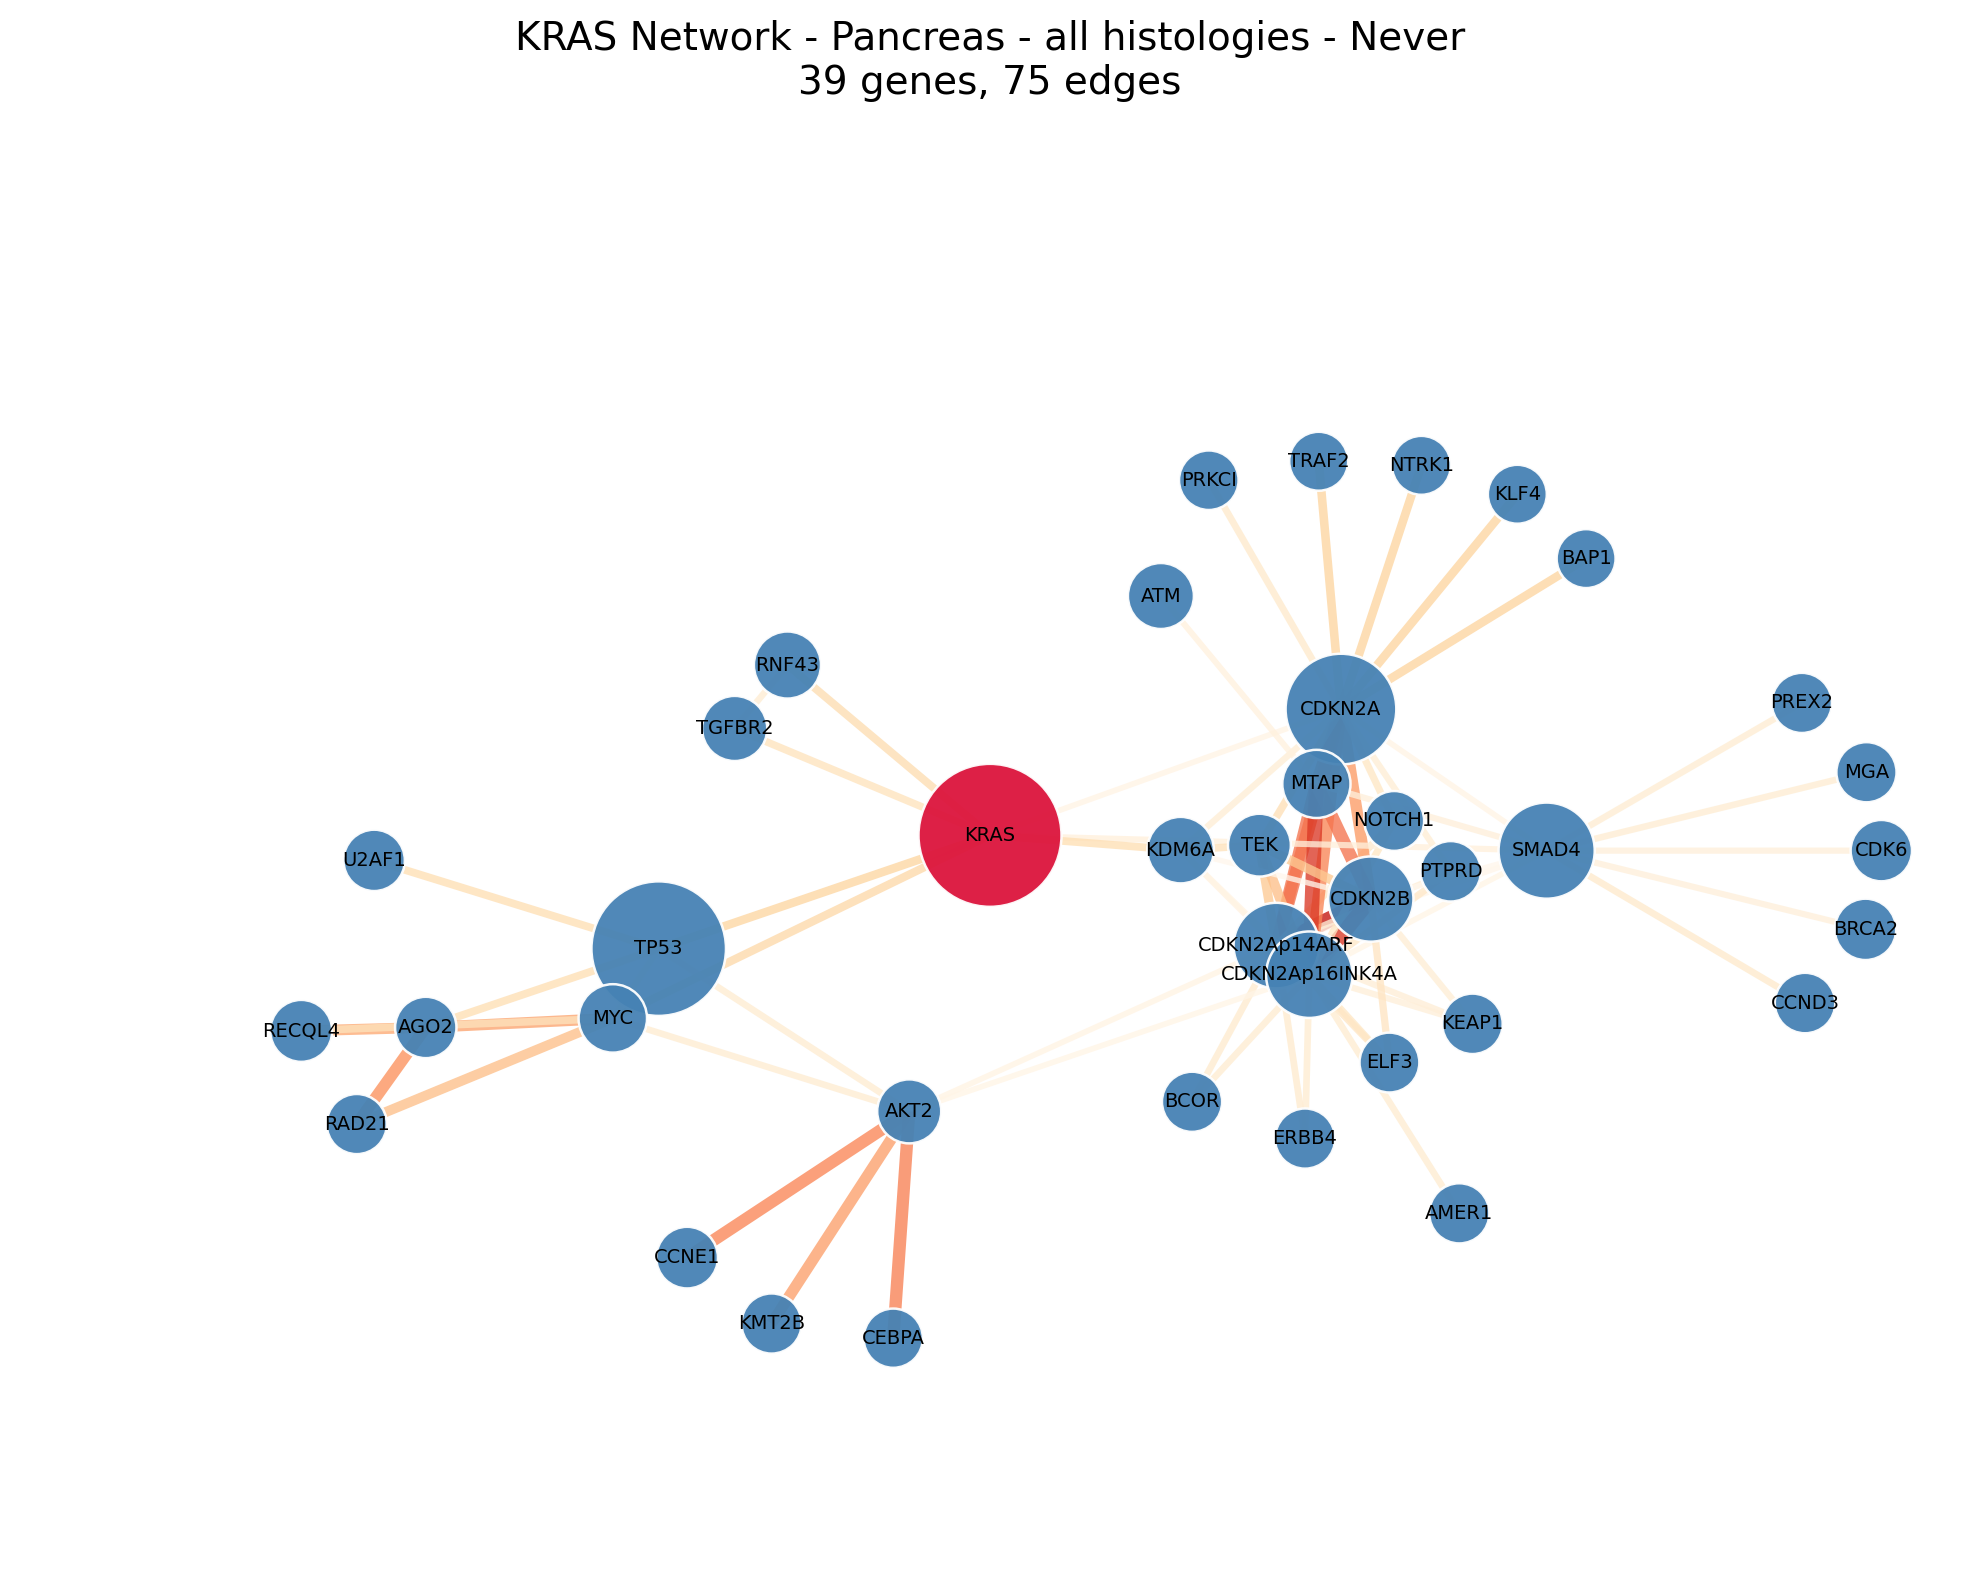


GROUP: PANCREAS_ALL (Pancreas - all histologies)
SMOKING GROUP: Former/Current Smoker
Patients: 361
Genes: 439
Edges after filters: 40
KRAS subgraph: 18 genes, 32 edges


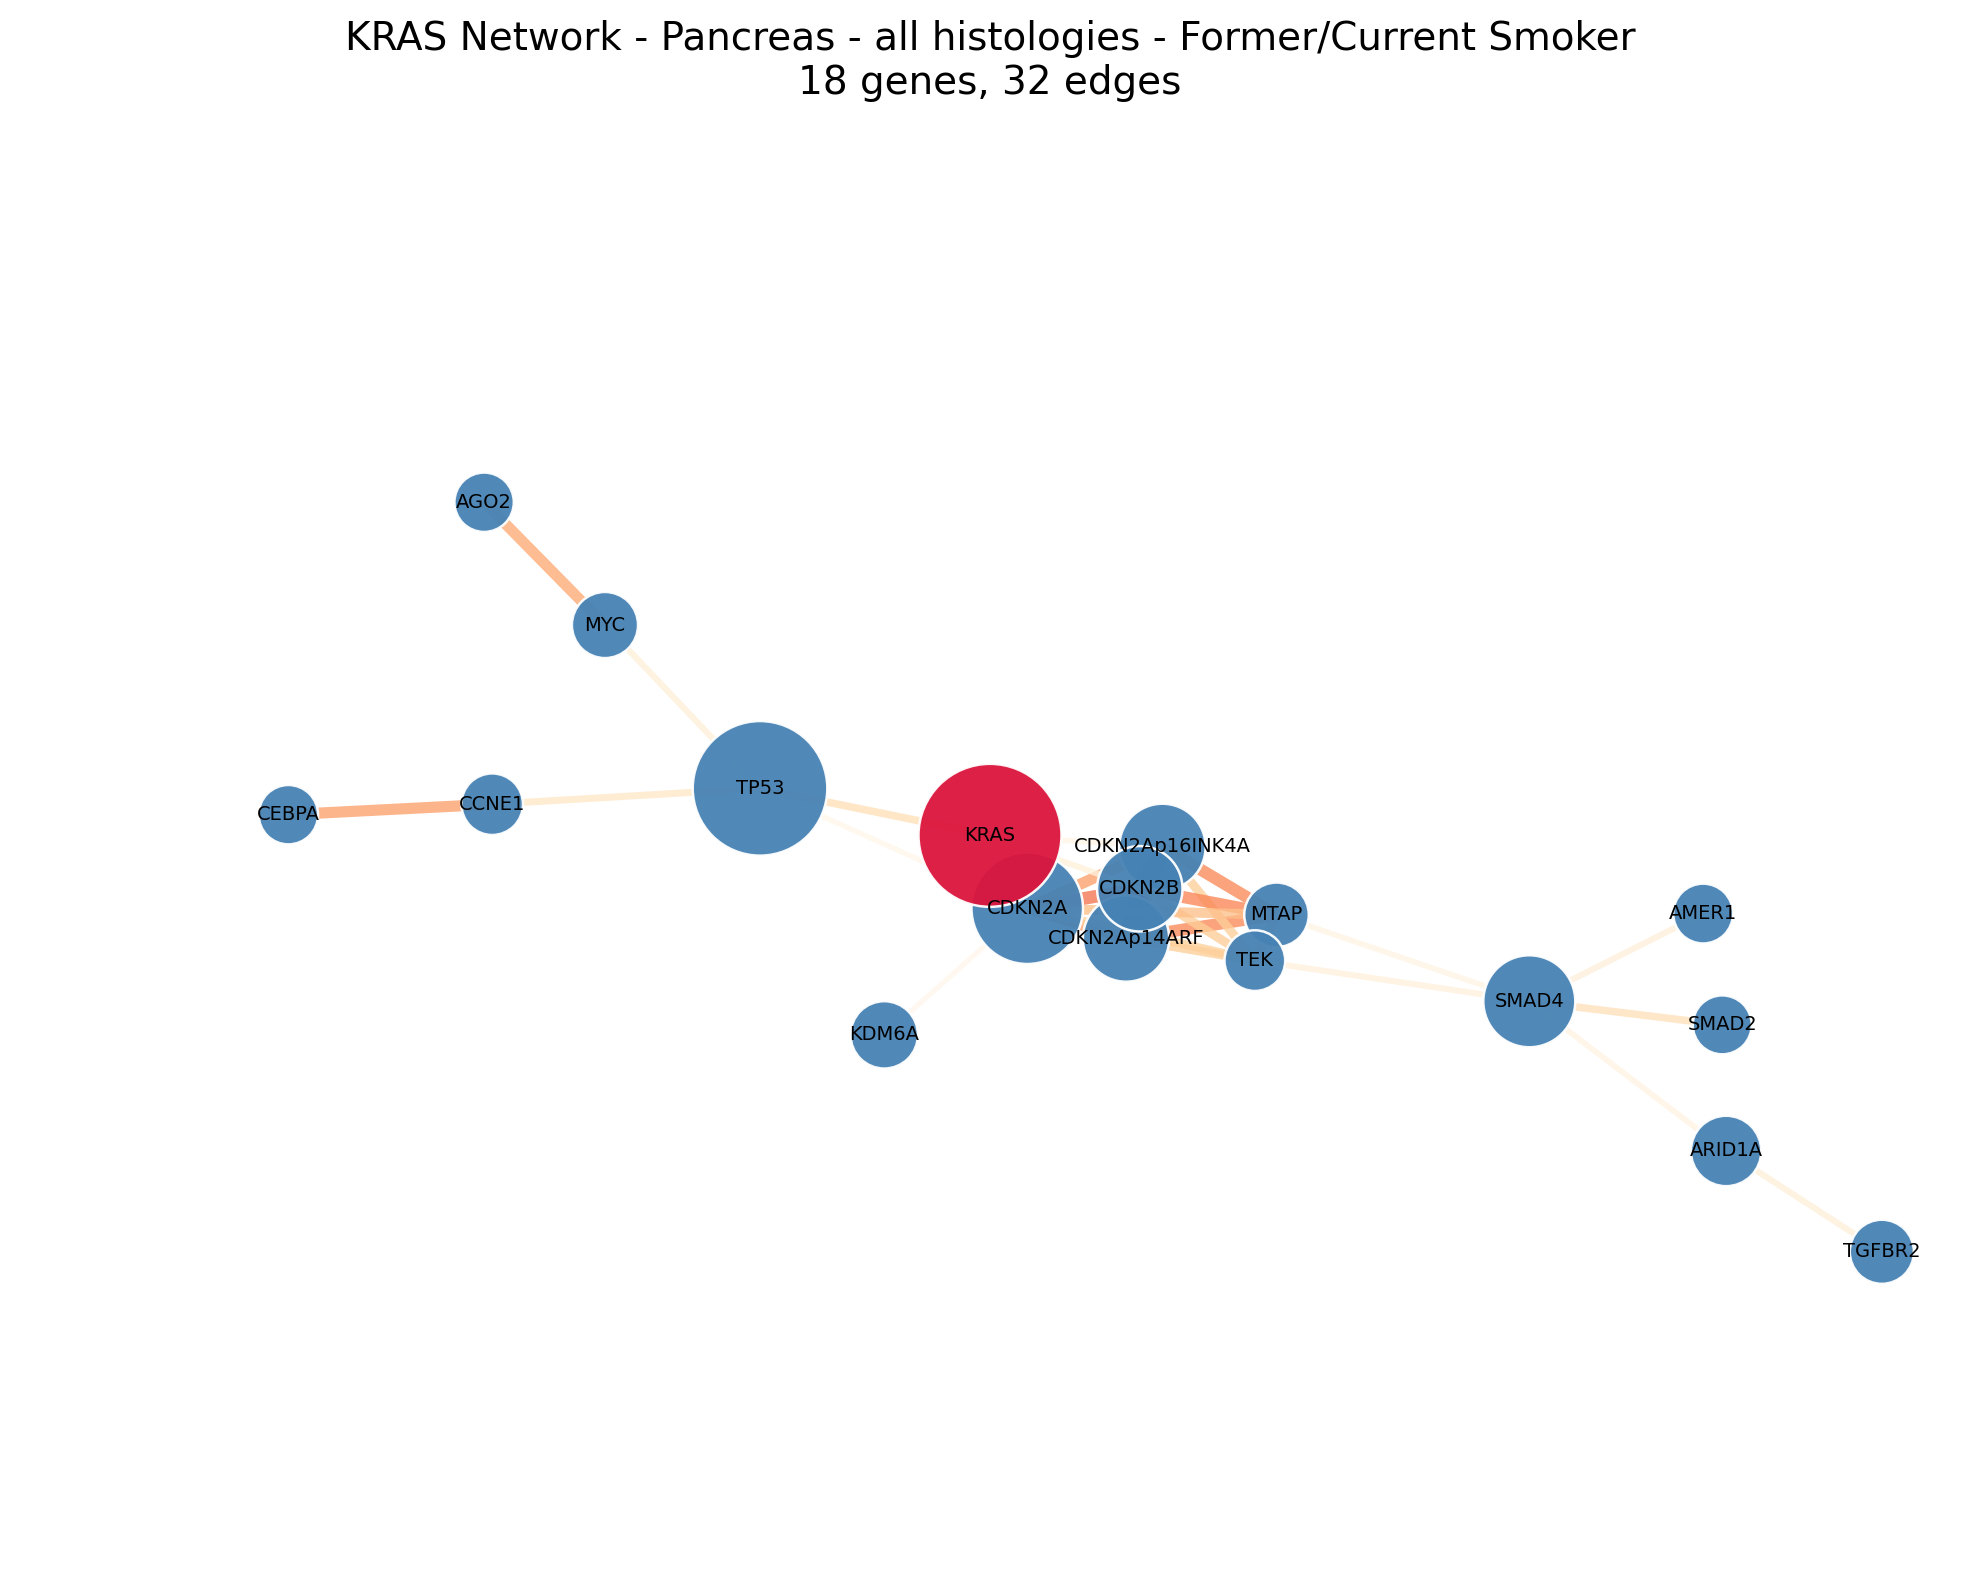


Clinical-to-network summary by smoking group - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,n_rows,n_genes_input,graph_nodes,graph_edges,contains_KRAS
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,2603,439,18,32,True
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,3755,486,39,75,True



Nota finale:
Sono state costruite reti KRAS per PANCREAS_ALL separate solo per smoking_group. Non viene fatta nessuna separazione per istologia / Oncotree.


In [23]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact


# ============================================================
# SETTINGS
# ============================================================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

# File nuovo, già annotato con smoking_group per pancreas generale
file_path_merged = (
        Path("data_pancreas")
        / "CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv"
)

# Gruppi smoking da analizzare
smoking_groups_to_analyze = [
    "Never",
    "Former/Current Smoker"
]


# ============================================================
# Helper
# ============================================================

def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["nan", "none", "unknown", "not available", "na", "n/a"]:
        return np.nan

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


# ============================================================
# FUNCTION: build KRAS-focused graph for one smoking group
# ============================================================

def build_kras_network_for_pancreas_smoking_group(
        df,
        group_name,
        group_col="smoking_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=1,
        max_p_value=0.05,
        min_shared=5,
        max_hops_from_kras=None,
        min_patients_for_network=10
):

    df_group = df[
        df[group_col] == group_name
        ].copy()

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    print("\n" + "=" * 90)
    print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
    print(f"SMOKING GROUP: {group_name}")
    print(f"Patients: {tmp[patient_col].nunique()}")
    print(f"Genes: {tmp[gene_col].nunique()}")

    if tmp[patient_col].nunique() < min_patients_for_network:
        print(f"Skipped: fewer than {min_patients_for_network} patients.")
        return None, None, df_group

    if tmp[gene_col].nunique() < 2:
        print("Skipped: fewer than 2 genes.")
        return None, None, df_group

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    N = patient_gene.shape[0]
    gene_counts = patient_gene.sum(axis=0)

    co = patient_gene.T @ patient_gene

    co_np = co.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co = pd.DataFrame(
        co_np,
        index=co.index,
        columns=co.columns
    )

    edges = (
        co.where(np.triu(np.ones(co.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges = edges.dropna(subset=["a_both"]).copy()
    edges["a_both"] = edges["a_both"].astype(int)

    rows = []

    for r in edges.itertuples(index=False):
        g1, g2, a = r.Gene1, r.Gene2, int(r.a_both)

        b = int(gene_counts[g1] - a)
        c = int(gene_counts[g2] - a)
        d = int(N - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    results["ONCOTREE_CODE"] = PANCREAS_GROUP
    results["Included_Oncotree_Codes"] = PANCREAS_LABEL
    results["smoking_group"] = group_name
    results["n_patients_group"] = N

    edges_plot = (
        results[
            (results["log2_OR"] > min_log2_or)
            & (results["p_value"] < max_p_value)
            & (results["a_both"] >= min_shared)
            ]
        .sort_values(["p_value", "log2_OR"], ascending=[True, False])
        .copy()
    )

    print(f"Edges after filters: {len(edges_plot)}")

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
            oncotree_code=PANCREAS_GROUP,
            included_oncotree_codes=PANCREAS_LABEL,
            smoking_group=group_name
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print("No edges with current thresholds.")
        return G_plot, results, df_group

    kras_nodes = [
        n for n in G_plot.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print("KRAS is not present with these thresholds.")
        return G_plot, results, df_group

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(
        G_plot,
        kras_node
    )

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    return G_kras, results, df_group


# ============================================================
# FUNCTION: plot KRAS-focused graph
# ============================================================

def plot_kras_network(
        G_kras,
        df_group,
        group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
):

    if G_kras is None or G_kras.number_of_edges() == 0:
        print(f"No graph to plot for {PANCREAS_GROUP} - {group_name}")
        return

    kras_nodes = [
        n for n in G_kras.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print(f"KRAS not found in graph for {PANCREAS_GROUP} - {group_name}")
        return

    kras_node = kras_nodes[0]

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    gene_support = patient_gene.sum(axis=0).to_dict()

    plt.figure(figsize=(10, 8), dpi=200)

    local_dist = nx.single_source_shortest_path_length(
        G_kras,
        kras_node
    )

    max_d = max(local_dist.values())

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max_d + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support_vals = [
        float(gene_support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 *
            ((float(gene_support.get(n, s_min)) - s_min) / (s_max - s_min))
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white"
    )

    labels_all = {n: n for n in G_kras.nodes()}

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels=labels_all,
        font_size=7
    )

    xy = np.array(list(pos.values()))

    r = float(np.abs(xy).max()) if xy.size else 1.0
    lim = r + (0.08 * r + 0.05)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)

    plt.title(
        f"KRAS Network - {PANCREAS_LABEL} - {group_name}\n"
        f"{G_kras.number_of_nodes()} genes, {G_kras.number_of_edges()} edges",
        fontsize=14
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# LOAD DATA
# ============================================================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Gene": "Hugo_Symbol",
    "Hugo_Symbol": "Hugo_Symbol",

    "Smoking History (NLP)": "SMOKING_RAW",
    "Smoking History": "SMOKING_RAW",
    "Smoking_History_NLP": "SMOKING_RAW",
    "SMOKING": "SMOKING_RAW",
    "Smoking": "SMOKING_RAW",
    "smoking": "SMOKING_RAW",

    "SMOKING_GROUP": "smoking_group",
    "smoking_group": "smoking_group"
})

df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

required_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel file merged clinical-to-network pancreas all: {missing_cols}"
    )

if "smoking_group" not in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    raise ValueError(
        "Colonna smoking non trovata nel file merged clinical-to-network pancreas all. "
        "Dovrebbe esserci smoking_group oppure SMOKING_RAW."
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str).str.strip()

# Creo SMOKING_RAW se manca ma esiste smoking_group
if "SMOKING_RAW" not in df_merge.columns and "smoking_group" in df_merge.columns:
    df_merge["SMOKING_RAW"] = df_merge["smoking_group"].astype(str).str.strip()

# Creo smoking_group se non è già presente nel file
if "smoking_group" not in df_merge.columns:
    df_merge["smoking_group"] = df_merge["SMOKING_RAW"].apply(assign_smoking_group)
else:
    df_merge["smoking_group"] = df_merge["smoking_group"].apply(assign_smoking_group)

df_merge["SMOKING_RAW"] = df_merge["SMOKING_RAW"].astype(str).str.strip()

df_merge.loc[
    df_merge["SMOKING_RAW"].str.lower().isin(
        ["nan", "none", "", "unknown", "not available", "na", "n/a"]
    ),
    "SMOKING_RAW"
] = np.nan

df_merge.loc[df_merge["smoking_group"].isna(), "SMOKING_RAW"] = np.nan

# Forzo gruppo unico pancreas
df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Oncotree_Group"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL

# Se esiste ORIGINAL_ONCOTREE_CODE lo lascio come informazione descrittiva.
# Se non esiste, lo creo come Unknown.
if "ORIGINAL_ONCOTREE_CODE" not in df_merge.columns:
    df_merge["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df_merge["ORIGINAL_ONCOTREE_CODE"] = (
    df_merge["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "smoking_group"
    ]
).copy()

df_merge["smoking_group"] = df_merge["smoking_group"].astype(str)

print("Loaded:")
print(file_path_merged)

print("\nSmoking group distribution - PANCREAS_ALL:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
        .agg(
            n_patients=("Patient_ID", "nunique"),
            original_smoking_values=(
                "SMOKING_RAW",
                lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
            )
        )
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "smoking_group"])
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
        .agg(
            n_patients=("Patient_ID", "nunique"),
            original_smoking_values=(
                "SMOKING_RAW",
                lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
            )
        )
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "smoking_group"])
    )


print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
        .agg(
            n_patients=("Patient_ID", "nunique")
        )
        .reset_index()
        .sort_values("n_patients", ascending=False)
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
        .agg(
            n_patients=("Patient_ID", "nunique")
        )
        .reset_index()
        .sort_values("n_patients", ascending=False)
    )


# ============================================================
# BUILD AND PLOT NETWORKS BY SMOKING GROUP
# ============================================================

graphs_by_smoking = {}
results_by_smoking = {}
df_by_smoking = {}

for group_name in smoking_groups_to_analyze:

    G_group, results_group, df_group = build_kras_network_for_pancreas_smoking_group(
        df=df_merge,
        group_name=group_name,
        group_col="smoking_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=min_log2_or,
        max_p_value=max_p_value,
        min_shared=min_shared,
        max_hops_from_kras=max_hops_from_kras,
        min_patients_for_network=min_patients_for_network
    )

    graphs_by_smoking[group_name] = G_group
    results_by_smoking[group_name] = results_group
    df_by_smoking[group_name] = df_group

    plot_kras_network(
        G_kras=G_group,
        df_group=df_group,
        group_name=group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

summary_rows = []

for group_name, G in graphs_by_smoking.items():

    if G is None:
        n_nodes = 0
        n_edges = 0
        has_kras = False
    else:
        n_nodes = G.number_of_nodes()
        n_edges = G.number_of_edges()
        has_kras = any(str(n).upper() == "KRAS" for n in G.nodes())

    df_tmp = df_merge[
        df_merge["smoking_group"] == group_name
        ]

    summary_rows.append({
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "smoking_group": group_name,
        "n_patients": df_tmp["Patient_ID"].nunique(),
        "n_rows": df_tmp.shape[0],
        "n_genes_input": df_tmp["Hugo_Symbol"].nunique(),
        "graph_nodes": n_nodes,
        "graph_edges": n_edges,
        "contains_KRAS": has_kras
    })

clinical_network_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["smoking_group"])
    .reset_index(drop=True)
)

print("\nClinical-to-network summary by smoking group - PANCREAS_ALL:")

try:
    display(clinical_network_summary)
except NameError:
    print(clinical_network_summary)


# ============================================================
# COMPATIBILITY ALIASES
# ============================================================

graphs_by_pancreas_smoking = graphs_by_smoking
results_by_pancreas_smoking = results_by_smoking

# Alias compatibili se celle successive cercano ancora questi nomi
graphs_by_oncotree_smoking = {
    PANCREAS_GROUP: graphs_by_smoking
}

results_by_oncotree_smoking = {
    PANCREAS_GROUP: results_by_smoking
}

graphs_by_oncotree_group_smoking = graphs_by_oncotree_smoking
results_by_oncotree_group_smoking = results_by_oncotree_smoking

print("\nNota finale:")
print(
    "Sono state costruite reti KRAS per PANCREAS_ALL separate solo per smoking_group. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)

#### 3. Hub analysis e confronto HIGH vs LOW

In [24]:
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
import re

# ============================================================
# HUB ANALYSIS - PANCREAS OVERALL
# SMOKING networks within PANCREAS_ALL
#
# Confronto:
#   Never
#   Former/Current Smoker
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"


# ============================================================
# 0. Recupero dei grafi creati nella cella precedente
# ============================================================

if "graphs_by_pancreas_smoking" in globals():
    graphs_by_smoking = globals()["graphs_by_pancreas_smoking"]

elif "graphs_by_smoking" in globals():
    graphs_by_smoking = globals()["graphs_by_smoking"]

elif "graphs_by_oncotree_smoking" in globals():
    # Compatibilità con la cella precedente, se hai salvato così:
    # graphs_by_oncotree_smoking = {PANCREAS_ALL: graphs_by_smoking}
    if PANCREAS_GROUP in graphs_by_oncotree_smoking:
        graphs_by_smoking = graphs_by_oncotree_smoking[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in graphs_by_oncotree_smoking. "
            "Esegui prima la cella che costruisce le network per PANCREAS_ALL."
        )

elif "graphs_by_oncotree_group_smoking" in globals():
    if PANCREAS_GROUP in graphs_by_oncotree_group_smoking:
        graphs_by_smoking = graphs_by_oncotree_group_smoking[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in graphs_by_oncotree_group_smoking. "
            "Esegui prima la cella che costruisce le network per PANCREAS_ALL."
        )

else:
    raise ValueError(
        "Nessuna variabile con i grafi disponibile. "
        "Esegui prima la cella che costruisce le network KRAS per PANCREAS_ALL per smoking_group."
    )


smoking_groups_to_compare = [
    "Never",
    "Former/Current Smoker"
]

hub_output_dir = (
        Path("data_pancreas")
        / "clinical_to_network_smoking_pancreas_all"
        / "hub_analysis_pancreas_all_smoking"
)

hub_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


# ============================================================
# FUNCTION: compute hub table
# ============================================================

def compute_hub_table(
        G,
        group_name,
        weight_col="log2_or"
):
    """
    Calcola le metriche hub per una network specifica:

    - gruppo unico: PANCREAS_ALL
    - smoking group: Never / Former/Current Smoker

    Metriche:
    - Degree
    - Node Strength
    - Betweenness
    - Closeness
    - HubScore composito
    """

    if G is None or G.number_of_nodes() == 0 or G.number_of_edges() == 0:
        print(f"No graph available for {PANCREAS_GROUP} - {group_name}")
        return pd.DataFrame()

    degree = dict(G.degree())

    node_strength = {
        n: sum(
            G[n][nbr].get(weight_col, 1.0)
            for nbr in G.neighbors(n)
        )
        for n in G.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G,
        weight=weight_col,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    hub_df = pd.DataFrame({
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "smoking_group": group_name,
        "Gene": list(G.nodes()),
        "Degree": [degree.get(g, 0) for g in G.nodes()],
        "Node_Strength": [node_strength.get(g, 0) for g in G.nodes()],
        "Betweenness": [betweenness.get(g, 0) for g in G.nodes()],
        "Closeness": [closeness.get(g, 0) for g in G.nodes()],
        "Graph_nodes": G.number_of_nodes(),
        "Graph_edges": G.number_of_edges(),
        "Graph_density": nx.density(G)
    })

    # HubScore composito
    hub_df["HubScore"] = (
            hub_df["Degree"].rank(pct=True) * 0.25
            + hub_df["Node_Strength"].rank(pct=True) * 0.25
            + hub_df["Betweenness"].rank(pct=True) * 0.25
            + hub_df["Closeness"].rank(pct=True) * 0.25
    )

    hub_df = hub_df.sort_values(
        "HubScore",
        ascending=False
    ).reset_index(drop=True)

    hub_df["Rank_in_network"] = hub_df.index + 1

    return hub_df


# ============================================================
# 1. Compute hub tables for each smoking group
# ============================================================

hub_tables_by_pancreas_smoking = {}
all_hub_tables_smoking = []

for group_name in smoking_groups_to_compare:

    G = graphs_by_smoking.get(group_name, None)

    hub_df = compute_hub_table(
        G=G,
        group_name=group_name
    )

    hub_tables_by_pancreas_smoking[group_name] = hub_df

    if not hub_df.empty:
        all_hub_tables_smoking.append(hub_df)

        safe_group_name = safe_filename(group_name)

        output_file = (
                hub_output_dir
                / f"hub_genes_{PANCREAS_GROUP}_{safe_group_name}_smoking_network.csv"
        )

        hub_df.to_csv(output_file, index=False)

        print(f"Saved: {output_file}")


# ============================================================
# 2. Combined hub table
# ============================================================

if len(all_hub_tables_smoking) > 0:
    hub_all_pancreas_smoking = pd.concat(
        all_hub_tables_smoking,
        ignore_index=True
    )

    hub_all_file = (
            hub_output_dir
            / "hub_genes_all_pancreas_smoking_networks.csv"
    )

    hub_all_pancreas_smoking.to_csv(
        hub_all_file,
        index=False
    )

    print("\nSaved combined hub table:")
    print(hub_all_file)

else:
    hub_all_pancreas_smoking = pd.DataFrame()
    print("No hub tables were created.")


# ============================================================
# 3. Display top hubs per smoking group
# ============================================================

top_n = 20

print("\n" + "#" * 100)
print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
print("#" * 100)

for group_name in smoking_groups_to_compare:

    hub_df = hub_tables_by_pancreas_smoking.get(group_name, pd.DataFrame())

    print("\n" + "=" * 90)
    print(
        f"TOP HUB GENES - {PANCREAS_GROUP} ({PANCREAS_LABEL}) - "
        f"{group_name.upper()} NETWORK"
    )
    print("=" * 90)

    if hub_df is None or hub_df.empty:
        print(f"No hub table available for {PANCREAS_GROUP} - {group_name}")
        continue

    print(
        f"Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti "
        f"{group_name} del pancreas generale."
    )

    safe_display(
        hub_df[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "smoking_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ].head(top_n)
    )


# ============================================================
# 4. Compare Never vs Former/Current Smoker hub scores
# ============================================================

never_label = "Never"
smoker_label = "Former/Current Smoker"

hub_never = hub_tables_by_pancreas_smoking.get(never_label, pd.DataFrame())
hub_smoker = hub_tables_by_pancreas_smoking.get(smoker_label, pd.DataFrame())

if hub_never is None or hub_never.empty:
    print(f"[{PANCREAS_GROUP}] {never_label} hub table missing or empty. Skipping comparison.")
    hub_comparison_pancreas_smoking = pd.DataFrame()

elif hub_smoker is None or hub_smoker.empty:
    print(f"[{PANCREAS_GROUP}] {smoker_label} hub table missing or empty. Skipping comparison.")
    hub_comparison_pancreas_smoking = pd.DataFrame()

else:
    hub_never_for_merge = hub_never.copy()
    hub_smoker_for_merge = hub_smoker.copy()

    hub_never_for_merge = hub_never_for_merge.drop(
        columns=["smoking_group"],
        errors="ignore"
    )

    hub_smoker_for_merge = hub_smoker_for_merge.drop(
        columns=["smoking_group"],
        errors="ignore"
    )

    hub_comparison_pancreas_smoking = hub_never_for_merge.merge(
        hub_smoker_for_merge,
        on=[
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "Gene"
        ],
        how="outer",
        suffixes=("_never", "_former_current_smoker")
    )

    hub_comparison_pancreas_smoking["Delta_HubScore_never_minus_former_current_smoker"] = (
            hub_comparison_pancreas_smoking["HubScore_never"].fillna(0)
            - hub_comparison_pancreas_smoking["HubScore_former_current_smoker"].fillna(0)
    )

    hub_comparison_pancreas_smoking["Delta_Degree_never_minus_former_current_smoker"] = (
            hub_comparison_pancreas_smoking["Degree_never"].fillna(0)
            - hub_comparison_pancreas_smoking["Degree_former_current_smoker"].fillna(0)
    )

    hub_comparison_pancreas_smoking["Delta_Node_Strength_never_minus_former_current_smoker"] = (
            hub_comparison_pancreas_smoking["Node_Strength_never"].fillna(0)
            - hub_comparison_pancreas_smoking["Node_Strength_former_current_smoker"].fillna(0)
    )

    output_file = (
            hub_output_dir
            / f"hub_genes_{PANCREAS_GROUP}_never_vs_former_current_smoker_comparison.csv"
    )

    hub_comparison_pancreas_smoking.to_csv(output_file, index=False)

    print(f"\nSaved comparison for {PANCREAS_GROUP}:")
    print(output_file)


    # ------------------------------------------------------------
    # Genes more important in Never network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN NEVER NETWORK - {PANCREAS_GROUP}")
    print("=" * 90)
    print(
        "Delta positivo = il gene è più hub/importante nella rete Never "
        "rispetto alla rete Former/Current Smoker, nel pancreas generale."
    )

    safe_display(
        hub_comparison_pancreas_smoking
        .sort_values("Delta_HubScore_never_minus_former_current_smoker", ascending=False)
        [
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_never",
                "HubScore_former_current_smoker",
                "Delta_HubScore_never_minus_former_current_smoker",
                "Degree_never",
                "Degree_former_current_smoker",
                "Node_Strength_never",
                "Node_Strength_former_current_smoker"
            ]
        ]
        .head(top_n)
    )


    # ------------------------------------------------------------
    # Genes more important in Former/Current Smoker network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN FORMER/CURRENT SMOKER NETWORK - {PANCREAS_GROUP}")
    print("=" * 90)
    print(
        "Delta negativo = il gene è più hub/importante nella rete Former/Current Smoker "
        "rispetto alla rete Never, nel pancreas generale."
    )

    safe_display(
        hub_comparison_pancreas_smoking
        .sort_values("Delta_HubScore_never_minus_former_current_smoker", ascending=True)
        [
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_never",
                "HubScore_former_current_smoker",
                "Delta_HubScore_never_minus_former_current_smoker",
                "Degree_never",
                "Degree_former_current_smoker",
                "Node_Strength_never",
                "Node_Strength_former_current_smoker"
            ]
        ]
        .head(top_n)
    )


# ============================================================
# 5. Combined comparison table
# ============================================================

if hub_comparison_pancreas_smoking is not None and not hub_comparison_pancreas_smoking.empty:

    combined_comparison_file = (
            hub_output_dir
            / "hub_genes_never_vs_former_current_smoker_comparison_pancreas_all.csv"
    )

    hub_comparison_pancreas_smoking.to_csv(
        combined_comparison_file,
        index=False
    )

    print("\nSaved combined smoking group comparison:")
    print(combined_comparison_file)

    print("\nCombined comparison preview:")

    safe_display(
        hub_comparison_pancreas_smoking
        .sort_values(
            "Delta_HubScore_never_minus_former_current_smoker",
            ascending=False
        )
        .head(40)
    )

else:
    print("No smoking group comparison table was created.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

hub_tables_by_smoking = hub_tables_by_pancreas_smoking
hub_tables_by_pancreas_smoking = hub_tables_by_pancreas_smoking

hub_comparison_all_pancreas_smoking = hub_comparison_pancreas_smoking
hub_comparison_all_oncotree = hub_comparison_pancreas_smoking
hub_comparison_all_oncotree_groups = hub_comparison_pancreas_smoking
hub_comparison_all_oncotree_smoking = hub_comparison_pancreas_smoking

hub_all_oncotree_smoking = hub_all_pancreas_smoking
hub_all_pancreas_smoking = hub_all_pancreas_smoking

# Alias compatibile se celle successive si aspettano struttura nested per Oncotree
hub_tables_by_oncotree_smoking = {
    PANCREAS_GROUP: hub_tables_by_pancreas_smoking
}

hub_tables_by_oncotree_group_smoking = hub_tables_by_oncotree_smoking

print("\nNota finale:")
print(
    "La hub analysis è stata eseguita su PANCREAS_ALL, separando solo per smoking_group. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)

Saved: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_analysis_pancreas_all_smoking\hub_genes_PANCREAS_ALL_Never_smoking_network.csv
Saved: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_analysis_pancreas_all_smoking\hub_genes_PANCREAS_ALL_Former_Current_Smoker_smoking_network.csv

Saved combined hub table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_analysis_pancreas_all_smoking\hub_genes_all_pancreas_smoking_networks.csv

####################################################################################################
GROUP: PANCREAS_ALL (Pancreas - all histologies)
####################################################################################################

TOP HUB GENES - PANCREAS_ALL (Pancreas - all histologies) - NEVER NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti Never del pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2Ap16INK4A,15,60.368176,0.156472,0.567164,0.964744,1
1,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2Ap14ARF,14,57.593834,0.290185,0.558824,0.958333,2
2,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2A,15,55.998328,0.281650,0.558824,0.955128,3
3,PANCREAS_ALL,Pancreas - all histologies,Never,SMAD4,11,19.205649,0.517781,0.527778,0.897436,4
4,PANCREAS_ALL,Pancreas - all histologies,Never,AKT2,7,26.296795,0.320057,0.463415,0.891026,5
5,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2B,9,42.637474,0.065434,0.463415,0.868590,6
6,PANCREAS_ALL,Pancreas - all histologies,Never,KRAS,7,19.291754,0.157895,0.487179,0.862179,7
7,PANCREAS_ALL,Pancreas - all histologies,Never,MTAP,6,33.044467,0.052632,0.447059,0.814103,8
8,PANCREAS_ALL,Pancreas - all histologies,Never,MYC,6,20.614363,0.100996,0.413043,0.807692,9
9,PANCREAS_ALL,Pancreas - all histologies,Never,KDM6A,6,12.256393,0.007112,0.457831,0.762821,10



TOP HUB GENES - PANCREAS_ALL (Pancreas - all histologies) - FORMER/CURRENT SMOKER NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti Former/Current Smoker del pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2A,8,36.441790,0.382353,0.515152,0.916667,1
1,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,TEK,6,24.987777,0.404412,0.485714,0.840278,2
2,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2Ap14ARF,6,45.253206,0.022059,0.435897,0.784722,3
3,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2Ap16INK4A,6,44.202826,0.022059,0.435897,0.756944,4
4,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,SMAD4,5,10.750549,0.426471,0.404762,0.715278,5
5,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2B,6,44.732628,0.000000,0.435897,0.701389,6
6,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,MTAP,6,34.144601,0.000000,0.485714,0.694444,7
7,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,TP53,4,9.819128,0.411765,0.425000,0.680556,8
8,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,KRAS,5,10.533751,0.176471,0.414634,0.659722,9
9,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CCNE1,2,9.548736,0.117647,0.314815,0.506944,10



Saved comparison for PANCREAS_ALL:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_analysis_pancreas_all_smoking\hub_genes_PANCREAS_ALL_never_vs_former_current_smoker_comparison.csv

GENES MORE IMPORTANT IN NEVER NETWORK - PANCREAS_ALL
Delta positivo = il gene è più hub/importante nella rete Never rispetto alla rete Former/Current Smoker, nel pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,HubScore_never,HubScore_former_current_smoker,Delta_HubScore_never_minus_former_current_smoker,Degree_never,Degree_former_current_smoker,Node_Strength_never,Node_Strength_former_current_smoker
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,0.891026,NaN,0.891026,7.0,NaN,26.296795,NaN
26,PANCREAS_ALL,Pancreas - all histologies,NOTCH1,0.567308,NaN,0.567308,3.0,NaN,7.732711,NaN
16,PANCREAS_ALL,Pancreas - all histologies,ELF3,0.560897,NaN,0.560897,3.0,NaN,7.824528,NaN
30,PANCREAS_ALL,Pancreas - all histologies,PTPRD,0.548077,NaN,0.548077,3.0,NaN,6.406302,NaN
19,PANCREAS_ALL,Pancreas - all histologies,KEAP1,0.528846,NaN,0.528846,3.0,NaN,5.847227,NaN
18,PANCREAS_ALL,Pancreas - all histologies,KDM6A,0.762821,0.250000,0.512821,6.0,1.0,12.256393,1.302563
6,PANCREAS_ALL,Pancreas - all histologies,BCOR,0.455128,NaN,0.455128,2.0,NaN,4.438532,NaN
17,PANCREAS_ALL,Pancreas - all histologies,ERBB4,0.455128,NaN,0.455128,2.0,NaN,4.438532,NaN
31,PANCREAS_ALL,Pancreas - all histologies,RAD21,0.400641,NaN,0.400641,2.0,NaN,10.983218,NaN
32,PANCREAS_ALL,Pancreas - all histologies,RECQL4,0.394231,NaN,0.394231,2.0,NaN,8.421852,NaN



GENES MORE IMPORTANT IN FORMER/CURRENT SMOKER NETWORK - PANCREAS_ALL
Delta negativo = il gene è più hub/importante nella rete Former/Current Smoker rispetto alla rete Never, nel pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,HubScore_never,HubScore_former_current_smoker,Delta_HubScore_never_minus_former_current_smoker,Degree_never,Degree_former_current_smoker,Node_Strength_never,Node_Strength_former_current_smoker
3,PANCREAS_ALL,Pancreas - all histologies,ARID1A,NaN,0.430556,-0.430556,NaN,2.0,NaN,3.857134
34,PANCREAS_ALL,Pancreas - all histologies,SMAD2,NaN,0.229167,-0.229167,NaN,1.0,NaN,3.322180
36,PANCREAS_ALL,Pancreas - all histologies,TEK,0.657051,0.840278,-0.183226,5.0,6.0,19.232108,24.987777
9,PANCREAS_ALL,Pancreas - all histologies,CCNE1,0.326923,0.506944,-0.180021,1.0,2.0,6.542877,9.548736
11,PANCREAS_ALL,Pancreas - all histologies,CDKN2A,0.955128,0.916667,0.038462,15.0,8.0,55.998328,36.441790
38,PANCREAS_ALL,Pancreas - all histologies,TP53,0.750000,0.680556,0.069444,5.0,4.0,13.701363,9.819128
15,PANCREAS_ALL,Pancreas - all histologies,CEBPA,0.333333,0.243056,0.090278,1.0,1.0,6.718166,6.671482
2,PANCREAS_ALL,Pancreas - all histologies,AMER1,0.320513,0.201389,0.119124,1.0,1.0,2.185376,2.088668
24,PANCREAS_ALL,Pancreas - all histologies,MTAP,0.814103,0.694444,0.119658,6.0,6.0,33.044467,34.144601
14,PANCREAS_ALL,Pancreas - all histologies,CDKN2B,0.868590,0.701389,0.167201,9.0,6.0,42.637474,44.732628



Saved combined smoking group comparison:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_analysis_pancreas_all_smoking\hub_genes_never_vs_former_current_smoker_comparison_pancreas_all.csv

Combined comparison preview:


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,Degree_never,Node_Strength_never,Betweenness_never,Closeness_never,Graph_nodes_never,Graph_edges_never,Graph_density_never,...,Betweenness_former_current_smoker,Closeness_former_current_smoker,Graph_nodes_former_current_smoker,Graph_edges_former_current_smoker,Graph_density_former_current_smoker,HubScore_former_current_smoker,Rank_in_network_former_current_smoker,Delta_HubScore_never_minus_former_current_smoker,Delta_Degree_never_minus_former_current_smoker,Delta_Node_Strength_never_minus_former_current_smoker
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,7.0,26.296795,0.320057,0.463415,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.891026,7.0,26.296795
26,PANCREAS_ALL,Pancreas - all histologies,NOTCH1,3.0,7.732711,0.000000,0.404255,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.567308,3.0,7.732711
16,PANCREAS_ALL,Pancreas - all histologies,ELF3,3.0,7.824528,0.000000,0.372549,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.560897,3.0,7.824528
30,PANCREAS_ALL,Pancreas - all histologies,PTPRD,3.0,6.406302,0.000000,0.404255,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.548077,3.0,6.406302
19,PANCREAS_ALL,Pancreas - all histologies,KEAP1,3.0,5.847227,0.000000,0.372549,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.528846,3.0,5.847227
18,PANCREAS_ALL,Pancreas - all histologies,KDM6A,6.0,12.256393,0.007112,0.457831,39.0,75.0,0.101215,...,0.000000,0.346939,18.0,32.0,0.20915,0.250000,13.0,0.512821,5.0,10.953830
6,PANCREAS_ALL,Pancreas - all histologies,BCOR,2.0,4.438532,0.000000,0.368932,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.455128,2.0,4.438532
17,PANCREAS_ALL,Pancreas - all histologies,ERBB4,2.0,4.438532,0.000000,0.368932,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.455128,2.0,4.438532
31,PANCREAS_ALL,Pancreas - all histologies,RAD21,2.0,10.983218,0.000000,0.296875,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.400641,2.0,10.983218
32,PANCREAS_ALL,Pancreas - all histologies,RECQL4,2.0,8.421852,0.000000,0.296875,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.394231,2.0,8.421852



Nota finale:
La hub analysis è stata eseguita su PANCREAS_ALL, separando solo per smoking_group. Non viene fatta nessuna separazione per istologia / Oncotree.


#### 4. Plot degli hub e differenze HIGH vs LOW


####################################################################################################
GROUP: PANCREAS_ALL (Pancreas - all histologies)
####################################################################################################


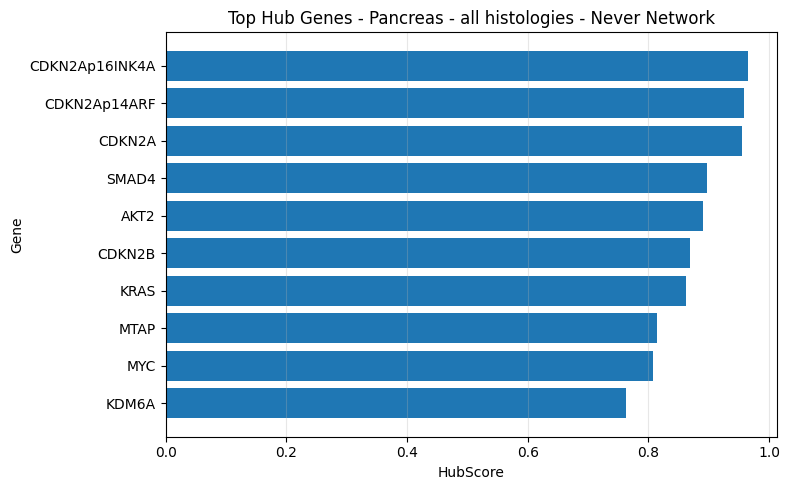

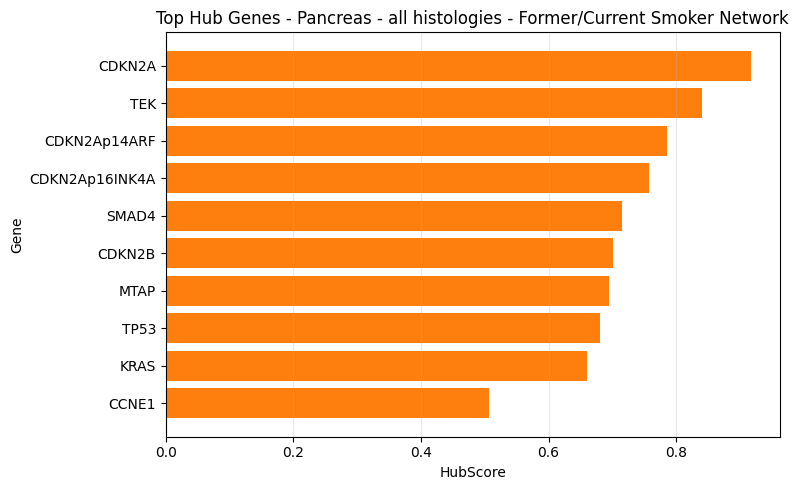

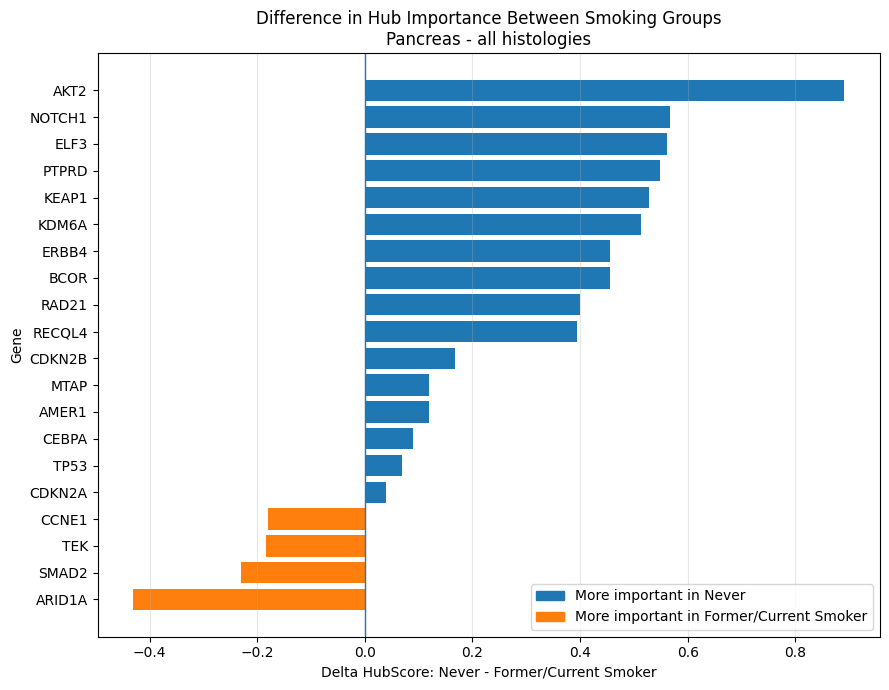


Top hubs - Never:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2Ap16INK4A,15,60.368176,0.156472,0.567164,0.964744,1
1,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2Ap14ARF,14,57.593834,0.290185,0.558824,0.958333,2
2,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2A,15,55.998328,0.281650,0.558824,0.955128,3
3,PANCREAS_ALL,Pancreas - all histologies,Never,SMAD4,11,19.205649,0.517781,0.527778,0.897436,4
4,PANCREAS_ALL,Pancreas - all histologies,Never,AKT2,7,26.296795,0.320057,0.463415,0.891026,5
5,PANCREAS_ALL,Pancreas - all histologies,Never,CDKN2B,9,42.637474,0.065434,0.463415,0.868590,6
6,PANCREAS_ALL,Pancreas - all histologies,Never,KRAS,7,19.291754,0.157895,0.487179,0.862179,7
7,PANCREAS_ALL,Pancreas - all histologies,Never,MTAP,6,33.044467,0.052632,0.447059,0.814103,8
8,PANCREAS_ALL,Pancreas - all histologies,Never,MYC,6,20.614363,0.100996,0.413043,0.807692,9
9,PANCREAS_ALL,Pancreas - all histologies,Never,KDM6A,6,12.256393,0.007112,0.457831,0.762821,10



Top hubs - Former/Current Smoker:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2A,8,36.441790,0.382353,0.515152,0.916667,1
1,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,TEK,6,24.987777,0.404412,0.485714,0.840278,2
2,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2Ap14ARF,6,45.253206,0.022059,0.435897,0.784722,3
3,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2Ap16INK4A,6,44.202826,0.022059,0.435897,0.756944,4
4,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,SMAD4,5,10.750549,0.426471,0.404762,0.715278,5
5,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CDKN2B,6,44.732628,0.000000,0.435897,0.701389,6
6,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,MTAP,6,34.144601,0.000000,0.485714,0.694444,7
7,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,TP53,4,9.819128,0.411765,0.425000,0.680556,8
8,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,KRAS,5,10.533751,0.176471,0.414634,0.659722,9
9,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,CCNE1,2,9.548736,0.117647,0.314815,0.506944,10



Hub difference Never vs Former/Current Smoker:


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,Degree_never,Node_Strength_never,Betweenness_never,Closeness_never,Graph_nodes_never,Graph_edges_never,Graph_density_never,...,Betweenness_former_current_smoker,Closeness_former_current_smoker,Graph_nodes_former_current_smoker,Graph_edges_former_current_smoker,Graph_density_former_current_smoker,HubScore_former_current_smoker,Rank_in_network_former_current_smoker,Delta_HubScore_never_minus_former_current_smoker,Delta_Degree_never_minus_former_current_smoker,Delta_Node_Strength_never_minus_former_current_smoker
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,7.0,26.296795,0.320057,0.463415,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.891026,7.0,26.296795
26,PANCREAS_ALL,Pancreas - all histologies,NOTCH1,3.0,7.732711,0.000000,0.404255,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.567308,3.0,7.732711
16,PANCREAS_ALL,Pancreas - all histologies,ELF3,3.0,7.824528,0.000000,0.372549,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.560897,3.0,7.824528
30,PANCREAS_ALL,Pancreas - all histologies,PTPRD,3.0,6.406302,0.000000,0.404255,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.548077,3.0,6.406302
19,PANCREAS_ALL,Pancreas - all histologies,KEAP1,3.0,5.847227,0.000000,0.372549,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.528846,3.0,5.847227
18,PANCREAS_ALL,Pancreas - all histologies,KDM6A,6.0,12.256393,0.007112,0.457831,39.0,75.0,0.101215,...,0.000000,0.346939,18.0,32.0,0.20915,0.250000,13.0,0.512821,5.0,10.953830
6,PANCREAS_ALL,Pancreas - all histologies,BCOR,2.0,4.438532,0.000000,0.368932,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.455128,2.0,4.438532
17,PANCREAS_ALL,Pancreas - all histologies,ERBB4,2.0,4.438532,0.000000,0.368932,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.455128,2.0,4.438532
31,PANCREAS_ALL,Pancreas - all histologies,RAD21,2.0,10.983218,0.000000,0.296875,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.400641,2.0,10.983218
32,PANCREAS_ALL,Pancreas - all histologies,RECQL4,2.0,8.421852,0.000000,0.296875,39.0,75.0,0.101215,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.394231,2.0,8.421852



Nota finale:
I grafici mostrano la hub importance per PANCREAS_ALL, separando solo i pazienti Never e Former/Current Smoker. Non viene fatta nessuna separazione per istologia / Oncotree.


In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# ============================================================
# HUB PLOTS - PANCREAS OVERALL
# Never vs Former/Current Smoker networks
#
# Gruppo unico:
#   PANCREAS_ALL
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

top_n = 10

# Gruppi smoking
NEVER_GROUP = "Never"
SMOKER_GROUP = "Former/Current Smoker"

# Colori smoking groups
NEVER_COLOR = "tab:blue"      # Never
SMOKER_COLOR = "tab:orange"   # Former/Current Smoker


# ============================================================
# 0. Compatibilità con i nomi creati nella cella precedente
# ============================================================

if "hub_tables_by_pancreas_smoking" in globals():
    hub_tables_by_smoking_plot = hub_tables_by_pancreas_smoking

elif "hub_tables_by_smoking" in globals():
    hub_tables_by_smoking_plot = hub_tables_by_smoking

elif "hub_tables_by_oncotree_smoking" in globals():
    if PANCREAS_GROUP in hub_tables_by_oncotree_smoking:
        hub_tables_by_smoking_plot = hub_tables_by_oncotree_smoking[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in hub_tables_by_oncotree_smoking. "
            "Esegui prima la hub analysis per PANCREAS_ALL."
        )

elif "hub_tables_by_oncotree_group_smoking" in globals():
    if PANCREAS_GROUP in hub_tables_by_oncotree_group_smoking:
        hub_tables_by_smoking_plot = hub_tables_by_oncotree_group_smoking[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in hub_tables_by_oncotree_group_smoking. "
            "Esegui prima la hub analysis per PANCREAS_ALL."
        )

else:
    raise ValueError(
        "Nessuna tabella hub disponibile. "
        "Esegui prima la cella di hub analysis per PANCREAS_ALL e smoking_group."
    )


# Recupero confronto Never vs Former/Current Smoker
if "hub_comparison_pancreas_smoking" in globals():
    hub_comparison = hub_comparison_pancreas_smoking.copy()

elif "hub_comparison_all_pancreas_smoking" in globals():
    hub_comparison = hub_comparison_all_pancreas_smoking.copy()

elif "hub_comparison_all_oncotree_smoking" in globals():
    hub_comparison = hub_comparison_all_oncotree_smoking.copy()

elif "hub_comparison_all_oncotree" in globals():
    hub_comparison = hub_comparison_all_oncotree.copy()

else:
    raise ValueError(
        "Tabella di confronto hub non disponibile. "
        "Esegui prima la cella di confronto hub Never vs Former/Current Smoker per PANCREAS_ALL."
    )


# Se la tabella contiene più gruppi, tengo solo PANCREAS_ALL
if "ONCOTREE_CODE" in hub_comparison.columns:
    hub_comparison = hub_comparison[
        hub_comparison["ONCOTREE_CODE"] == PANCREAS_GROUP
        ].copy()

elif "Oncotree_Group" in hub_comparison.columns:
    hub_comparison = hub_comparison[
        hub_comparison["Oncotree_Group"] == PANCREAS_GROUP
        ].copy()


# ============================================================
# 1. Recupero hub tables Never e Former/Current Smoker
# ============================================================

hub_never = hub_tables_by_smoking_plot.get(NEVER_GROUP, pd.DataFrame())
hub_smoker = hub_tables_by_smoking_plot.get(SMOKER_GROUP, pd.DataFrame())


print("\n" + "#" * 100)
print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
print("#" * 100)


# ============================================================
# 2. Top hubs Never
# ============================================================

if hub_never is None or hub_never.empty:
    print(f"[{PANCREAS_GROUP}] Nessuna hub table Never disponibile.")

else:
    top_never = (
        hub_never
        .sort_values("HubScore", ascending=False)
        .head(top_n)
        .copy()
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        top_never["Gene"][::-1],
        top_never["HubScore"][::-1],
        color=NEVER_COLOR
    )

    plt.title(
        f"Top Hub Genes - {PANCREAS_LABEL} - Never Network"
    )
    plt.xlabel("HubScore")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 3. Top hubs Former/Current Smoker
# ============================================================

if hub_smoker is None or hub_smoker.empty:
    print(f"[{PANCREAS_GROUP}] Nessuna hub table Former/Current Smoker disponibile.")

else:
    top_smoker = (
        hub_smoker
        .sort_values("HubScore", ascending=False)
        .head(top_n)
        .copy()
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        top_smoker["Gene"][::-1],
        top_smoker["HubScore"][::-1],
        color=SMOKER_COLOR
    )

    plt.title(
        f"Top Hub Genes - {PANCREAS_LABEL} - Former/Current Smoker Network"
    )
    plt.xlabel("HubScore")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. Difference Never vs Former/Current Smoker
# ============================================================

if hub_comparison is None or hub_comparison.empty:
    print(
        f"[{PANCREAS_GROUP}] Nessun confronto Never "
        f"vs Former/Current Smoker disponibile."
    )

else:
    delta_col = "Delta_HubScore_never_minus_former_current_smoker"

    if delta_col not in hub_comparison.columns:
        raise ValueError(
            f"Colonna {delta_col} mancante. "
            "Controlla la cella precedente di hub comparison."
        )

    delta_never = (
        hub_comparison
        .sort_values(delta_col, ascending=False)
        .head(top_n)
        .copy()
    )

    delta_smoker = (
        hub_comparison
        .sort_values(delta_col, ascending=True)
        .head(top_n)
        .copy()
    )

    delta_plot = pd.concat(
        [delta_smoker, delta_never],
        axis=0
    ).drop_duplicates(
        subset=["Gene"]
    )

    delta_plot = delta_plot.sort_values(delta_col)

    colors = [
        NEVER_COLOR if val > 0 else SMOKER_COLOR
        for val in delta_plot[delta_col]
    ]

    plt.figure(figsize=(9, 7))

    plt.barh(
        delta_plot["Gene"],
        delta_plot[delta_col],
        color=colors
    )

    plt.axvline(0, linewidth=1)

    plt.title(
        f"Difference in Hub Importance Between Smoking Groups\n"
        f"{PANCREAS_LABEL}"
    )

    plt.xlabel("Delta HubScore: Never - Former/Current Smoker")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)

    never_patch = mpatches.Patch(
        color=NEVER_COLOR,
        label="More important in Never"
    )

    smoker_patch = mpatches.Patch(
        color=SMOKER_COLOR,
        label="More important in Former/Current Smoker"
    )

    plt.legend(handles=[never_patch, smoker_patch])

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. Optional summary tables
# ============================================================

print("\nTop hubs - Never:")

if hub_never is not None and not hub_never.empty:
    display(
        hub_never[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "smoking_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ]
        .sort_values("HubScore", ascending=False)
        .head(top_n)
    )
else:
    print("No data.")


print("\nTop hubs - Former/Current Smoker:")

if hub_smoker is not None and not hub_smoker.empty:
    display(
        hub_smoker[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "smoking_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ]
        .sort_values("HubScore", ascending=False)
        .head(top_n)
    )
else:
    print("No data.")


print("\nHub difference Never vs Former/Current Smoker:")

if hub_comparison is not None and not hub_comparison.empty:
    display(
        hub_comparison
        .sort_values(
            "Delta_HubScore_never_minus_former_current_smoker",
            ascending=False
        )
        .head(top_n * 2)
    )
else:
    print("No comparison data.")


print("\nNota finale:")
print(
    "I grafici mostrano la hub importance per PANCREAS_ALL, "
    "separando solo i pazienti Never e Former/Current Smoker. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)

In [26]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# MAP SMOKING HUB GENES TO LEIDEN CLUSTERS
# PANCREAS_ALL
#
# Obiettivo:
# - prendere i geni hub più rappresentativi di Never vs Former/Current Smoker
# - vedere in quali cluster Leiden cadono
# - riassumere quali cluster sono più rappresentati
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Paths and parameters
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

NEVER_LABEL = "Never"
SMOKER_LABEL = "Former/Current Smoker"

NEVER_SAFE = "never"
SMOKER_SAFE = "former_current_smoker"

smoking_base_dir = (
        data_dir
        / "clinical_to_network_smoking_pancreas_all"
)

hub_analysis_dir = (
        smoking_base_dir
        / "hub_analysis_pancreas_all_smoking"
)

output_dir = (
        smoking_base_dir
        / "hub_genes_cluster_mapping"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Numero di geni da prendere per ciascun gruppo
top_n = 20


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def clean_gene_name(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().upper()


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file in questo ordine:
    1. path candidati espliciti;
    2. ricerca automatica con glob nella cartella indicata.
    """

    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            found = sorted(search_dir.glob(pattern))
            matches.extend(found)

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica il file dei cluster Leiden per PANCREAS_ALL.

    Prima prova path espliciti probabili.
    Se non li trova, cerca automaticamente dentro data_pancreas.
    """

    candidate_paths = [
        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    clusters_df = clusters_df.loc[:, ~clusters_df.columns.duplicated()].copy()

    # Normalizzo nomi colonne
    clusters_df = clusters_df.rename(columns={
        "Hugo_Symbol": "Gene",
        "gene": "Gene",
        "GENE": "Gene",
        "cluster": "Cluster",
        "Leiden_Cluster": "Cluster",
        "leiden_cluster": "Cluster",
        "ONCOTREE_CODE": "ONCOTREE_CODE",
        "Oncotree_Group": "ONCOTREE_CODE"
    })

    required_cluster_cols = {
        "Gene",
        "Cluster"
    }

    missing_cluster_cols = required_cluster_cols - set(clusters_df.columns)

    if missing_cluster_cols:
        raise ValueError(
            f"Colonne mancanti nel file Leiden clusters: {missing_cluster_cols}\n"
            f"File caricato: {found_path}\n"
            f"Colonne disponibili: {clusters_df.columns.tolist()}"
        )

    # Se il file contiene più gruppi, tengo solo PANCREAS_ALL.
    if "ONCOTREE_CODE" in clusters_df.columns:
        clusters_tmp = clusters_df[
            clusters_df["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
            ].copy()

        if not clusters_tmp.empty:
            clusters_df = clusters_tmp.copy()

    clusters_df["Gene"] = clusters_df["Gene"].astype(str)
    clusters_df["Gene_clean"] = clusters_df["Gene"].apply(clean_gene_name)

    print("Loaded Leiden clusters:")
    print(found_path)
    print("Rows:", clusters_df.shape[0])
    print("Genes:", clusters_df["Gene_clean"].nunique())
    print("Clusters:", sorted(clusters_df["Cluster"].dropna().unique()))

    return clusters_df, found_path


def load_hub_comparison():
    """
    Carica la tabella di confronto Never vs Former/Current Smoker.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato.
    """

    possible_memory_vars = [
        "hub_comparison_pancreas_smoking",
        "hub_comparison_all_pancreas_smoking",
        "hub_comparison_all_oncotree_smoking",
        "hub_comparison_all_oncotree_groups",
        "hub_comparison_all_oncotree"
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_never_vs_former_current_smoker_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_PANCREAS_ALL_never_vs_former_current_smoker_comparison.csv",

        hub_analysis_dir
        / "hub_genes_smoking_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_smoking_group_comparison_pancreas_all.csv",
    ]

    patterns = [
        "*never*former_current_smoker*comparison*pancreas*.csv",
        "*PANCREAS_ALL*smoking*comparison*.csv",
        "*hub*smoking*comparison*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="hub comparison Never vs Former/Current Smoker for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub comparison da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto Never vs Former/Current Smoker.\n"
        "Controlla che sia stata eseguita prima la cella di hub comparison smoking per PANCREAS_ALL.\n"
        f"Cartella cercata:\n{hub_analysis_dir}"
    )


def load_hub_all():
    """
    Carica la tabella con gli hub separati Never e Former/Current Smoker.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato.
    """

    possible_memory_vars = [
        "hub_all_pancreas_smoking",
        "hub_all_oncotree_smoking",
        "hub_all_oncotree",
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_all_pancreas_smoking_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_oncotree_group_smoking_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_oncotree_smoking_networks.csv",
    ]

    patterns = [
        "*hub_genes_all*pancreas*smoking*network*.csv",
        "*hub_genes_all*smoking*network*.csv",
        "*hub*all*smoking*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="separate hub table Never / Former/Current Smoker for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub all da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    print(
        "\nTabella hub separata non trovata. "
        "Salto l'analisi alternativa sui top hub separati."
    )
    return None


def map_genes_to_clusters(gene_table, cluster_table):
    """
    Associa ogni gene alla sua informazione di cluster Leiden.
    """

    gene_table = gene_table.copy()
    cluster_table = cluster_table.copy()

    gene_table["Gene_clean"] = gene_table["Gene"].apply(clean_gene_name)
    cluster_table["Gene_clean"] = cluster_table["Gene"].apply(clean_gene_name)

    cluster_cols = [
        "Gene_clean",
        "Cluster",
        "Rank_in_cluster",
        "HubScore",
        "Degree",
        "Node Strength",
        "Node_Strength",
        "Betweenness",
        "Closeness"
    ]

    cluster_cols = [
        col for col in cluster_cols
        if col in cluster_table.columns
    ]

    cluster_gene_map = (
        cluster_table[cluster_cols]
        .drop_duplicates("Gene_clean")
        .copy()
    )

    mapped = gene_table.merge(
        cluster_gene_map,
        on="Gene_clean",
        how="left",
        suffixes=("", "_cluster")
    )

    mapped["Found_in_Leiden_clusters"] = mapped["Cluster"].notna()

    return mapped


def summarize_cluster_distribution(mapped_df, group_col):
    """
    Riassume quanti geni di ciascun gruppo cadono in ciascun cluster.
    """

    if mapped_df.empty:
        return pd.DataFrame()

    mapped_valid = mapped_df.dropna(subset=["Cluster"]).copy()

    if mapped_valid.empty:
        return pd.DataFrame()

    agg_dict = {
        "n_genes": ("Gene", "nunique"),
        "genes": ("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
        "mean_cluster_rank": ("Rank_in_cluster", "mean")
    }

    if "Abs_Delta_HubScore" in mapped_valid.columns:
        agg_dict["mean_abs_delta"] = ("Abs_Delta_HubScore", "mean")

    summary = (
        mapped_valid
        .groupby([group_col, "Cluster"])
        .agg(**agg_dict)
        .reset_index()
    )

    totals = (
        mapped_valid
        .groupby(group_col)
        .agg(total_mapped_genes=("Gene", "nunique"))
        .reset_index()
    )

    summary = summary.merge(
        totals,
        on=group_col,
        how="left"
    )

    summary["percentage"] = (
            summary["n_genes"]
            / summary["total_mapped_genes"]
            * 100
    ).round(2)

    summary = summary.sort_values(
        [group_col, "n_genes", "percentage"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

    return summary


# ============================================================
# 2. Load Leiden cluster table
# ============================================================

clusters, clusters_path = load_leiden_clusters()

print("\nCluster size summary:")

cluster_size_summary = (
    clusters
    .groupby("Cluster")
    .agg(
        n_genes=("Gene", "nunique"),
        top_cluster_genes=(
            "Gene",
            lambda x: ", ".join(x.dropna().astype(str).head(10))
        )
    )
    .reset_index()
    .sort_values("n_genes", ascending=False)
)

safe_display(cluster_size_summary)


# ============================================================
# 3. ANALISI PRINCIPALE:
#    uso i geni differenziali Never vs Former/Current Smoker
# ============================================================

hub_comparison = load_hub_comparison()
hub_comparison = hub_comparison.loc[:, ~hub_comparison.columns.duplicated()].copy()

# Normalizzo eventuale nome gruppo
if "ONCOTREE_CODE" not in hub_comparison.columns:
    if "Oncotree_Group" in hub_comparison.columns:
        hub_comparison = hub_comparison.rename(
            columns={"Oncotree_Group": "ONCOTREE_CODE"}
        )
    else:
        hub_comparison["ONCOTREE_CODE"] = PANCREAS_GROUP

# Tengo solo PANCREAS_ALL se la colonna gruppo esiste
hub_comparison = hub_comparison[
    hub_comparison["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
    ].copy()

if hub_comparison.empty:
    raise ValueError(
        f"La tabella hub_comparison è vuota dopo il filtro su {PANCREAS_GROUP}."
    )

delta_col = "Delta_HubScore_never_minus_former_current_smoker"

required_comparison_cols = {
    "ONCOTREE_CODE",
    "Gene",
    delta_col
}

missing_comparison_cols = required_comparison_cols - set(hub_comparison.columns)

if missing_comparison_cols:
    print("\nColonne disponibili nella tabella hub_comparison:")
    print(hub_comparison.columns.tolist())

    raise ValueError(
        f"Colonne mancanti nella tabella di confronto hub smoking: {missing_comparison_cols}"
    )

hub_comparison["Gene"] = hub_comparison["Gene"].astype(str)

hub_comparison[delta_col] = pd.to_numeric(
    hub_comparison[delta_col],
    errors="coerce"
)

hub_comparison = hub_comparison.dropna(
    subset=["Gene", delta_col]
).copy()


# Geni più rappresentativi della rete Never
never_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=False)
    .head(top_n)
    .copy()
)

never_genes["Signature_Group"] = "Never-enriched hub genes"


# Geni più rappresentativi della rete Former/Current Smoker
smoker_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=True)
    .head(top_n)
    .copy()
)

smoker_genes["Signature_Group"] = "Former/Current Smoker-enriched hub genes"


differential_genes = pd.concat(
    [never_genes, smoker_genes],
    ignore_index=True
)

differential_genes["Abs_Delta_HubScore"] = (
    differential_genes[delta_col]
    .abs()
)

differential_mapped = map_genes_to_clusters(
    gene_table=differential_genes,
    cluster_table=clusters
)

print("\n" + "=" * 100)
print("DIFFERENTIAL SMOKING HUB GENES MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL")
print("=" * 100)

cols_to_show = [
    "Signature_Group",
    "Gene",
    delta_col,
    "Abs_Delta_HubScore",
    "HubScore_never",
    "HubScore_former_current_smoker",
    "Degree_never",
    "Degree_former_current_smoker",
    "Node_Strength_never",
    "Node_Strength_former_current_smoker",
    "Cluster",
    "Rank_in_cluster",
    "HubScore_cluster",
    "Degree",
    "Node Strength",
    "Node_Strength",
    "Found_in_Leiden_clusters"
]

cols_to_show = [
    col for col in cols_to_show
    if col in differential_mapped.columns
]

safe_display(
    differential_mapped[cols_to_show]
    .sort_values(
        ["Signature_Group", "Abs_Delta_HubScore"],
        ascending=[True, False]
    )
)


differential_cluster_summary = summarize_cluster_distribution(
    mapped_df=differential_mapped,
    group_col="Signature_Group"
)

print("\n" + "=" * 100)
print("CLUSTER DISTRIBUTION OF DIFFERENTIAL SMOKING HUB GENES - PANCREAS_ALL")
print("=" * 100)

safe_display(differential_cluster_summary)


# ============================================================
# 4. Dominant cluster per gruppo differenziale
# ============================================================

if not differential_cluster_summary.empty:
    dominant_clusters = (
        differential_cluster_summary
        .sort_values(
            ["Signature_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        )
        .groupby("Signature_Group")
        .head(1)
        .reset_index(drop=True)
    )
else:
    dominant_clusters = pd.DataFrame()

print("\n" + "=" * 100)
print("DOMINANT LEIDEN CLUSTER FOR EACH DIFFERENTIAL SMOKING HUB SIGNATURE - PANCREAS_ALL")
print("=" * 100)

safe_display(dominant_clusters)


# ============================================================
# 5. ANALISI ALTERNATIVA:
#    uso le top hub list separate Never e Former/Current Smoker
# ============================================================

hub_all = load_hub_all()

if hub_all is not None:

    hub_all = hub_all.loc[:, ~hub_all.columns.duplicated()].copy()

    # Normalizzo eventuale nome gruppo
    if "ONCOTREE_CODE" not in hub_all.columns:
        if "Oncotree_Group" in hub_all.columns:
            hub_all = hub_all.rename(columns={"Oncotree_Group": "ONCOTREE_CODE"})
        else:
            hub_all["ONCOTREE_CODE"] = PANCREAS_GROUP

    # Normalizzo smoking_group
    if "smoking_group" not in hub_all.columns:
        if "SMOKING_GROUP" in hub_all.columns:
            hub_all = hub_all.rename(columns={"SMOKING_GROUP": "smoking_group"})
        elif "Smoking_Group" in hub_all.columns:
            hub_all = hub_all.rename(columns={"Smoking_Group": "smoking_group"})

    required_hub_all_cols = {
        "ONCOTREE_CODE",
        "smoking_group",
        "Gene",
        "HubScore"
    }

    missing_hub_all_cols = required_hub_all_cols - set(hub_all.columns)

    if missing_hub_all_cols:
        print(
            "\nColonne mancanti nella tabella hub separata. "
            f"Salto analisi alternativa. Mancano: {missing_hub_all_cols}"
        )
        print("\nColonne disponibili:")
        print(hub_all.columns.tolist())

        separate_mapped = pd.DataFrame()
        separate_cluster_summary = pd.DataFrame()

    else:
        hub_all = hub_all[
            hub_all["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
            ].copy()

        hub_all["Gene"] = hub_all["Gene"].astype(str)
        hub_all["HubScore"] = pd.to_numeric(
            hub_all["HubScore"],
            errors="coerce"
        )

        never_top_hubs = (
            hub_all[
                hub_all["smoking_group"].astype(str) == NEVER_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        never_top_hubs["Hub_List_Group"] = "Top Never hub genes"

        smoker_top_hubs = (
            hub_all[
                hub_all["smoking_group"].astype(str) == SMOKER_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        smoker_top_hubs["Hub_List_Group"] = "Top Former/Current Smoker hub genes"

        separate_top_hubs = pd.concat(
            [never_top_hubs, smoker_top_hubs],
            ignore_index=True
        )

        separate_mapped = map_genes_to_clusters(
            gene_table=separate_top_hubs,
            cluster_table=clusters
        )

        print("\n" + "=" * 100)
        print("SEPARATE SMOKING TOP HUB LISTS MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL")
        print("=" * 100)

        cols_to_show_sep = [
            "Hub_List_Group",
            "smoking_group",
            "Gene",
            "HubScore",
            "Degree",
            "Node_Strength",
            "Betweenness",
            "Closeness",
            "Cluster",
            "Rank_in_cluster",
            "HubScore_cluster",
            "Found_in_Leiden_clusters"
        ]

        cols_to_show_sep = [
            col for col in cols_to_show_sep
            if col in separate_mapped.columns
        ]

        safe_display(
            separate_mapped[cols_to_show_sep]
            .sort_values(["Hub_List_Group", "HubScore"], ascending=[True, False])
        )

        separate_cluster_summary = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby(["Hub_List_Group", "Cluster"])
            .agg(
                n_genes=("Gene", "nunique"),
                genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
                mean_hubscore=("HubScore", "mean"),
                mean_cluster_rank=("Rank_in_cluster", "mean")
            )
            .reset_index()
        )

        separate_totals = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby("Hub_List_Group")
            .agg(total_mapped_genes=("Gene", "nunique"))
            .reset_index()
        )

        separate_cluster_summary = separate_cluster_summary.merge(
            separate_totals,
            on="Hub_List_Group",
            how="left"
        )

        separate_cluster_summary["percentage"] = (
                separate_cluster_summary["n_genes"]
                / separate_cluster_summary["total_mapped_genes"]
                * 100
        ).round(2)

        separate_cluster_summary = separate_cluster_summary.sort_values(
            ["Hub_List_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print("CLUSTER DISTRIBUTION OF SEPARATE SMOKING TOP HUB LISTS - PANCREAS_ALL")
        print("=" * 100)

        safe_display(separate_cluster_summary)

else:
    separate_mapped = pd.DataFrame()
    separate_cluster_summary = pd.DataFrame()


# ============================================================
# 6. Save outputs
# ============================================================

differential_mapped_file = (
        output_dir
        / f"{PANCREAS_GROUP}_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv"
)

differential_summary_file = (
        output_dir
        / f"{PANCREAS_GROUP}_differential_never_vs_former_current_smoker_cluster_distribution.csv"
)

dominant_clusters_file = (
        output_dir
        / f"{PANCREAS_GROUP}_dominant_clusters_for_differential_smoking_hub_signatures.csv"
)

differential_mapped.to_csv(
    differential_mapped_file,
    index=False
)

differential_cluster_summary.to_csv(
    differential_summary_file,
    index=False
)

dominant_clusters.to_csv(
    dominant_clusters_file,
    index=False
)

print("\nSaved differential mapped table:")
print(differential_mapped_file)

print("\nSaved differential cluster summary:")
print(differential_summary_file)

print("\nSaved dominant clusters table:")
print(dominant_clusters_file)

if not separate_mapped.empty:

    separate_mapped_file = (
            output_dir
            / f"{PANCREAS_GROUP}_separate_never_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

    separate_summary_file = (
            output_dir
            / f"{PANCREAS_GROUP}_separate_never_former_current_smoker_top_hub_cluster_distribution.csv"
    )

    separate_mapped.to_csv(
        separate_mapped_file,
        index=False
    )

    separate_cluster_summary.to_csv(
        separate_summary_file,
        index=False
    )

    print("\nSaved separate top hub mapped table:")
    print(separate_mapped_file)

    print("\nSaved separate top hub cluster summary:")
    print(separate_summary_file)


# ============================================================
# 7. Compatibility aliases
# ============================================================

differential_mapped_pancreas_smoking = differential_mapped
differential_cluster_summary_pancreas_smoking = differential_cluster_summary
dominant_clusters_pancreas_smoking = dominant_clusters

separate_mapped_pancreas_smoking = separate_mapped
separate_cluster_summary_pancreas_smoking = separate_cluster_summary


# ============================================================
# 8. Final interpretation helper
# ============================================================

print("\n" + "=" * 100)
print("INTERPRETATION GUIDE")
print("=" * 100)

print(
    "1. Usa soprattutto la tabella 'differential_cluster_summary' per il report.\n"
    "   Questa indica in quali cluster cadono maggiormente i geni più specifici\n"
    "   della rete Never oppure Former/Current Smoker nel pancreas generale.\n"
)

print(
    f"2. {delta_col} > 0 significa che il gene è più hub\n"
    "   nella rete Never rispetto alla rete Former/Current Smoker.\n"
)

print(
    f"3. {delta_col} < 0 significa che il gene è più hub\n"
    "   nella rete Former/Current Smoker rispetto alla rete Never.\n"
)

print(
    "4. La tabella 'dominant_clusters' ti dà direttamente il cluster principale\n"
    "   per ciascuna signature differenziale.\n"
)

print(
    "5. L'analisi alternativa con le top hub list separate è utile come controllo,\n"
    "   ma è meno specifica perché un gene può essere molto hub in entrambi i gruppi.\n"
)

print(
    "6. I file salvati da questa cella sono quelli usati poi dalla cella successiva\n"
    "   per contare numero e percentuale di hub Never / Former/Current Smoker nei cluster.\n"
)

print(
    "7. Tutta l'analisi è su PANCREAS_ALL: l'eventuale istologia originale non viene\n"
    "   usata per separare i pazienti."
)


Searching for Leiden clusters for PANCREAS_ALL...
Candidate: data_pancreas\leiden_clusters_PANCREAS_ALL.csv

Trying automatic search in: data_pancreas
Found by automatic search:
data_pancreas\clinical_to_network_age_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_age_lt_65_vs_age_ge_65_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\clinical_to_network_age_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_age_lt_65_age_ge_65_top_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_low_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\clinical_to_network_sex_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_female_vs_male_hub_genes_mapped_to_leiden_clusters.csv
dat

,Cluster,n_genes,top_cluster_genes
0,0.0,13,"BRCA2, CDK6, CDKN2Ap14ARF, PTPRD, ATM, CDKN2Ap..."
1,1.0,6,"KEAP1, AKT2, CEBPA, KMT2B, CCNE1, TP53"
2,2.0,4,"ARID1A, KDM6A, RNF43, KMT2D"
3,3.0,4,"SMAD4, MGA, STK11, PREX2"
4,5.0,4,"RECQL4, AGO2, RAD21, MYC"
5,6.0,2,"GLI1, CDK4"


Uso hub_comparison_pancreas_smoking già presente in memoria.

DIFFERENTIAL SMOKING HUB GENES MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL


,Signature_Group,Gene,Delta_HubScore_never_minus_former_current_smoker,Abs_Delta_HubScore,HubScore_never,HubScore_former_current_smoker,Degree_never,Degree_former_current_smoker,Node_Strength_never,Node_Strength_former_current_smoker,Cluster,Rank_in_cluster,Degree,Node Strength,Found_in_Leiden_clusters
20,Former/Current Smoker-enriched hub genes,ARID1A,-0.430556,0.430556,NaN,0.430556,NaN,2.0,NaN,3.857134,2.0,3.0,5.0,11.302608,True
39,Former/Current Smoker-enriched hub genes,PREX2,0.259615,0.259615,0.259615,NaN,1.0,NaN,2.096921,NaN,3.0,6.0,1.0,1.592672,True
37,Former/Current Smoker-enriched hub genes,BRCA2,0.246795,0.246795,0.246795,NaN,1.0,NaN,1.842398,NaN,0.0,12.0,3.0,3.954303,True
38,Former/Current Smoker-enriched hub genes,CDK6,0.246795,0.246795,0.246795,NaN,1.0,NaN,1.842398,NaN,0.0,7.0,5.0,8.027199,True
21,Former/Current Smoker-enriched hub genes,SMAD2,-0.229167,0.229167,NaN,0.229167,NaN,1.0,NaN,3.322180,0.0,9.0,4.0,8.720676,True
36,Former/Current Smoker-enriched hub genes,TGFBR2,0.214744,0.214744,0.381410,0.166667,2.0,1.0,4.893406,2.118817,NaN,NaN,NaN,NaN,False
35,Former/Current Smoker-enriched hub genes,U2AF1,0.211538,0.211538,0.211538,NaN,1.0,NaN,3.082347,NaN,NaN,NaN,NaN,NaN,False
34,Former/Current Smoker-enriched hub genes,CDKN2Ap16INK4A,0.207799,0.207799,0.964744,0.756944,15.0,6.0,60.368176,44.202826,0.0,2.0,18.0,65.524587,True
33,Former/Current Smoker-enriched hub genes,KRAS,0.202457,0.202457,0.862179,0.659722,7.0,5.0,19.291754,10.533751,NaN,NaN,NaN,NaN,False
32,Former/Current Smoker-enriched hub genes,ATM,0.185897,0.185897,0.185897,NaN,1.0,NaN,1.681889,NaN,0.0,18.0,2.0,3.882846,True



CLUSTER DISTRIBUTION OF DIFFERENTIAL SMOKING HUB GENES - PANCREAS_ALL


,Signature_Group,Cluster,n_genes,genes,mean_cluster_rank,mean_abs_delta,total_mapped_genes,percentage
0,Former/Current Smoker-enriched hub genes,0.0,10,"ATM, BRCA2, CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2A...",6.700000,0.179861,16,62.50
1,Former/Current Smoker-enriched hub genes,1.0,3,"CCNE1, CEBPA, TP53",2.666667,0.113248,16,18.75
2,Former/Current Smoker-enriched hub genes,3.0,2,"PREX2, SMAD4",3.500000,0.220887,16,12.50
3,Former/Current Smoker-enriched hub genes,2.0,1,ARID1A,3.000000,0.430556,16,6.25
4,Never-enriched hub genes,5.0,4,"AGO2, MYC, RAD21, RECQL4",2.500000,0.344284,11,36.36
5,Never-enriched hub genes,1.0,3,"AKT2, KEAP1, KMT2B",5.333333,0.575855,11,27.27
6,Never-enriched hub genes,0.0,2,"BAP1, PTPRD",14.500000,0.442308,11,18.18
7,Never-enriched hub genes,2.0,2,"KDM6A, RNF43",3.000000,0.450321,11,18.18


... (3 outputs left out)

,Hub_List_Group,smoking_group,Gene,HubScore,Degree,Node_Strength,Betweenness,Closeness,Cluster,Rank_in_cluster,HubScore_cluster,Found_in_Leiden_clusters
20,Top Former/Current Smoker hub genes,Former/Current Smoker,CDKN2A,0.916667,8,36.441790,0.382353,0.515152,0.0,1.0,0.981557,True
21,Top Former/Current Smoker hub genes,Former/Current Smoker,TEK,0.840278,6,24.987777,0.404412,0.485714,0.0,6.0,0.831967,True
22,Top Former/Current Smoker hub genes,Former/Current Smoker,CDKN2Ap14ARF,0.784722,6,45.253206,0.022059,0.435897,0.0,3.0,0.965164,True
23,Top Former/Current Smoker hub genes,Former/Current Smoker,CDKN2Ap16INK4A,0.756944,6,44.202826,0.022059,0.435897,0.0,2.0,0.969262,True
24,Top Former/Current Smoker hub genes,Former/Current Smoker,SMAD4,0.715278,5,10.750549,0.426471,0.404762,3.0,1.0,0.932377,True
25,Top Former/Current Smoker hub genes,Former/Current Smoker,CDKN2B,0.701389,6,44.732628,0.000000,0.435897,0.0,4.0,0.944672,True
26,Top Former/Current Smoker hub genes,Former/Current Smoker,MTAP,0.694444,6,34.144601,0.000000,0.485714,0.0,5.0,0.831967,True
27,Top Former/Current Smoker hub genes,Former/Current Smoker,TP53,0.680556,4,9.819128,0.411765,0.425000,1.0,1.0,0.915984,True
28,Top Former/Current Smoker hub genes,Former/Current Smoker,KRAS,0.659722,5,10.533751,0.176471,0.414634,NaN,NaN,NaN,False
29,Top Former/Current Smoker hub genes,Former/Current Smoker,CCNE1,0.506944,2,9.548736,0.117647,0.314815,1.0,3.0,0.733607,True



CLUSTER DISTRIBUTION OF SEPARATE SMOKING TOP HUB LISTS - PANCREAS_ALL


,Hub_List_Group,Cluster,n_genes,genes,mean_hubscore,mean_cluster_rank,total_mapped_genes,percentage
0,Top Former/Current Smoker hub genes,0.0,7,"CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, ...",0.703373,4.285714,15,46.67
1,Top Former/Current Smoker hub genes,1.0,3,"CCNE1, CEBPA, TP53",0.476852,2.666667,15,20.00
2,Top Former/Current Smoker hub genes,2.0,2,"ARID1A, KDM6A",0.340278,2.500000,15,13.33
3,Top Former/Current Smoker hub genes,5.0,2,"AGO2, MYC",0.361111,2.000000,15,13.33
4,Top Former/Current Smoker hub genes,3.0,1,SMAD4,0.715278,1.000000,15,6.67
5,Top Never hub genes,0.0,7,"CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, ...",0.823718,4.428571,15,46.67
6,Top Never hub genes,1.0,3,"AKT2, KEAP1, TP53",0.723291,4.000000,15,20.00
7,Top Never hub genes,5.0,3,"AGO2, MYC, RAD21",0.568376,2.666667,15,20.00
8,Top Never hub genes,2.0,1,KDM6A,0.762821,2.000000,15,6.67
9,Top Never hub genes,3.0,1,SMAD4,0.897436,1.000000,15,6.67



Saved differential mapped table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv

Saved differential cluster summary:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_cluster_distribution.csv

Saved dominant clusters table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_dominant_clusters_for_differential_smoking_hub_signatures.csv

Saved separate top hub mapped table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_never_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv

Saved separate top hub cluster summary:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_never_former_current_smoker_top_hub_cluster

Uso clusters già presente in memoria.

Searching for differential mapped hub genes for PANCREAS_ALL...
Candidate: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv
Found: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv
Loaded clusters file:
memory: clusters

Loaded mapped hub file:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv

Clusters loaded:
Rows: 40
Genes: 40
Clusters: [0, 1, 2, 3, 5, 6]

Mapped hub genes loaded:
Rows: 40
Genes: 40

HUB COUNTS BY CLUSTER - DIFFERENTIAL HUB LIST - PANCREAS_ALL


,Cluster,cluster_size_genes,Never_n_hubs,Never_pct_of_group_hubs,Former_Current_Smoker_n_hubs,Former_Current_Smoker_pct_of_group_hubs,Delta_n_hubs_Never_minus_Former_Current_Smoker,Delta_pct_group_Never_minus_Former_Current_Smoker,Never_genes,Former_Current_Smoker_genes
0,0,13,2,18.18,10,62.50,-8,-44.32,"BAP1, PTPRD","ATM, BRCA2, CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, SMAD2, TEK"
1,1,6,3,27.27,3,18.75,0,8.52,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
2,2,4,2,18.18,1,6.25,1,11.93,"KDM6A, RNF43",ARID1A
3,3,4,0,0.00,2,12.50,-2,-12.50,-,"PREX2, SMAD4"
4,5,4,4,36.36,0,0.00,4,36.36,"AGO2, MYC, RAD21, RECQL4",-
5,6,2,0,0.00,0,0.00,0,0.00,-,-



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2


,Cluster,cluster_size_genes,Never_n_hubs,Never_pct_of_group_hubs,Former_Current_Smoker_n_hubs,Former_Current_Smoker_pct_of_group_hubs,Delta_n_hubs_Never_minus_Former_Current_Smoker,Delta_pct_group_Never_minus_Former_Current_Smoker,Never_genes,Former_Current_Smoker_genes
1,1,6,3,27.27,3,18.75,0,8.52,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
2,2,4,2,18.18,1,6.25,1,11.93,"KDM6A, RNF43",ARID1A


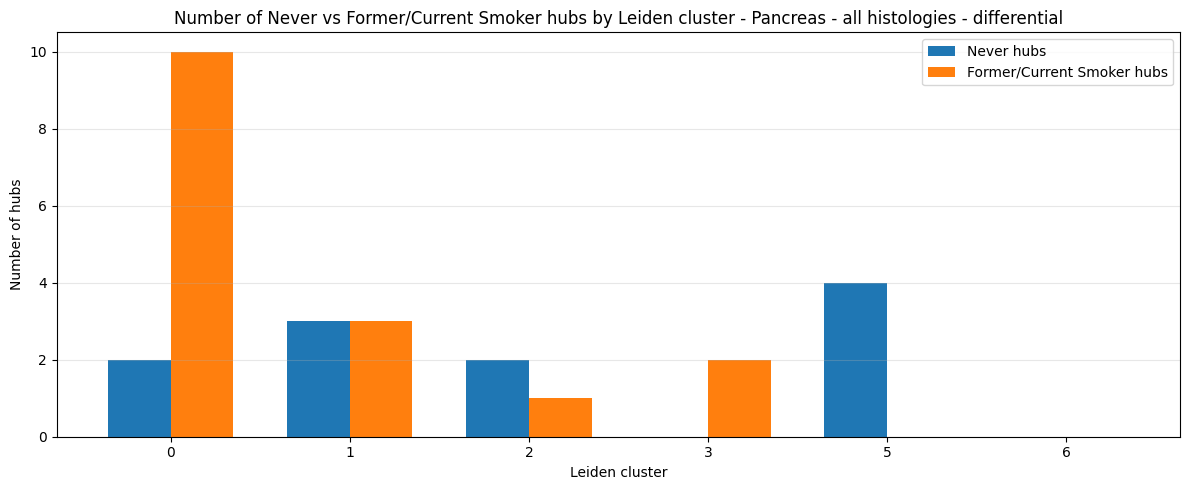

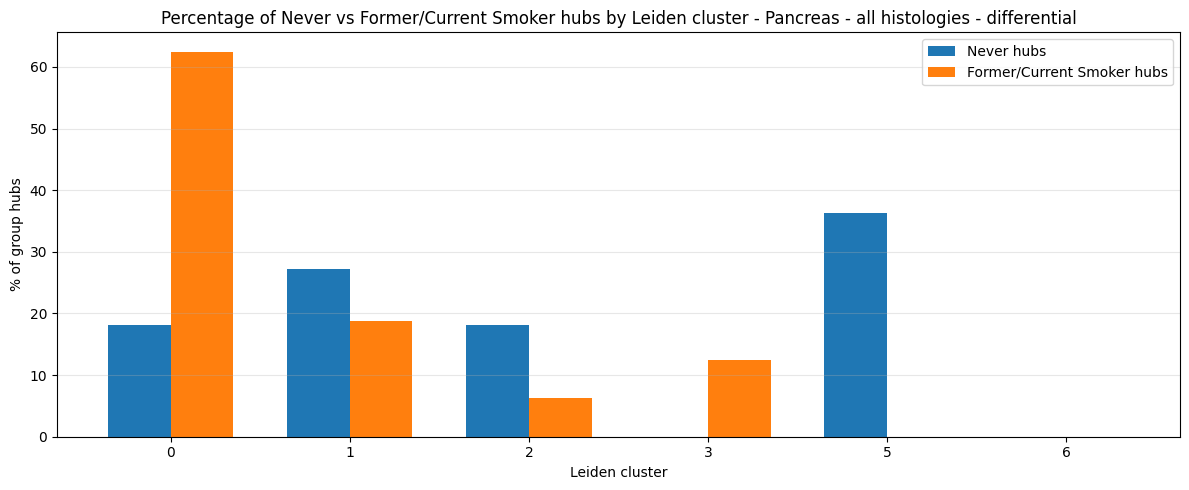


Saved long table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_smoking_hub_counts_by_cluster_long.csv

Saved wide readable table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_smoking_hub_counts_by_cluster_wide.csv

Saved focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_smoking_hub_counts_clusters_1_2.csv

Nota finale:
La tabella conta gli hub Never e Former/Current Smoker nei cluster Leiden usando PANCREAS_ALL. L'istologia originale non viene usata per dividere i pazienti.


In [27]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# HUB COUNTS AND PERCENTAGES BY LEIDEN CLUSTER
# Never vs Former/Current Smoker
# PANCREAS_ALL
#
# Obiettivo:
# - contare quanti hub Never e Former/Current Smoker cadono in ogni cluster Leiden
# - calcolare le percentuali rispetto al totale degli hub del gruppo
# - calcolare le percentuali rispetto alla dimensione del cluster
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Parameters
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

NEVER_LABEL = "Never"
SMOKER_LABEL = "Former/Current Smoker"

smoking_groups = [
    NEVER_LABEL,
    SMOKER_LABEL
]

# Scegli quale analisi usare:
# "differential" = geni più rappresentativi Never vs Former/Current Smoker
# "separate" = top hub genes presi separatamente da Never e Former/Current Smoker
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"


base_dir = (
        data_dir
        / "clinical_to_network_smoking_pancreas_all"
)

mapping_dir = (
        base_dir
        / "hub_genes_cluster_mapping"
)

output_dir = (
        mapping_dir
        / "readable_hub_counts_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file in questo ordine:
    1. path candidati espliciti;
    2. ricerca automatica con glob nella cartella indicata.
    """

    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica i cluster Leiden per PANCREAS_ALL.
    Prima prova a usare la variabile clusters già in memoria.
    Altrimenti cerca il CSV salvato.
    """

    if "clusters" in globals():
        print("Uso clusters già presente in memoria.")
        clusters_df = globals()["clusters"].copy()
        return clusters_df, "memory: clusters"

    candidate_paths = [
        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters_by_pancreas_all"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_all_oncotree_groups.csv",

        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    return clusters_df, found_path


def load_mapped_hub_file():
    """
    Carica il file già prodotto dalla cella precedente:
    hub genes -> Leiden clusters.
    """

    if ANALYSIS_MODE == "differential":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_differential_smoking_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        patterns = [
            f"*{PANCREAS_GROUP}*differential*never*former*current*smoker*hub*genes*mapped*leiden*.csv",
            "*differential*smoking*hub*genes*mapped*leiden*.csv",
            "*differential*never*former*current*smoker*mapped*leiden*.csv",
        ]

    elif ANALYSIS_MODE == "separate":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_separate_never_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_never_vs_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_smoking_top_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        patterns = [
            f"*{PANCREAS_GROUP}*separate*never*former*current*smoker*top*hub*genes*mapped*leiden*.csv",
            "*separate*smoking*top*hub*genes*mapped*leiden*.csv",
            "*separate*never*former*current*smoker*mapped*leiden*.csv",
        ]

    else:
        raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

    found_path = find_existing_file(
        candidate_paths=candidate_mapped_paths,
        search_dir=mapping_dir,
        patterns=patterns,
        description=f"{ANALYSIS_MODE} mapped hub genes for PANCREAS_ALL"
    )

    if found_path is None:
        print("Nessun file mapped trovato. Ho cercato questi path:")
        for path in candidate_mapped_paths:
            print(path)

        raise FileNotFoundError(
            "File di mapping hub genes -> Leiden clusters non trovato. "
            "Controlla il nome del file nella cartella hub_genes_cluster_mapping."
        )

    mapped_df = pd.read_csv(found_path, low_memory=False)
    return mapped_df, found_path


# ============================================================
# 2. Load files
# ============================================================

clusters, clusters_path = load_leiden_clusters()
mapped, mapped_path = load_mapped_hub_file()

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()


# ============================================================
# 3. Normalize columns
# ============================================================

clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree_Group": "ONCOTREE_CODE"
})

mapped = mapped.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "Oncotree_Group": "ONCOTREE_CODE",
    "SMOKING_GROUP": "smoking_group",
    "Smoking_Group": "smoking_group"
})

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file clusters: {missing_cluster_cols}\n"
        f"Colonne disponibili: {clusters.columns.tolist()}"
    )

required_mapped_cols = {
    "Gene",
    "Cluster"
}

missing_mapped_cols = required_mapped_cols - set(mapped.columns)

if missing_mapped_cols:
    raise ValueError(
        f"Colonne mancanti nel file mapped: {missing_mapped_cols}\n"
        f"Colonne disponibili: {mapped.columns.tolist()}"
    )


# Se il file clusters contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in clusters.columns:
    clusters_pancreas = clusters[
        clusters["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not clusters_pancreas.empty:
        clusters = clusters_pancreas.copy()

# Se il file mapped contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in mapped.columns:
    mapped_pancreas = mapped[
        mapped["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not mapped_pancreas.empty:
        mapped = mapped_pancreas.copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("Loaded clusters file:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)

print("\nClusters loaded:")
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().astype(int).unique()))

print("\nMapped hub genes loaded:")
print("Rows:", mapped.shape[0])
print("Genes:", mapped["Gene"].nunique())


# ============================================================
# 4. Identify hub group: Never or Former/Current Smoker
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo Never oppure Former/Current Smoker.

    Funziona con colonne come:
    - Signature_Group
    - Hub_List_Group
    - smoking_group
    - Network_Group
    - Signature
    - Delta_HubScore_never_minus_former_current_smoker
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "smoking_group",
        "Smoking_Group",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    # Never
    never_patterns = [
        "never-enriched",
        "never enriched",
        "top never",
        "never hub",
        "never network",
        "never"
    ]

    # Former/Current Smoker
    smoker_patterns = [
        "former/current smoker",
        "former current smoker",
        "former_current_smoker",
        "former-current-smoker",
        "current smoker",
        "former smoker",
        "smoker-enriched",
        "smoker enriched",
        "smoker network",
        "top former",
        "top smoker"
    ]

    has_never = any(pattern in text for pattern in never_patterns)
    has_smoker = any(pattern in text for pattern in smoker_patterns)

    if has_never and not has_smoker:
        return NEVER_LABEL

    if has_smoker and not has_never:
        return SMOKER_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, il segno indica il gruppo.
    delta_col = "Delta_HubScore_never_minus_former_current_smoker"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return NEVER_LABEL
            elif delta_value < 0:
                return SMOKER_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group"]
).copy()

# Tengo solo geni effettivamente trovati nei cluster Leiden
mapped_in_clusters = mapped.dropna(subset=["Cluster"]).copy()
mapped_in_clusters["Cluster"] = mapped_in_clusters["Cluster"].astype(int)


# ============================================================
# 5. Cluster size
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 6. Count hubs by smoking group and cluster
# ============================================================

# Totale hub per gruppo, considerando solo quelli mappati nei cluster
total_hubs_by_group = (
    mapped_in_clusters
    .groupby("Hub_Group")
    .agg(
        total_hubs_group=("Gene", "nunique")
    )
    .reset_index()
)

hub_counts_long = (
    mapped_in_clusters
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
    )
    .reset_index()
)

hub_counts_long = hub_counts_long.merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_long = hub_counts_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

# Percentuale rispetto al totale degli hub del gruppo
# Esempio: quanti hub Never cadono nel cluster 1 rispetto a tutti gli hub Never?
hub_counts_long["pct_of_group_hubs"] = np.where(
    hub_counts_long["total_hubs_group"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["total_hubs_group"] * 100,
    0
).round(2)

# Percentuale rispetto alla dimensione del cluster
# Esempio: quanti geni del cluster 1 sono hub Never?
hub_counts_long["pct_of_cluster_genes"] = np.where(
    hub_counts_long["cluster_size_genes"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["cluster_size_genes"] * 100,
    0
).round(2)

hub_counts_long = hub_counts_long.sort_values(
    ["Cluster", "Hub_Group"]
).reset_index(drop=True)


# ============================================================
# 7. Wide table: easier to read Never vs Former/Current Smoker
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [smoking_groups, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

hub_counts_complete = all_combinations.merge(
    hub_counts_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

hub_counts_complete = hub_counts_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

hub_counts_complete["cluster_size_genes"] = (
    hub_counts_complete["cluster_size_genes"]
    .fillna(hub_counts_complete["cluster_size_genes_from_clusters"])
)

hub_counts_complete = hub_counts_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

hub_counts_complete["n_hubs"] = hub_counts_complete["n_hubs"].fillna(0).astype(int)
hub_counts_complete["genes"] = hub_counts_complete["genes"].fillna("-")

# Riaggiungo i totali per calcolare percentuali anche dove n_hubs = 0
hub_counts_complete = hub_counts_complete.drop(
    columns=["total_hubs_group"],
    errors="ignore"
).merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_complete["total_hubs_group"] = (
    hub_counts_complete["total_hubs_group"]
    .fillna(0)
)

hub_counts_complete["pct_of_group_hubs"] = np.where(
    hub_counts_complete["total_hubs_group"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["total_hubs_group"] * 100,
    0
).round(2)

hub_counts_complete["pct_of_cluster_genes"] = np.where(
    hub_counts_complete["cluster_size_genes"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["cluster_size_genes"] * 100,
    0
).round(2)


# ============================================================
# 8. Build wide table with clean column names
# ============================================================

group_prefix = {
    NEVER_LABEL: "Never",
    SMOKER_LABEL: "Former_Current_Smoker"
}

wide_parts = []

for group in smoking_groups:

    prefix = group_prefix[group]

    tmp = hub_counts_complete[
        hub_counts_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "pct_of_group_hubs",
            "pct_of_cluster_genes",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "pct_of_group_hubs": f"{prefix}_pct_of_group_hubs",
        "pct_of_cluster_genes": f"{prefix}_pct_of_cluster_genes",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

hub_counts_wide = cluster_sizes.copy()

for tmp in wide_parts:
    hub_counts_wide = hub_counts_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

hub_counts_wide = hub_counts_wide.fillna({
    "Never_n_hubs": 0,
    "Never_pct_of_group_hubs": 0,
    "Never_pct_of_cluster_genes": 0,
    "Never_genes": "-",
    "Former_Current_Smoker_n_hubs": 0,
    "Former_Current_Smoker_pct_of_group_hubs": 0,
    "Former_Current_Smoker_pct_of_cluster_genes": 0,
    "Former_Current_Smoker_genes": "-"
})

hub_counts_wide["Never_n_hubs"] = hub_counts_wide["Never_n_hubs"].astype(int)
hub_counts_wide["Former_Current_Smoker_n_hubs"] = (
    hub_counts_wide["Former_Current_Smoker_n_hubs"]
    .astype(int)
)

hub_counts_wide["Delta_n_hubs_Never_minus_Former_Current_Smoker"] = (
        hub_counts_wide["Never_n_hubs"]
        - hub_counts_wide["Former_Current_Smoker_n_hubs"]
)

hub_counts_wide["Delta_pct_group_Never_minus_Former_Current_Smoker"] = (
        hub_counts_wide["Never_pct_of_group_hubs"]
        - hub_counts_wide["Former_Current_Smoker_pct_of_group_hubs"]
).round(2)

hub_counts_wide = hub_counts_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 9. Focus on prognostic clusters 1 and 2
# ============================================================

clusters_of_interest = [1, 2]

hub_counts_focus = hub_counts_wide[
    hub_counts_wide["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 10. Display results
# ============================================================

pd.set_option("display.max_colwidth", 200)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "Never_n_hubs",
    "Never_pct_of_group_hubs",
    "Former_Current_Smoker_n_hubs",
    "Former_Current_Smoker_pct_of_group_hubs",
    "Delta_n_hubs_Never_minus_Former_Current_Smoker",
    "Delta_pct_group_Never_minus_Former_Current_Smoker",
    "Never_genes",
    "Former_Current_Smoker_genes"
]

print("\n" + "=" * 120)
print(f"HUB COUNTS BY CLUSTER - {ANALYSIS_MODE.upper()} HUB LIST - {PANCREAS_GROUP}")
print("=" * 120)

safe_display(hub_counts_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(hub_counts_focus[display_cols])


# ============================================================
# 11. Plot: number of hubs by cluster
# ============================================================
# Questo grafico resta GENERALE, quindi mostra tutti i cluster.

plot_df = hub_counts_wide[
    [
        "Cluster",
        "Never_n_hubs",
        "Former_Current_Smoker_n_hubs"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Never_n_hubs"],
    width,
    label="Never hubs"
)

plt.bar(
    x + width / 2,
    plot_df["Former_Current_Smoker_n_hubs"],
    width,
    label="Former/Current Smoker hubs"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Number of hubs")
plt.title(
    f"Number of Never vs Former/Current Smoker hubs "
    f"by Leiden cluster - {PANCREAS_LABEL} - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. Plot: percentage of group hubs by cluster
# ============================================================
# Anche questo grafico resta GENERALE, quindi mostra tutti i cluster.

plot_pct_df = hub_counts_wide[
    [
        "Cluster",
        "Never_pct_of_group_hubs",
        "Former_Current_Smoker_pct_of_group_hubs"
    ]
].copy()

x = np.arange(len(plot_pct_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_pct_df["Never_pct_of_group_hubs"],
    width,
    label="Never hubs"
)

plt.bar(
    x + width / 2,
    plot_pct_df["Former_Current_Smoker_pct_of_group_hubs"],
    width,
    label="Former/Current Smoker hubs"
)

plt.xticks(x, plot_pct_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("% of group hubs")
plt.title(
    f"Percentage of Never vs Former/Current Smoker hubs "
    f"by Leiden cluster - {PANCREAS_LABEL} - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Save outputs
# ============================================================

long_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_smoking_hub_counts_by_cluster_long.csv"
)

wide_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_smoking_hub_counts_by_cluster_wide.csv"
)

focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_smoking_hub_counts_clusters_1_2.csv"
)

hub_counts_long.to_csv(long_output, index=False)
hub_counts_wide.to_csv(wide_output, index=False)
hub_counts_focus.to_csv(focus_output, index=False)

print("\nSaved long table:")
print(long_output)

print("\nSaved wide readable table:")
print(wide_output)

print("\nSaved focus table for clusters 1 and 2:")
print(focus_output)


# ============================================================
# 14. Compatibility aliases
# ============================================================

hub_counts_long_pancreas_smoking = hub_counts_long
hub_counts_wide_pancreas_smoking = hub_counts_wide
hub_counts_focus_pancreas_smoking = hub_counts_focus

print("\nNota finale:")
print(
    "La tabella conta gli hub Never e Former/Current Smoker nei cluster Leiden "
    "usando PANCREAS_ALL. L'istologia originale non viene usata per dividere i pazienti."
)

Uso clusters già presente in memoria.

Searching for differential smoking mapped hub genes for PANCREAS_ALL...
Candidate: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv
Found: data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv

Loaded clusters:
memory: clusters

Loaded mapped hub file:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv

Clusters loaded:
Rows: 40
Genes: 40
Clusters: [0, 1, 2, 3, 5, 6]

Mapped hub genes loaded:
Rows: 40
Genes: 40

WEIGHTED HUB DISTRIBUTION BY CLUSTER - PANCREAS_ALL - DIFFERENTIAL - RANK_INVERSE


,Cluster,cluster_size_genes,Never_n_hubs,Never_weighted_pct,Former_Current_Smoker_n_hubs,Former_Current_Smoker_weighted_pct,Delta_weighted_pct_Never_minus_Former_Current_Smoker,Never_best_rank,Former_Current_Smoker_best_rank,Never_genes,Former_Current_Smoker_genes
0,0,13,2,11.59,10,81.00,-69.41,4.0,1.0,"BAP1, PTPRD","ATM, BRCA2, CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, SMAD2, TEK"
1,1,6,3,42.75,3,8.77,33.98,1.0,8.0,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
2,2,4,2,14.72,1,2.46,12.26,3.0,12.0,"KDM6A, RNF43",ARID1A
3,3,4,0,0.00,2,7.76,-7.76,NaN,5.0,-,"PREX2, SMAD4"
4,5,4,4,30.95,0,0.00,30.95,2.0,NaN,"AGO2, MYC, RAD21, RECQL4",-
5,6,2,0,0.00,0,0.00,0.00,NaN,NaN,-,-



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2


,Cluster,cluster_size_genes,Never_n_hubs,Never_weighted_pct,Former_Current_Smoker_n_hubs,Former_Current_Smoker_weighted_pct,Delta_weighted_pct_Never_minus_Former_Current_Smoker,Never_best_rank,Former_Current_Smoker_best_rank,Never_genes,Former_Current_Smoker_genes
1,1,6,3,42.75,3,8.77,33.98,1.0,8.0,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
2,2,4,2,14.72,1,2.46,12.26,3.0,12.0,"KDM6A, RNF43",ARID1A



WEIGHTED GENE DETAIL - CLUSTERS 1 AND 2


,Hub_Group,Gene,Cluster,HubScore_for_weight,Hub_rank_in_group,raw_weight,normalized_weight,Signature_Group,Delta_HubScore_never_minus_former_current_smoker,Abs_Delta_HubScore,HubScore_never,HubScore_former_current_smoker,Degree_never,Degree_former_current_smoker,Node_Strength_never,Node_Strength_former_current_smoker
7,Former/Current Smoker,TP53,1,0.680556,8,0.125000,3.6974,Former/Current Smoker-enriched hub genes,0.069444,0.069444,0.750000,0.680556,5.0,4.0,13.701363,9.819128
9,Former/Current Smoker,CCNE1,1,0.506944,10,0.100000,2.9579,Former/Current Smoker-enriched hub genes,-0.180021,0.180021,0.326923,0.506944,1.0,2.0,6.542877,9.548736
11,Former/Current Smoker,ARID1A,2,0.430556,12,0.083333,2.4650,Former/Current Smoker-enriched hub genes,-0.430556,0.430556,NaN,0.430556,NaN,2.0,NaN,3.857134
13,Former/Current Smoker,CEBPA,1,0.243056,14,0.071429,2.1128,Former/Current Smoker-enriched hub genes,0.090278,0.090278,0.333333,0.243056,1.0,1.0,6.718166,6.671482
16,Never,AKT2,1,0.891026,1,1.000000,33.1139,Never-enriched hub genes,0.891026,0.891026,0.891026,NaN,7.0,NaN,26.296795,NaN
18,Never,KDM6A,2,0.762821,3,0.333333,11.0380,Never-enriched hub genes,0.512821,0.512821,0.762821,0.250000,6.0,1.0,12.256393,1.302563
20,Never,KEAP1,1,0.528846,5,0.200000,6.6228,Never-enriched hub genes,0.528846,0.528846,0.528846,NaN,3.0,NaN,5.847227,NaN
24,Never,RNF43,2,0.387821,9,0.111111,3.6793,Never-enriched hub genes,0.387821,0.387821,0.387821,NaN,2.0,NaN,5.254632,NaN
26,Never,KMT2B,1,0.307692,11,0.090909,3.0104,Never-enriched hub genes,0.307692,0.307692,0.307692,NaN,1.0,NaN,5.815917,NaN


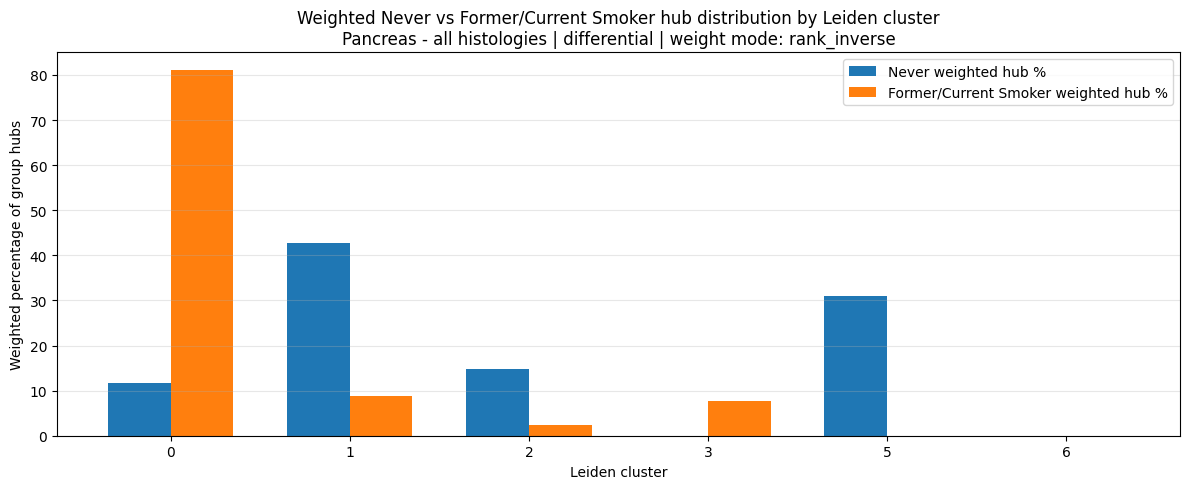

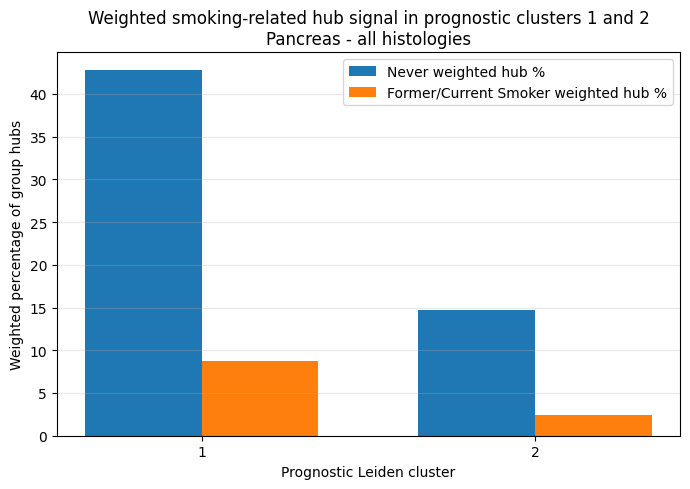


Saved weighted long table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_smoking_weighted_hub_distribution_long.csv

Saved weighted wide table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_smoking_weighted_hub_distribution_wide.csv

Saved weighted focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_smoking_weighted_hub_distribution_clusters_1_2.csv

Saved weighted gene detail:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_smoking_weighted_gene_detail.csv

Saved weighted gene detail for clusters 1 and 2:
data_pancreas\cli

In [28]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER
# Never vs Former/Current Smoker
# PANCREAS_ALL
#
# Idea:
# - non conto solo quanti hub cadono in ogni cluster
# - do più peso agli hub più importanti
# - il peso diminuisce man mano che l'HubScore/rank peggiora
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Settings
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

NEVER_LABEL = "Never"
SMOKER_LABEL = "Former/Current Smoker"

SMOKING_GROUPS = [
    NEVER_LABEL,
    SMOKER_LABEL
]

# Scegli quale lista usare:
# "differential" = geni più rappresentativi Never vs Former/Current Smoker
# "separate" = top hub presi separatamente da Never e Former/Current Smoker
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

# Tipo di peso:
# "hubscore" = usa direttamente HubScore normalizzato
# "rank_inverse" = peso = 1 / rank, quindi il primo pesa molto più degli ultimi
# "rank_linear" = peso decresce linearmente dal primo all'ultimo
WEIGHT_MODE = "rank_inverse"
# WEIGHT_MODE = "hubscore"
# WEIGHT_MODE = "rank_linear"

smoking_base_dir = (
        data_dir
        / "clinical_to_network_smoking_pancreas_all"
)

mapping_dir = (
        smoking_base_dir
        / "hub_genes_cluster_mapping"
)

output_dir = (
        mapping_dir
        / "weighted_hub_distribution_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica i cluster Leiden per PANCREAS_ALL.
    Prima prova a usare la variabile clusters già in memoria.
    Altrimenti cerca automaticamente il CSV salvato.
    """

    if "clusters" in globals():
        print("Uso clusters già presente in memoria.")
        clusters_df = globals()["clusters"].copy()
        return clusters_df, "memory: clusters"

    candidate_paths = [
        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters_by_pancreas_all"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_all_oncotree_groups.csv",

        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    return clusters_df, found_path


def load_mapped_hub_file():
    """
    Carica il file mapped hub genes -> Leiden clusters
    prodotto dalla cella precedente.
    """

    if ANALYSIS_MODE == "differential":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_differential_never_vs_former_current_smoker_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_differential_smoking_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        mapped_patterns = [
            f"*{PANCREAS_GROUP}*differential*never*former*current*smoker*hub_genes_mapped_to_leiden_clusters.csv",
            f"*{PANCREAS_GROUP}*differential*smoking*hub_genes_mapped_to_leiden_clusters.csv",
            "*differential*smoking*hub_genes_mapped_to_leiden_clusters.csv",
            "*differential*never*former*current*smoker*clusters*.csv",
            "*differential*smoking*clusters*.csv",
        ]

    elif ANALYSIS_MODE == "separate":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_separate_never_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_never_vs_former_current_smoker_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_smoking_top_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        mapped_patterns = [
            f"*{PANCREAS_GROUP}*separate*never*former*current*smoker*top_hub_genes_mapped_to_leiden_clusters.csv",
            f"*{PANCREAS_GROUP}*separate*smoking*top_hub_genes_mapped_to_leiden_clusters.csv",
            "*separate*smoking*top_hub_genes_mapped_to_leiden_clusters.csv",
            "*separate*never*former*current*smoker*clusters*.csv",
            "*separate*smoking*clusters*.csv",
        ]

    else:
        raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

    mapped_path = find_existing_file(
        candidate_paths=candidate_mapped_paths,
        search_dir=mapping_dir,
        patterns=mapped_patterns,
        description=f"{ANALYSIS_MODE} smoking mapped hub genes for PANCREAS_ALL"
    )

    if mapped_path is None:
        raise FileNotFoundError(
            "Non trovo il file mapped hub genes -> Leiden clusters per smoking.\n"
            "Prima devi eseguire la cella che mappa gli hub smoking sui cluster Leiden.\n"
            f"Cartella cercata:\n{mapping_dir}"
        )

    mapped_df = pd.read_csv(mapped_path, low_memory=False)

    return mapped_df, mapped_path


# ============================================================
# 1. Load files
# ============================================================

clusters, clusters_path = load_leiden_clusters()
mapped, mapped_path = load_mapped_hub_file()

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()


# ============================================================
# 2. Normalize columns
# ============================================================

clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree_Group": "ONCOTREE_CODE"
})

mapped = mapped.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "Oncotree_Group": "ONCOTREE_CODE",
    "SMOKING_GROUP": "smoking_group",
    "Smoking_Group": "smoking_group"
})

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file clusters: {missing_cluster_cols}\n"
        f"Colonne disponibili: {clusters.columns.tolist()}"
    )

required_mapped_cols = {
    "Gene",
    "Cluster"
}

missing_mapped_cols = required_mapped_cols - set(mapped.columns)

if missing_mapped_cols:
    raise ValueError(
        f"Colonne mancanti nel file mapped: {missing_mapped_cols}\n"
        f"Colonne disponibili: {mapped.columns.tolist()}"
    )


# Se il file clusters contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in clusters.columns:
    clusters_pancreas = clusters[
        clusters["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not clusters_pancreas.empty:
        clusters = clusters_pancreas.copy()

# Se il file mapped contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in mapped.columns:
    mapped_pancreas = mapped[
        mapped["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not mapped_pancreas.empty:
        mapped = mapped_pancreas.copy()


clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("\nLoaded clusters:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)

print("\nClusters loaded:")
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().astype(int).unique()))

print("\nMapped hub genes loaded:")
print("Rows:", mapped.shape[0])
print("Genes:", mapped["Gene"].nunique())


# ============================================================
# 3. Identify Never / Former/Current Smoker group
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo Never oppure Former/Current Smoker.
    Funziona sia per:
    - differential mapped table
    - separate top hub mapped table
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "smoking_group",
        "Smoking_Group",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    never_patterns = [
        "never-enriched",
        "never enriched",
        "top never",
        "never hub",
        "never network",
        "never"
    ]

    smoker_patterns = [
        "former/current smoker",
        "former current smoker",
        "former_current_smoker",
        "former-current-smoker",
        "current smoker",
        "former smoker",
        "smoker-enriched",
        "smoker enriched",
        "smoker network",
        "top former",
        "top smoker"
    ]

    has_never = any(pattern in text for pattern in never_patterns)
    has_smoker = any(pattern in text for pattern in smoker_patterns)

    if has_never and not has_smoker:
        return NEVER_LABEL

    if has_smoker and not has_never:
        return SMOKER_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, uso il segno del delta
    delta_col = "Delta_HubScore_never_minus_former_current_smoker"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return NEVER_LABEL
            elif delta_value < 0:
                return SMOKER_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group", "Cluster"]
).copy()

mapped["Cluster"] = mapped["Cluster"].astype(int)


# ============================================================
# 4. Select correct HubScore for each row
# ============================================================

def get_group_hubscore(row):
    """
    Per differential:
    - Never usa HubScore_never
    - Former/Current Smoker usa HubScore_former_current_smoker

    Per separate:
    - usa HubScore
    """

    group = row["Hub_Group"]

    if group == NEVER_LABEL:
        if "HubScore_never" in row.index and pd.notna(row["HubScore_never"]):
            return row["HubScore_never"]

    if group == SMOKER_LABEL:
        if (
                "HubScore_former_current_smoker" in row.index
                and pd.notna(row["HubScore_former_current_smoker"])
        ):
            return row["HubScore_former_current_smoker"]

    if "HubScore" in row.index and pd.notna(row["HubScore"]):
        return row["HubScore"]

    if "Abs_Delta_HubScore" in row.index and pd.notna(row["Abs_Delta_HubScore"]):
        return row["Abs_Delta_HubScore"]

    return np.nan


mapped["HubScore_for_weight"] = mapped.apply(get_group_hubscore, axis=1)

mapped["HubScore_for_weight"] = pd.to_numeric(
    mapped["HubScore_for_weight"],
    errors="coerce"
)

mapped = mapped.dropna(
    subset=["HubScore_for_weight"]
).copy()

if mapped.empty:
    raise ValueError(
        "Dopo il filtro HubScore_for_weight, la tabella mapped è vuota. "
        "Controlla che il file mapped contenga HubScore_never / "
        "HubScore_former_current_smoker oppure HubScore."
    )


# ============================================================
# 5. Rank hubs within each group and assign weight
# ============================================================

mapped = mapped.sort_values(
    ["Hub_Group", "HubScore_for_weight"],
    ascending=[True, False]
).copy()

mapped["Hub_rank_in_group"] = (
    mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

mapped["n_hubs_in_group"] = (
    mapped
    .groupby("Hub_Group")["Gene"]
    .transform("nunique")
)


def assign_weight(row):
    rank = row["Hub_rank_in_group"]
    n = row["n_hubs_in_group"]
    hubscore = row["HubScore_for_weight"]

    if WEIGHT_MODE == "hubscore":
        return hubscore

    if WEIGHT_MODE == "rank_inverse":
        return 1 / rank

    if WEIGHT_MODE == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("WEIGHT_MODE non valido.")


mapped["raw_weight"] = mapped.apply(assign_weight, axis=1)

# Normalizzo i pesi dentro ciascun gruppo:
# la somma dei pesi Never = 100
# la somma dei pesi Former/Current Smoker = 100
mapped["normalized_weight"] = (
        mapped["raw_weight"]
        / mapped.groupby("Hub_Group")["raw_weight"].transform("sum")
        * 100
)

mapped["normalized_weight"] = mapped["normalized_weight"].round(4)


# ============================================================
# 6. Cluster sizes
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 7. Weighted summary by group and cluster
# ============================================================

weighted_long = (
    mapped
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        weighted_hub_score=("normalized_weight", "sum"),
        mean_hubscore=("HubScore_for_weight", "mean"),
        max_hubscore=("HubScore_for_weight", "max"),
        best_rank=("Hub_rank_in_group", "min"),
        genes=(
            "Gene",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
)

weighted_long["weighted_hub_score"] = weighted_long["weighted_hub_score"].round(2)
weighted_long["mean_hubscore"] = weighted_long["mean_hubscore"].round(4)
weighted_long["max_hubscore"] = weighted_long["max_hubscore"].round(4)

weighted_long = weighted_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

weighted_long["pct_cluster_covered_by_hubs"] = np.where(
    weighted_long["cluster_size_genes"] > 0,
    weighted_long["n_hubs"] / weighted_long["cluster_size_genes"] * 100,
    0
).round(2)

weighted_long = weighted_long.sort_values(
    ["Hub_Group", "weighted_hub_score"],
    ascending=[True, False]
).reset_index(drop=True)


# ============================================================
# 8. Wide readable table
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [SMOKING_GROUPS, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

weighted_complete = all_combinations.merge(
    weighted_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

weighted_complete = weighted_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

weighted_complete["cluster_size_genes"] = (
    weighted_complete["cluster_size_genes"]
    .fillna(weighted_complete["cluster_size_genes_from_clusters"])
)

weighted_complete = weighted_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

fill_zero_cols = [
    "n_hubs",
    "weighted_hub_score",
    "mean_hubscore",
    "max_hubscore",
    "pct_cluster_covered_by_hubs"
]

for col in fill_zero_cols:
    if col in weighted_complete.columns:
        weighted_complete[col] = weighted_complete[col].fillna(0)

weighted_complete["best_rank"] = weighted_complete["best_rank"].fillna(np.nan)
weighted_complete["genes"] = weighted_complete["genes"].fillna("-")


group_prefix = {
    NEVER_LABEL: "Never",
    SMOKER_LABEL: "Former_Current_Smoker"
}

wide_parts = []

for group in SMOKING_GROUPS:

    prefix = group_prefix[group]

    tmp = weighted_complete[
        weighted_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "weighted_hub_score",
            "mean_hubscore",
            "max_hubscore",
            "best_rank",
            "pct_cluster_covered_by_hubs",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "weighted_hub_score": f"{prefix}_weighted_pct",
        "mean_hubscore": f"{prefix}_mean_hubscore",
        "max_hubscore": f"{prefix}_max_hubscore",
        "best_rank": f"{prefix}_best_rank",
        "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

weighted_wide = cluster_sizes.copy()

for tmp in wide_parts:
    weighted_wide = weighted_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

weighted_wide = weighted_wide.fillna({
    "Never_n_hubs": 0,
    "Never_weighted_pct": 0,
    "Never_mean_hubscore": 0,
    "Never_max_hubscore": 0,
    "Never_pct_cluster_covered": 0,
    "Never_genes": "-",
    "Former_Current_Smoker_n_hubs": 0,
    "Former_Current_Smoker_weighted_pct": 0,
    "Former_Current_Smoker_mean_hubscore": 0,
    "Former_Current_Smoker_max_hubscore": 0,
    "Former_Current_Smoker_pct_cluster_covered": 0,
    "Former_Current_Smoker_genes": "-"
})

weighted_wide["Never_n_hubs"] = weighted_wide["Never_n_hubs"].astype(int)
weighted_wide["Former_Current_Smoker_n_hubs"] = (
    weighted_wide["Former_Current_Smoker_n_hubs"]
    .astype(int)
)

weighted_wide["Delta_weighted_pct_Never_minus_Former_Current_Smoker"] = (
        weighted_wide["Never_weighted_pct"]
        - weighted_wide["Former_Current_Smoker_weighted_pct"]
).round(2)

weighted_wide["Delta_n_hubs_Never_minus_Former_Current_Smoker"] = (
        weighted_wide["Never_n_hubs"]
        - weighted_wide["Former_Current_Smoker_n_hubs"]
)

weighted_wide = weighted_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 9. Add ranked genes with weights for easier inspection
# ============================================================

weighted_gene_detail = mapped[
    [
        "Hub_Group",
        "Gene",
        "Cluster",
        "HubScore_for_weight",
        "Hub_rank_in_group",
        "raw_weight",
        "normalized_weight"
    ]
].copy()

extra_cols = [
    "Signature_Group",
    "Hub_List_Group",
    "Delta_HubScore_never_minus_former_current_smoker",
    "Abs_Delta_HubScore",
    "HubScore_never",
    "HubScore_former_current_smoker",
    "Degree_never",
    "Degree_former_current_smoker",
    "Node_Strength_never",
    "Node_Strength_former_current_smoker"
]

for col in extra_cols:
    if col in mapped.columns:
        weighted_gene_detail[col] = mapped[col]

weighted_gene_detail = weighted_gene_detail.sort_values(
    ["Hub_Group", "Hub_rank_in_group"]
).reset_index(drop=True)


# ============================================================
# 10. Focus on prognostic clusters 1 and 2
# ============================================================

clusters_of_interest = [1, 2]

weighted_focus = weighted_wide[
    weighted_wide["Cluster"].isin(clusters_of_interest)
].copy()

weighted_gene_focus = weighted_gene_detail[
    weighted_gene_detail["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 11. Display results
# ============================================================

pd.set_option("display.max_colwidth", 220)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "Never_n_hubs",
    "Never_weighted_pct",
    "Former_Current_Smoker_n_hubs",
    "Former_Current_Smoker_weighted_pct",
    "Delta_weighted_pct_Never_minus_Former_Current_Smoker",
    "Never_best_rank",
    "Former_Current_Smoker_best_rank",
    "Never_genes",
    "Former_Current_Smoker_genes"
]

print("\n" + "=" * 120)
print(
    f"WEIGHTED HUB DISTRIBUTION BY CLUSTER - "
    f"{PANCREAS_GROUP} - {ANALYSIS_MODE.upper()} - {WEIGHT_MODE.upper()}"
)
print("=" * 120)

safe_display(weighted_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(weighted_focus[display_cols])

print("\n" + "=" * 120)
print("WEIGHTED GENE DETAIL - CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(weighted_gene_focus)


# ============================================================
# 12. Plot weighted percentage by cluster
# ============================================================
# Questo grafico resta generale: mostra tutti i cluster.

plot_df = weighted_wide[
    [
        "Cluster",
        "Never_weighted_pct",
        "Former_Current_Smoker_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Never_weighted_pct"],
    width,
    label="Never weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_df["Former_Current_Smoker_weighted_pct"],
    width,
    label="Former/Current Smoker weighted hub %"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title(
    f"Weighted Never vs Former/Current Smoker hub distribution by Leiden cluster\n"
    f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {WEIGHT_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Plot focus clusters 1 and 2
# ============================================================
# Questo è il secondo grafico, limitato ai cluster 1 e 2.

plot_focus = weighted_focus[
    [
        "Cluster",
        "Never_weighted_pct",
        "Former_Current_Smoker_weighted_pct"
    ]
].copy()

if not plot_focus.empty:

    x = np.arange(len(plot_focus))
    width = 0.35

    plt.figure(figsize=(7, 5))

    plt.bar(
        x - width / 2,
        plot_focus["Never_weighted_pct"],
        width,
        label="Never weighted hub %"
    )

    plt.bar(
        x + width / 2,
        plot_focus["Former_Current_Smoker_weighted_pct"],
        width,
        label="Former/Current Smoker weighted hub %"
    )

    plt.xticks(x, plot_focus["Cluster"])
    plt.xlabel("Prognostic Leiden cluster")
    plt.ylabel("Weighted percentage of group hubs")
    plt.title(
        "Weighted smoking-related hub signal in prognostic clusters 1 and 2\n"
        f"{PANCREAS_LABEL}"
    )
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Nessun cluster 1 o 2 trovato nei risultati weighted_focus.")


# ============================================================
# 14. Save outputs
# ============================================================

weighted_long_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_smoking_weighted_hub_distribution_long.csv"
)

weighted_wide_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_smoking_weighted_hub_distribution_wide.csv"
)

weighted_focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_smoking_weighted_hub_distribution_clusters_1_2.csv"
)

weighted_gene_detail_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_smoking_weighted_gene_detail.csv"
)

weighted_gene_focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_smoking_weighted_gene_detail_clusters_1_2.csv"
)

weighted_long.to_csv(weighted_long_output, index=False)
weighted_wide.to_csv(weighted_wide_output, index=False)
weighted_focus.to_csv(weighted_focus_output, index=False)
weighted_gene_detail.to_csv(weighted_gene_detail_output, index=False)
weighted_gene_focus.to_csv(weighted_gene_focus_output, index=False)

print("\nSaved weighted long table:")
print(weighted_long_output)

print("\nSaved weighted wide table:")
print(weighted_wide_output)

print("\nSaved weighted focus table for clusters 1 and 2:")
print(weighted_focus_output)

print("\nSaved weighted gene detail:")
print(weighted_gene_detail_output)

print("\nSaved weighted gene detail for clusters 1 and 2:")
print(weighted_gene_focus_output)


# ============================================================
# 15. Compatibility aliases
# ============================================================

weighted_long_pancreas_smoking = weighted_long
weighted_wide_pancreas_smoking = weighted_wide
weighted_focus_pancreas_smoking = weighted_focus
weighted_gene_detail_pancreas_smoking = weighted_gene_detail
weighted_gene_focus_pancreas_smoking = weighted_gene_focus

print("\nNota finale:")
print(
    "La distribuzione pesata degli hub è stata calcolata su PANCREAS_ALL, "
    "separando solo Never e Former/Current Smoker. "
    "L'eventuale istologia originale non viene usata per dividere i pazienti."
)


Available mapped genes by group:


,Hub_Group,available_genes,max_rank
0,Former/Current Smoker,16,16
1,Never,11,11



ATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.
Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto.

TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP


,top_n,Hub_Group,Cluster,n_hubs,weighted_hub_score,best_rank,genes
0,10,Former/Current Smoker,0,7,85.49,1,"CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, TEK"
1,10,Former/Current Smoker,1,2,7.68,8,"CCNE1, TP53"
2,10,Former/Current Smoker,3,1,6.83,5,SMAD4
3,10,Never,1,2,40.97,1,"AKT2, KEAP1"
4,10,Never,5,4,31.91,2,"AGO2, MYC, RAD21, RECQL4"
5,10,Never,2,2,15.17,3,"KDM6A, RNF43"
6,20,Former/Current Smoker,0,10,81.00,1,"ATM, BRCA2, CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, SMAD2, TEK"
7,20,Former/Current Smoker,1,3,8.77,8,"CCNE1, CEBPA, TP53"
8,20,Former/Current Smoker,3,2,7.76,5,"PREX2, SMAD4"
9,20,Never,1,3,42.75,1,"AKT2, KEAP1, KMT2B"



SENSITIVITY FOCUS ON CLUSTERS [1, 2]


,top_n,Cluster,cluster_size_genes,Never_n_hubs,Never_weighted_pct,Former_Current_Smoker_n_hubs,Former_Current_Smoker_weighted_pct,Delta_weighted_pct_Never_minus_Former_Current_Smoker,Never_genes,Former_Current_Smoker_genes
1,10,1,6,2,40.97,2,7.68,33.29,"AKT2, KEAP1","CCNE1, TP53"
2,10,2,4,2,15.17,0,0.00,15.17,"KDM6A, RNF43",-
7,20,1,6,3,42.75,3,8.77,33.98,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
8,20,2,4,2,14.72,1,2.46,12.26,"KDM6A, RNF43",ARID1A
13,30,1,6,3,42.75,3,8.77,33.98,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
14,30,2,4,2,14.72,1,2.46,12.26,"KDM6A, RNF43",ARID1A
19,50,1,6,3,42.75,3,8.77,33.98,"AKT2, KEAP1, KMT2B","CCNE1, CEBPA, TP53"
20,50,2,4,2,14.72,1,2.46,12.26,"KDM6A, RNF43",ARID1A


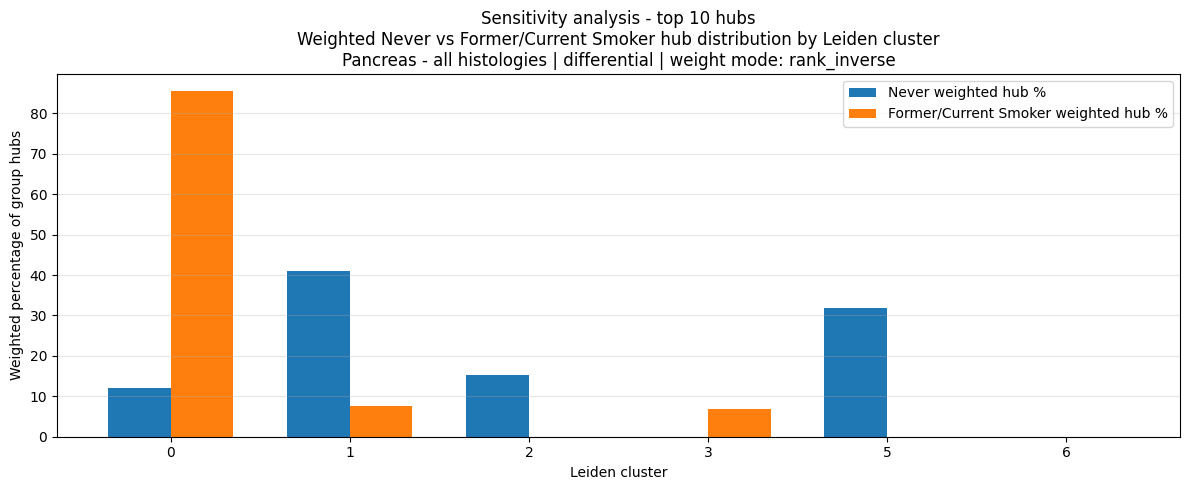

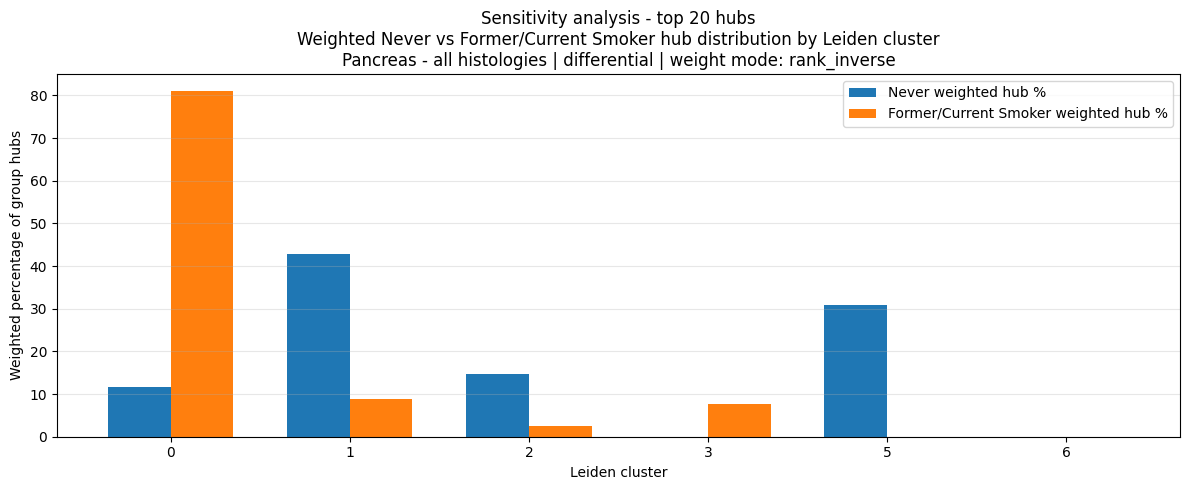

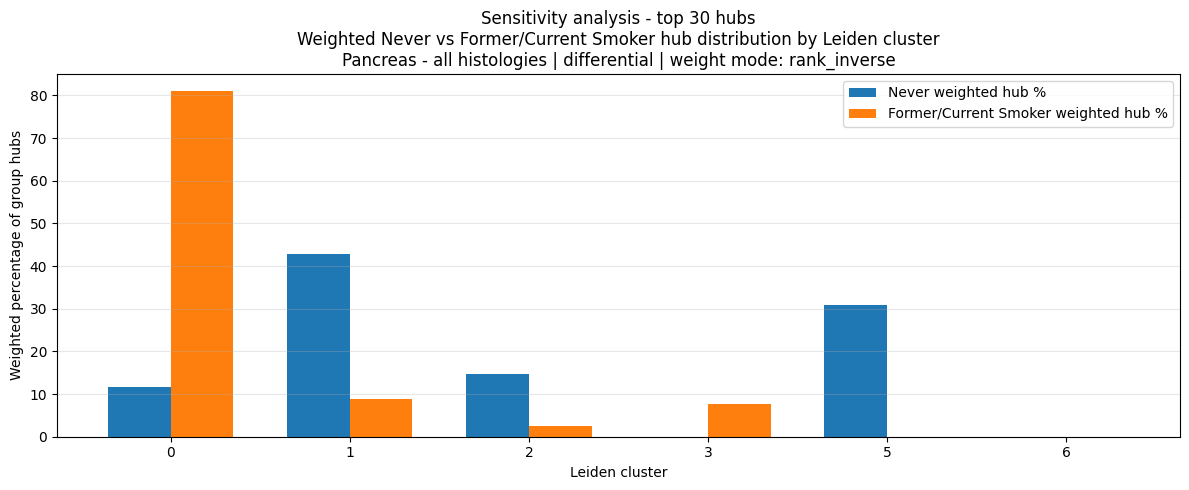

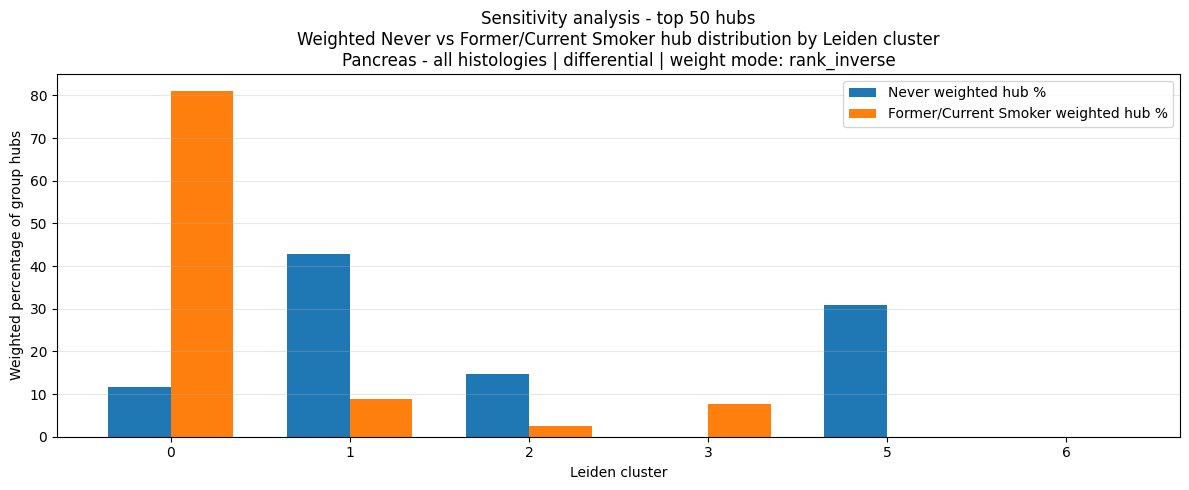

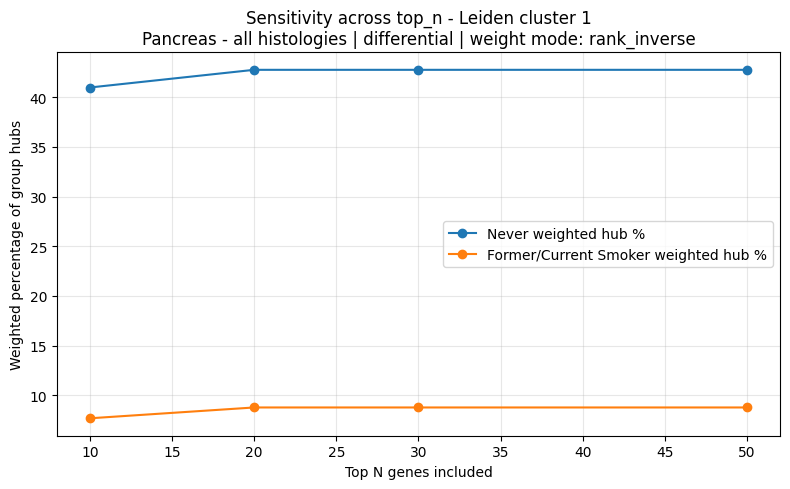

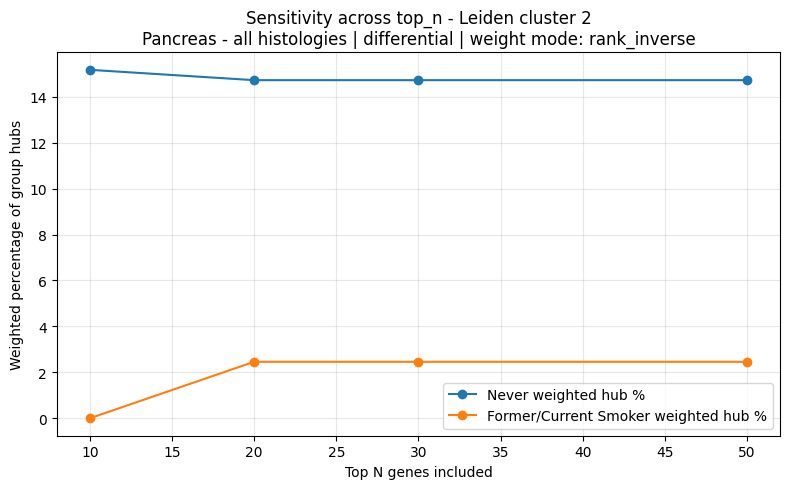


Saved sensitivity long table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_smoking_sensitivity_top_n_long.csv

Saved sensitivity wide table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_smoking_sensitivity_top_n_wide.csv

Saved sensitivity focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_smoking_sensitivity_top_n_focus_clusters_1_2.csv

Saved dominant clusters table:
data_pancreas\clinical_to_network_smoking_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_invers

In [29]:
# ============================================================
# SENSITIVITY ANALYSIS
# Weighted hub distribution by Leiden cluster
# Never vs Former/Current Smoker
# PANCREAS_ALL
#
# Obiettivo:
# - confrontare la distribuzione pesata degli hub usando diversi top_n
# - capire se il segnale sui cluster è stabile
# - mantenere focus specifico sui cluster 1 e 2
#
# Da eseguire DOPO la cella:
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER - PANCREAS_ALL SMOKING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

TOP_N_VALUES = [10, 20, 30, 50]

# Mantengo lo stesso weight mode della cella precedente
SENSITIVITY_WEIGHT_MODE = WEIGHT_MODE

# Focus sui cluster 1 e 2
clusters_of_interest = [1, 2]

sensitivity_output_dir = (
        output_dir
        / "sensitivity_analysis_top_n"
)

sensitivity_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Check input variables
# ============================================================

required_vars = [
    "mapped",
    "clusters",
    "PANCREAS_GROUP",
    "PANCREAS_LABEL",
    "NEVER_LABEL",
    "SMOKER_LABEL",
    "SMOKING_GROUPS",
    "ANALYSIS_MODE",
    "WEIGHT_MODE",
    "output_dir"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella della weighted hub distribution PANCREAS_ALL Smoking."
    )


# ============================================================
# 2. Prepare base mapped table
# ============================================================

base_mapped = mapped.copy()
base_mapped = base_mapped.loc[:, ~base_mapped.columns.duplicated()].copy()

required_cols = {
    "Gene",
    "Cluster",
    "Hub_Group",
    "HubScore_for_weight"
}

missing_cols = required_cols - set(base_mapped.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in mapped: {missing_cols}. "
        "Controlla che la cella precedente abbia creato Hub_Group e HubScore_for_weight."
    )

base_mapped["Gene"] = base_mapped["Gene"].astype(str)

base_mapped["Cluster"] = pd.to_numeric(
    base_mapped["Cluster"],
    errors="coerce"
)

base_mapped["HubScore_for_weight"] = pd.to_numeric(
    base_mapped["HubScore_for_weight"],
    errors="coerce"
)

base_mapped = base_mapped.dropna(
    subset=[
        "Gene",
        "Cluster",
        "Hub_Group",
        "HubScore_for_weight"
    ]
).copy()

base_mapped["Cluster"] = base_mapped["Cluster"].astype(int)

# Una riga per gene dentro ciascun gruppo
base_mapped = (
    base_mapped
    .sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    )
    .drop_duplicates(["Hub_Group", "Gene"], keep="first")
    .copy()
)

base_mapped["Full_rank_in_group"] = (
    base_mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

available_by_group = (
    base_mapped
    .groupby("Hub_Group")
    .agg(
        available_genes=("Gene", "nunique"),
        max_rank=("Full_rank_in_group", "max")
    )
    .reset_index()
)

print("\nAvailable mapped genes by group:")
try:
    display(available_by_group)
except NameError:
    print(available_by_group)

max_requested_top_n = max(TOP_N_VALUES)

if available_by_group["available_genes"].min() < max_requested_top_n:
    print(
        "\nATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.\n"
        "Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity "
        "a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto."
    )


# ============================================================
# 3. Cluster sizes
# ============================================================

clusters_tmp = clusters.copy()
clusters_tmp = clusters_tmp.loc[:, ~clusters_tmp.columns.duplicated()].copy()

clusters_tmp["Cluster"] = pd.to_numeric(
    clusters_tmp["Cluster"],
    errors="coerce"
)

clusters_tmp["Gene"] = clusters_tmp["Gene"].astype(str)

cluster_sizes_sens = (
    clusters_tmp
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)

all_clusters = sorted(
    cluster_sizes_sens["Cluster"]
    .dropna()
    .astype(int)
    .unique()
)


# ============================================================
# 4. Helper functions
# ============================================================

def assign_sensitivity_weight(row, weight_mode):
    rank = row["Hub_rank_in_selected_group"]
    n = row["n_hubs_in_selected_group"]
    hubscore = row["HubScore_for_weight"]

    if weight_mode == "hubscore":
        return hubscore

    if weight_mode == "rank_inverse":
        return 1 / rank

    if weight_mode == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("SENSITIVITY_WEIGHT_MODE non valido.")


def compute_weighted_distribution_for_top_n(top_n):
    """
    Calcola distribuzione pesata per uno specifico top_n.
    """

    selected = (
        base_mapped[
            base_mapped["Full_rank_in_group"] <= top_n
            ]
        .copy()
    )

    if selected.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    selected = selected.sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    ).copy()

    selected["Hub_rank_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["HubScore_for_weight"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    selected["n_hubs_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["Gene"]
        .transform("nunique")
    )

    selected["raw_weight"] = selected.apply(
        lambda row: assign_sensitivity_weight(
            row,
            SENSITIVITY_WEIGHT_MODE
        ),
        axis=1
    )

    selected["normalized_weight"] = (
            selected["raw_weight"]
            / selected.groupby("Hub_Group")["raw_weight"].transform("sum")
            * 100
    )

    selected["normalized_weight"] = selected["normalized_weight"].round(4)

    weighted_long_top = (
        selected
        .groupby(["Hub_Group", "Cluster"])
        .agg(
            n_hubs=("Gene", "nunique"),
            weighted_hub_score=("normalized_weight", "sum"),
            mean_hubscore=("HubScore_for_weight", "mean"),
            best_rank=("Hub_rank_in_selected_group", "min"),
            genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
        )
        .reset_index()
    )

    weighted_long_top["weighted_hub_score"] = (
        weighted_long_top["weighted_hub_score"]
        .round(2)
    )

    weighted_long_top["mean_hubscore"] = (
        weighted_long_top["mean_hubscore"]
        .round(4)
    )

    weighted_long_top = weighted_long_top.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left"
    )

    weighted_long_top["pct_cluster_covered_by_hubs"] = np.where(
        weighted_long_top["cluster_size_genes"] > 0,
        weighted_long_top["n_hubs"] / weighted_long_top["cluster_size_genes"] * 100,
        0
    ).round(2)

    weighted_long_top["top_n"] = top_n

    # Completo anche i cluster con 0 hub
    all_combinations = pd.MultiIndex.from_product(
        [SMOKING_GROUPS, all_clusters],
        names=["Hub_Group", "Cluster"]
    ).to_frame(index=False)

    complete = all_combinations.merge(
        weighted_long_top,
        on=["Hub_Group", "Cluster"],
        how="left"
    )

    complete = complete.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left",
        suffixes=("", "_from_clusters")
    )

    complete["cluster_size_genes"] = (
        complete["cluster_size_genes"]
        .fillna(complete["cluster_size_genes_from_clusters"])
    )

    complete = complete.drop(
        columns=["cluster_size_genes_from_clusters"],
        errors="ignore"
    )

    fill_zero_cols = [
        "n_hubs",
        "weighted_hub_score",
        "mean_hubscore",
        "pct_cluster_covered_by_hubs"
    ]

    for col in fill_zero_cols:
        complete[col] = complete[col].fillna(0)

    complete["best_rank"] = complete["best_rank"].fillna(np.nan)
    complete["genes"] = complete["genes"].fillna("-")
    complete["top_n"] = top_n

    # Wide table
    group_prefix = {
        NEVER_LABEL: "Never",
        SMOKER_LABEL: "Former_Current_Smoker"
    }

    wide_parts = []

    for group in SMOKING_GROUPS:

        prefix = group_prefix[group]

        tmp = complete[
            complete["Hub_Group"] == group
            ][
            [
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "mean_hubscore",
                "best_rank",
                "pct_cluster_covered_by_hubs",
                "genes"
            ]
        ].copy()

        tmp = tmp.rename(columns={
            "n_hubs": f"{prefix}_n_hubs",
            "weighted_hub_score": f"{prefix}_weighted_pct",
            "mean_hubscore": f"{prefix}_mean_hubscore",
            "best_rank": f"{prefix}_best_rank",
            "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
            "genes": f"{prefix}_genes"
        })

        wide_parts.append(tmp)

    wide_top = cluster_sizes_sens.copy()

    for tmp in wide_parts:
        wide_top = wide_top.merge(
            tmp,
            on="Cluster",
            how="left"
        )

    wide_top = wide_top.fillna({
        "Never_n_hubs": 0,
        "Never_weighted_pct": 0,
        "Never_mean_hubscore": 0,
        "Never_pct_cluster_covered": 0,
        "Never_genes": "-",
        "Former_Current_Smoker_n_hubs": 0,
        "Former_Current_Smoker_weighted_pct": 0,
        "Former_Current_Smoker_mean_hubscore": 0,
        "Former_Current_Smoker_pct_cluster_covered": 0,
        "Former_Current_Smoker_genes": "-"
    })

    wide_top["Never_n_hubs"] = wide_top["Never_n_hubs"].astype(int)
    wide_top["Former_Current_Smoker_n_hubs"] = (
        wide_top["Former_Current_Smoker_n_hubs"]
        .astype(int)
    )

    wide_top["Delta_weighted_pct_Never_minus_Former_Current_Smoker"] = (
            wide_top["Never_weighted_pct"]
            - wide_top["Former_Current_Smoker_weighted_pct"]
    ).round(2)

    wide_top["Delta_n_hubs_Never_minus_Former_Current_Smoker"] = (
            wide_top["Never_n_hubs"]
            - wide_top["Former_Current_Smoker_n_hubs"]
    )

    wide_top["top_n"] = top_n

    selected_detail = selected[
        [
            "Hub_Group",
            "Gene",
            "Cluster",
            "HubScore_for_weight",
            "Full_rank_in_group",
            "Hub_rank_in_selected_group",
            "raw_weight",
            "normalized_weight"
        ]
    ].copy()

    selected_detail["top_n"] = top_n

    return weighted_long_top, wide_top, selected_detail


# ============================================================
# 5. Run sensitivity analysis
# ============================================================

sensitivity_long_tables = []
sensitivity_wide_tables = []
sensitivity_gene_detail_tables = []

for top_n in TOP_N_VALUES:

    weighted_long_top, wide_top, selected_detail = compute_weighted_distribution_for_top_n(
        top_n=top_n
    )

    if not weighted_long_top.empty:
        sensitivity_long_tables.append(weighted_long_top)

    if not wide_top.empty:
        sensitivity_wide_tables.append(wide_top)

    if not selected_detail.empty:
        sensitivity_gene_detail_tables.append(selected_detail)


sensitivity_long = pd.concat(
    sensitivity_long_tables,
    ignore_index=True
) if sensitivity_long_tables else pd.DataFrame()

sensitivity_wide = pd.concat(
    sensitivity_wide_tables,
    ignore_index=True
) if sensitivity_wide_tables else pd.DataFrame()

sensitivity_gene_detail = pd.concat(
    sensitivity_gene_detail_tables,
    ignore_index=True
) if sensitivity_gene_detail_tables else pd.DataFrame()


# ============================================================
# 6. Dominant clusters by top_n
# ============================================================

if not sensitivity_long.empty:

    dominant_clusters_by_top_n = (
        sensitivity_long
        .sort_values(
            ["top_n", "Hub_Group", "weighted_hub_score"],
            ascending=[True, True, False]
        )
        .groupby(["top_n", "Hub_Group"])
        .head(3)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 120)
    print("TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP")
    print("=" * 120)

    try:
        display(
            dominant_clusters_by_top_n[
                [
                    "top_n",
                    "Hub_Group",
                    "Cluster",
                    "n_hubs",
                    "weighted_hub_score",
                    "best_rank",
                    "genes"
                ]
            ]
        )
    except NameError:
        print(
            dominant_clusters_by_top_n[
                [
                    "top_n",
                    "Hub_Group",
                    "Cluster",
                    "n_hubs",
                    "weighted_hub_score",
                    "best_rank",
                    "genes"
                ]
            ]
        )

else:
    dominant_clusters_by_top_n = pd.DataFrame()
    print("No sensitivity results available.")


# ============================================================
# 7. Focus table on clusters 1 and 2
# ============================================================

if not sensitivity_wide.empty:

    sensitivity_focus = sensitivity_wide[
        sensitivity_wide["Cluster"].isin(clusters_of_interest)
    ].copy()

    print("\n" + "=" * 120)
    print(f"SENSITIVITY FOCUS ON CLUSTERS {clusters_of_interest}")
    print("=" * 120)

    display_cols = [
        "top_n",
        "Cluster",
        "cluster_size_genes",
        "Never_n_hubs",
        "Never_weighted_pct",
        "Former_Current_Smoker_n_hubs",
        "Former_Current_Smoker_weighted_pct",
        "Delta_weighted_pct_Never_minus_Former_Current_Smoker",
        "Never_genes",
        "Former_Current_Smoker_genes"
    ]

    try:
        display(sensitivity_focus[display_cols])
    except NameError:
        print(sensitivity_focus[display_cols])

else:
    sensitivity_focus = pd.DataFrame()


# ============================================================
# 8. Plot 1: weighted distribution for each top_n
# General plot over all clusters
# ============================================================

if not sensitivity_wide.empty:

    for top_n in TOP_N_VALUES:

        plot_df = sensitivity_wide[
            sensitivity_wide["top_n"] == top_n
            ][
            [
                "Cluster",
                "Never_weighted_pct",
                "Former_Current_Smoker_weighted_pct"
            ]
        ].copy()

        if plot_df.empty:
            continue

        x = np.arange(len(plot_df))
        width = 0.35

        plt.figure(figsize=(12, 5))

        plt.bar(
            x - width / 2,
            plot_df["Never_weighted_pct"],
            width,
            label="Never weighted hub %"
        )

        plt.bar(
            x + width / 2,
            plot_df["Former_Current_Smoker_weighted_pct"],
            width,
            label="Former/Current Smoker weighted hub %"
        )

        plt.xticks(x, plot_df["Cluster"])
        plt.xlabel("Leiden cluster")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity analysis - top {top_n} hubs\n"
            f"Weighted Never vs Former/Current Smoker hub distribution by Leiden cluster\n"
            f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(axis="y", alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 9. Plot 2: stability of clusters 1 and 2 across top_n
# ============================================================

if not sensitivity_wide.empty and not sensitivity_focus.empty:

    for cluster_id in clusters_of_interest:

        plot_cluster = sensitivity_wide[
            sensitivity_wide["Cluster"] == cluster_id
            ].sort_values("top_n").copy()

        if plot_cluster.empty:
            continue

        plt.figure(figsize=(8, 5))

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Never_weighted_pct"],
            marker="o",
            label="Never weighted hub %"
        )

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Former_Current_Smoker_weighted_pct"],
            marker="o",
            label="Former/Current Smoker weighted hub %"
        )

        plt.xlabel("Top N genes included")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity across top_n - Leiden cluster {cluster_id}\n"
            f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

sensitivity_long_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_smoking_sensitivity_top_n_long.csv"
)

sensitivity_wide_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_smoking_sensitivity_top_n_wide.csv"
)

sensitivity_focus_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_smoking_sensitivity_top_n_focus_clusters_1_2.csv"
)

sensitivity_dominant_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_smoking_sensitivity_top_n_dominant_clusters.csv"
)

sensitivity_gene_detail_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_smoking_sensitivity_top_n_gene_detail.csv"
)

sensitivity_long.to_csv(sensitivity_long_output, index=False)
sensitivity_wide.to_csv(sensitivity_wide_output, index=False)
sensitivity_focus.to_csv(sensitivity_focus_output, index=False)
dominant_clusters_by_top_n.to_csv(sensitivity_dominant_output, index=False)
sensitivity_gene_detail.to_csv(sensitivity_gene_detail_output, index=False)

print("\nSaved sensitivity long table:")
print(sensitivity_long_output)

print("\nSaved sensitivity wide table:")
print(sensitivity_wide_output)

print("\nSaved sensitivity focus table for clusters 1 and 2:")
print(sensitivity_focus_output)

print("\nSaved dominant clusters table:")
print(sensitivity_dominant_output)

print("\nSaved sensitivity gene detail:")
print(sensitivity_gene_detail_output)


# ============================================================
# 11. Compatibility aliases
# ============================================================

sensitivity_long_pancreas_smoking = sensitivity_long
sensitivity_wide_pancreas_smoking = sensitivity_wide
sensitivity_focus_pancreas_smoking = sensitivity_focus
sensitivity_dominant_clusters_pancreas_smoking = dominant_clusters_by_top_n
sensitivity_gene_detail_pancreas_smoking = sensitivity_gene_detail


# ============================================================
# 12. Interpretation helper
# ============================================================

print("\n" + "=" * 120)
print("INTERPRETATION GUIDE")
print("=" * 120)

print(
    "1. Se gli stessi cluster restano dominanti passando da top 10 a top 20, 30 e 50, "
    "il segnale è più robusto."
)

print(
    "2. Se un cluster è dominante solo con top 10 ma scompare con top 30/top 50, "
    "probabilmente il risultato dipende dai primissimi hub."
)

print(
    "3. Se un cluster aumenta usando top_n più grande, significa che il segnale non è limitato "
    "ai primissimi hub ma coinvolge anche hub meno estremi."
)

print(
    "4. Per il report puoi usare top 20 come analisi principale e questa sensitivity analysis "
    "come controllo di robustezza."
)

print(
    "5. In questa versione il focus specifico è sui cluster 1 e 2, mentre i bar chart generali "
    "mostrano comunque tutti i cluster."
)

print(
    "6. Il confronto è Never vs Former/Current Smoker su PANCREAS_ALL, "
    "senza separazione per istologia / Oncotree."
)

OS_MONTHS/event non presenti nel merged smoking file. Li recupero da filtered_data_PANCREAS.csv.
Loaded:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv

Duplicate columns after cleaning:
[]

Rows: 6358
Patients: 886
Group: PANCREAS_ALL

Patients in PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,n_patients,n_events
0,PANCREAS_ALL,Pancreas - all histologies,886,712



Smoking distribution in PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,smoking_group,n_patients,n_events,original_smoking_values
0,PANCREAS_ALL,Pancreas - all histologies,Former/Current Smoker,361,290,Former/Current Smoker
1,PANCREAS_ALL,Pancreas - all histologies,Never,525,422,Never


Uso hub_comparison_pancreas_smoking già presente in memoria.

GROUP: PANCREAS_ALL (Pancreas - all histologies)
Signature: PANCREAS_ALL_NEVER_hub_signature
Genes: AKT2, BCOR, ELF3, ERBB4, KDM6A, KEAP1, NOTCH1, PTPRD, RAD21, RECQL4
Patients with signature mutation: 196
Patients without signature mutation: 690
Events with signature mutation: 159
Events without signature mutation: 553


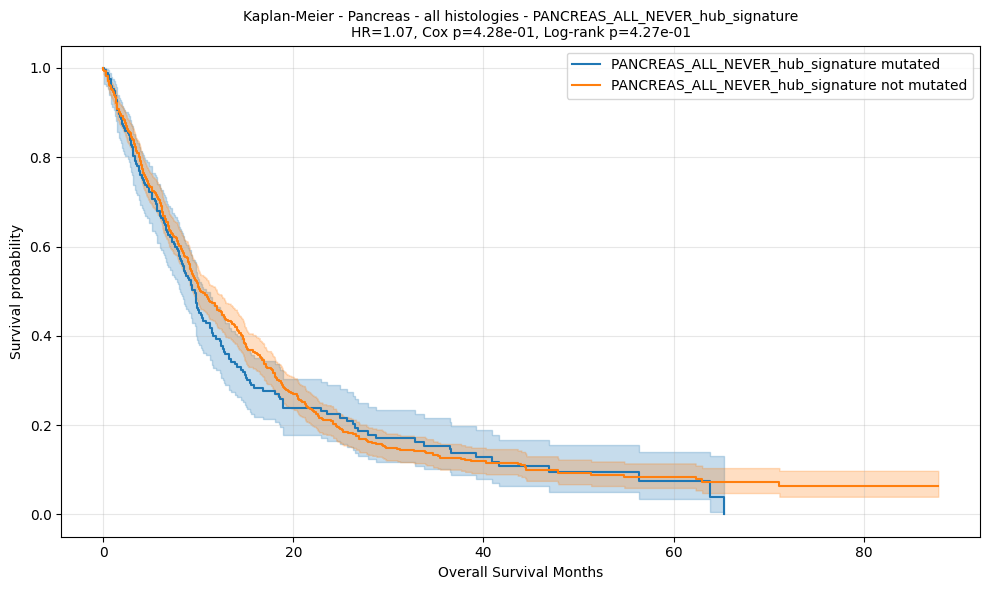

KM plot salvato in: data_pancreas\clinical_to_network_smoking_pancreas_all\km_hub_signatures_pancreas_all_smoking\KM_PANCREAS_ALL_PANCREAS_ALL_NEVER_hub_signature.png

GROUP: PANCREAS_ALL (Pancreas - all histologies)
Signature: PANCREAS_ALL_FORMER_CURRENT_SMOKER_hub_signature
Genes: AMER1, ARID1A, CCNE1, CDKN2A, CDKN2B, CEBPA, MTAP, SMAD2, TEK, TP53
Patients with signature mutation: 771
Patients without signature mutation: 115
Events with signature mutation: 632
Events without signature mutation: 80


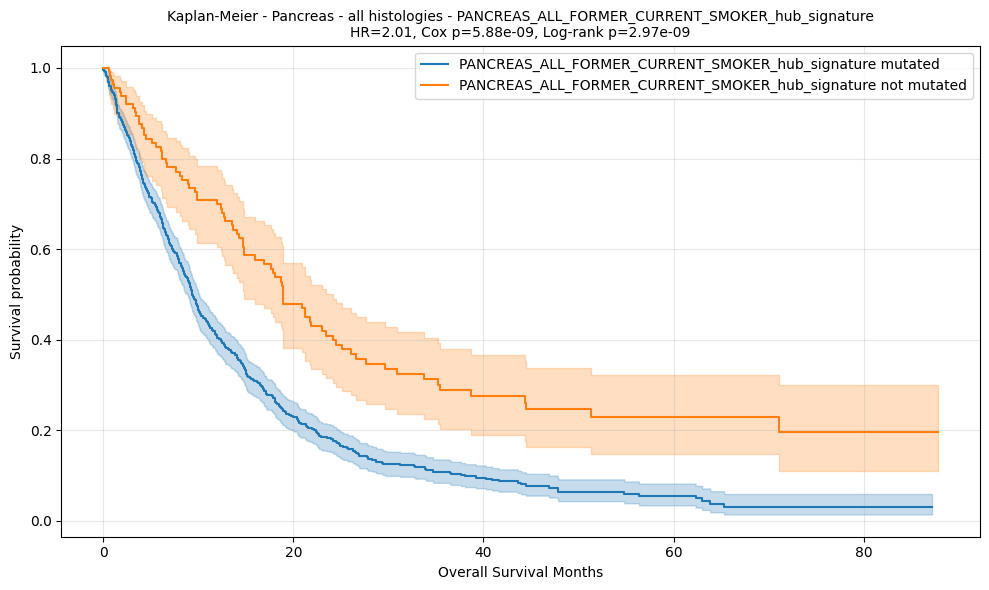

KM plot salvato in: data_pancreas\clinical_to_network_smoking_pancreas_all\km_hub_signatures_pancreas_all_smoking\KM_PANCREAS_ALL_PANCREAS_ALL_FORMER_CURRENT_SMOKER_hub_signature.png

KM results - clinical to network smoking-derived signatures - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,Signature,Num_genes,Genes,Patients_with_signature,Events_with_signature,Patients_without_signature,Events_without_signature,Logrank_p_value,Hazard_Ratio,Cox_p_value
0,PANCREAS_ALL,Pancreas - all histologies,PANCREAS_ALL_FORMER_CURRENT_SMOKER_hub_signature,10,"AMER1, ARID1A, CCNE1, CDKN2A, CDKN2B, CEBPA, MTAP, SMAD2, TEK, TP53",771,632,115,80,2.971316e-09,2.013113,5.884280e-09
1,PANCREAS_ALL,Pancreas - all histologies,PANCREAS_ALL_NEVER_hub_signature,10,"AKT2, BCOR, ELF3, ERBB4, KDM6A, KEAP1, NOTCH1, PTPRD, RAD21, RECQL4",196,159,690,553,4.272984e-01,1.073955,4.282709e-01



KM results salvati in:
data_pancreas\clinical_to_network_smoking_pancreas_all\km_hub_signatures_pancreas_all_smoking\km_results_clinical_to_network_smoking_hub_signatures_PANCREAS_ALL.csv

Nota finale:
La Kaplan-Meier è stata eseguita su PANCREAS_ALL, usando le signature derivate dagli hub Never e Former/Current Smoker. Non viene fatta nessuna separazione per istologia / Oncotree.


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test


# ============================================================
# KM ANALYSIS - CLINICAL TO NETWORK
# PANCREAS_ALL
#
# Hub gene signatures:
# - NEVER-hub signature
# - FORMER/CURRENT SMOKER-hub signature
#
# Nota:
# - la stratificazione di rete viene da smoking_group
# - la Kaplan-Meier usa comunque OS_MONTHS ed event
# - non viene fatta nessuna separazione per istologia / ONCOTREE_CODE
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

NEVER_LABEL = "Never"
SMOKER_LABEL = "Former/Current Smoker"

merged_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_smoking_groups_PANCREAS_ALL.csv"
)

# File clinico originale usato solo come fallback se OS_MONTHS / event
# non sono presenti nel merged smoking file.
clinical_fallback_path = data_dir / "filtered_data_PANCREAS.csv"

km_output_dir = (
        data_dir
        / "clinical_to_network_smoking_pancreas_all"
        / "km_hub_signatures_pancreas_all_smoking"
)

km_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helpers against duplicate columns
# ============================================================

def collapse_duplicate_columns(df):
    """
    Se ci sono colonne duplicate, le collassa prendendo il primo valore non nullo.
    """
    df = df.copy()

    if not df.columns.duplicated().any():
        return df

    collapsed = pd.DataFrame(index=df.index)

    for col in pd.unique(df.columns):
        same_cols = df.loc[:, df.columns == col]

        if same_cols.shape[1] == 1:
            collapsed[col] = same_cols.iloc[:, 0]
        else:
            collapsed[col] = same_cols.bfill(axis=1).iloc[:, 0]

    return collapsed.copy()


def get_single_column(df, col):
    """
    Restituisce sempre una Series, anche se per errore ci sono colonne duplicate.
    """
    obj = df[col]

    if isinstance(obj, pd.DataFrame):
        return obj.iloc[:, 0]

    return obj


def safe_filename(text):
    text = str(text)
    text = text.replace("+", "_")
    text = text.replace("/", "_")
    text = text.replace(" ", "_")
    text = text.replace("(", "")
    text = text.replace(")", "")
    text = text.replace(",", "")
    text = text.replace("<", "lt")
    text = text.replace(">", "gt")
    text = text.replace("=", "eq")
    return text


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def assign_smoking_group(value):
    """
    Normalizza la feature smoking in due gruppi principali:
    - Never
    - Former/Current Smoker
    """
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip()

    if value_str == "":
        return np.nan

    value_low = value_str.lower()

    if value_low in ["nan", "none", "unknown", "not available", "na", "n/a"]:
        return np.nan

    if value_low in ["never", "never smoker", "non-smoker", "nonsmoker"]:
        return "Never"

    if (
            "former" in value_low
            or "current" in value_low
            or "smoker" in value_low
            or "smoking" in value_low
    ):
        return "Former/Current Smoker"

    return value_str


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file:
    1. nei path candidati;
    2. con glob nella cartella indicata.
    """
    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"No {description} found.")
    return None


def load_hub_comparison_pancreas_smoking():
    """
    Carica la tabella di confronto hub Never vs Former/Current Smoker per PANCREAS_ALL.
    Prima prova dalle variabili in memoria, poi dai CSV salvati.
    """

    possible_memory_vars = [
        "hub_comparison_pancreas_smoking",
        "hub_comparison_all_pancreas_smoking",
        "hub_comparison_all_oncotree_smoking",
        "hub_comparison_all_oncotree_groups",
        "hub_comparison_all_oncotree"
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    hub_analysis_dir = (
            data_dir
            / "clinical_to_network_smoking_pancreas_all"
            / "hub_analysis_pancreas_all_smoking"
    )

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_never_vs_former_current_smoker_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_PANCREAS_ALL_never_vs_former_current_smoker_comparison.csv",

        hub_analysis_dir
        / "hub_genes_smoking_comparison_pancreas_all.csv",
    ]

    patterns = [
        "*PANCREAS_ALL*never*former_current_smoker*comparison*.csv",
        "*never*former_current_smoker*comparison*pancreas*.csv",
        "*hub*smoking*comparison*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="hub comparison Never vs Former/Current Smoker for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub comparison da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto hub Never vs Former/Current Smoker.\n"
        "Esegui prima la cella di hub comparison per PANCREAS_ALL smoking."
    )


# ============================================================
# Load merged dataset
# ============================================================

df_merge = pd.read_csv(merged_path, low_memory=False)
df_merge = collapse_duplicate_columns(df_merge)


# ------------------------------------------------------------
# Uniform column names safely
# ------------------------------------------------------------

if "PATIENT_ID" in df_merge.columns and "Patient_ID" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Oncotree Code" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Code": "ONCOTREE_CODE"})

if "Oncotree_Group" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree_Group": "ONCOTREE_CODE"})

if "ONCOTREE_GROUP" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"ONCOTREE_GROUP": "ONCOTREE_CODE"})

if "Oncotree Group" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Group": "ONCOTREE_CODE"})

# Smoking columns
if "Smoking History (NLP)" in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Smoking History (NLP)": "SMOKING_RAW"})

if "Smoking History" in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Smoking History": "SMOKING_RAW"})

if "Smoking_History_NLP" in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Smoking_History_NLP": "SMOKING_RAW"})

if "SMOKING" in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"SMOKING": "SMOKING_RAW"})

if "Smoking" in df_merge.columns and "SMOKING_RAW" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Smoking": "SMOKING_RAW"})

if "SMOKING_GROUP" in df_merge.columns and "smoking_group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"SMOKING_GROUP": "smoking_group"})

if "Smoking_Group" in df_merge.columns and "smoking_group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Smoking_Group": "smoking_group"})

# Gene column
if "Hugo_Symbol" not in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.rename(columns={"Gene": "Hugo_Symbol"})
elif "Hugo_Symbol" in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.drop(columns=["Gene"])

df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Force PANCREAS_ALL group
# ============================================================

df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# Create smoking_group if missing
# ============================================================

if "smoking_group" not in df_merge.columns:
    if "SMOKING_RAW" not in df_merge.columns:
        raise ValueError(
            "smoking_group mancante e colonna SMOKING_RAW / Smoking History (NLP) non disponibile. "
            "Controlla che il file merged smoking contenga la feature 'Smoking History (NLP)'."
        )

    df_merge["smoking_group"] = (
        get_single_column(df_merge, "SMOKING_RAW")
        .apply(assign_smoking_group)
    )

else:
    df_merge["smoking_group"] = (
        get_single_column(df_merge, "smoking_group")
        .apply(assign_smoking_group)
    )

if "SMOKING_RAW" not in df_merge.columns:
    df_merge["SMOKING_RAW"] = df_merge["smoking_group"]

df_merge["SMOKING_RAW"] = get_single_column(df_merge, "SMOKING_RAW").astype(str).str.strip()

df_merge.loc[
    df_merge["SMOKING_RAW"].str.lower().isin(["nan", "none", "", "unknown", "not available", "na", "n/a"]),
    "SMOKING_RAW"
] = np.nan

df_merge.loc[df_merge["smoking_group"].isna(), "SMOKING_RAW"] = np.nan


# ============================================================
# Fallback: add OS_MONTHS / event if missing
# ============================================================
# Per la KM servono OS_MONTHS ed event.
# Se non sono nel file merged, li recupero da filtered_data_PANCREAS.csv.

needs_survival_fallback = (
        "OS_MONTHS" not in df_merge.columns
        or "event" not in df_merge.columns
)

if needs_survival_fallback:
    print(
        "OS_MONTHS/event non presenti nel merged smoking file. "
        "Li recupero da filtered_data_PANCREAS.csv."
    )

    clinical_surv = pd.read_csv(clinical_fallback_path, low_memory=False)
    clinical_surv = collapse_duplicate_columns(clinical_surv)

    clinical_surv = clinical_surv.rename(columns={
        "PATIENT_ID": "Patient_ID",
        "Patient_ID": "Patient_ID",
        "Overall Survival (Months)": "OS_MONTHS",
        "Overall Survival Status": "OS_STATUS"
    })

    required_surv_cols = {
        "Patient_ID",
        "OS_MONTHS",
        "OS_STATUS"
    }

    missing_surv_cols = required_surv_cols - set(clinical_surv.columns)

    if missing_surv_cols:
        raise ValueError(
            f"Colonne mancanti nel file clinico fallback per survival: {missing_surv_cols}"
        )

    clinical_surv["Patient_ID"] = clinical_surv["Patient_ID"].astype(str).str.strip()

    clinical_surv["OS_MONTHS"] = pd.to_numeric(
        clinical_surv["OS_MONTHS"],
        errors="coerce"
    )

    clinical_surv["OS_STATUS"] = clinical_surv["OS_STATUS"].astype(str)

    clinical_surv["event"] = (
        clinical_surv["OS_STATUS"]
        .str.contains("DECEASED", case=False, na=False)
        .astype(int)
    )

    clinical_surv = (
        clinical_surv[
            [
                "Patient_ID",
                "OS_MONTHS",
                "OS_STATUS",
                "event"
            ]
        ]
        .dropna(subset=["Patient_ID", "OS_MONTHS", "event"])
        .drop_duplicates("Patient_ID")
        .copy()
    )

    cols_to_remove_before_surv_merge = [
        col for col in ["OS_MONTHS", "OS_STATUS", "event"]
        if col in df_merge.columns
    ]

    df_merge = df_merge.drop(
        columns=cols_to_remove_before_surv_merge
    ).copy()

    df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()

    df_merge = df_merge.merge(
        clinical_surv,
        on="Patient_ID",
        how="left"
    )

    df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Check required columns
# ============================================================

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "ONCOTREE_CODE",
    "smoking_group",
    "OS_MONTHS",
    "event"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel merged file per PANCREAS_ALL + smoking: {missing_cols}. "
        "Controlla che smoking_group, OS_MONTHS ed event siano disponibili."
    )


# ============================================================
# Type conversion and cleaning
# ============================================================

df_merge["Patient_ID"] = get_single_column(df_merge, "Patient_ID").astype(str).str.strip()
df_merge["Hugo_Symbol"] = get_single_column(df_merge, "Hugo_Symbol").astype(str).str.strip()
df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL
df_merge["smoking_group"] = get_single_column(df_merge, "smoking_group").apply(assign_smoking_group)

df_merge["OS_MONTHS"] = pd.to_numeric(
    get_single_column(df_merge, "OS_MONTHS"),
    errors="coerce"
)

df_merge["event"] = pd.to_numeric(
    get_single_column(df_merge, "event"),
    errors="coerce"
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "smoking_group",
        "OS_MONTHS",
        "event"
    ]
).copy()

df_merge["event"] = df_merge["event"].astype(int)

print("Loaded:")
print(merged_path)

print("\nDuplicate columns after cleaning:")
print(df_merge.columns[df_merge.columns.duplicated()].tolist())

print("\nRows:", df_merge.shape[0])
print("Patients:", df_merge["Patient_ID"].nunique())
print("Group:", PANCREAS_GROUP)

print("\nPatients in PANCREAS_ALL:")

safe_display(
    df_merge
    .drop_duplicates(["Patient_ID"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum")
    )
    .reset_index()
)

print("\nSmoking distribution in PANCREAS_ALL:")

safe_display(
    df_merge
    .drop_duplicates(["Patient_ID"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "smoking_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum"),
        original_smoking_values=(
            "SMOKING_RAW",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "smoking_group"])
)


# ============================================================
# PARAMETERS
# ============================================================

top_n_genes = 10
min_patients_per_group = 10
min_events_per_group = 5

km_results = []


# ============================================================
# KM helper
# ============================================================

def run_km_for_gene_signature(
        df_group,
        gene_signature,
        signature_name
):
    """
    Confronta:
    - pazienti con almeno una mutazione nei geni della signature
    - pazienti senza mutazioni nei geni della signature

    Le signature derivano dai geni hub Never / Former-Current Smoker,
    ma l'endpoint testato resta la sopravvivenza globale.
    """

    df_group = collapse_duplicate_columns(df_group)

    gene_signature = set([
        str(g)
        for g in gene_signature
        if pd.notna(g)
    ])

    if len(gene_signature) == 0:
        print(f"[{signature_name}] No genes in signature.")
        return None

    clinical = (
        df_group[
            [
                "Patient_ID",
                "OS_MONTHS",
                "event"
            ]
        ]
        .drop_duplicates("Patient_ID")
        .copy()
    )

    gene_series = get_single_column(df_group, "Hugo_Symbol").astype(str)

    mask_signature = gene_series.isin(gene_signature)

    patients_with_signature = (
        df_group.loc[mask_signature, "Patient_ID"]
        .dropna()
        .astype(str)
        .unique()
    )

    clinical["has_signature"] = (
        clinical["Patient_ID"]
        .astype(str)
        .isin(patients_with_signature)
        .astype(int)
    )

    n_mut = int(clinical["has_signature"].sum())
    n_wt = int((clinical["has_signature"] == 0).sum())

    events_mut = int(
        clinical.loc[
            clinical["has_signature"] == 1,
            "event"
        ].sum()
    )

    events_wt = int(
        clinical.loc[
            clinical["has_signature"] == 0,
            "event"
        ].sum()
    )

    print("\n" + "=" * 90)
    print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
    print(f"Signature: {signature_name}")
    print(f"Genes: {', '.join(sorted(gene_signature))}")
    print(f"Patients with signature mutation: {n_mut}")
    print(f"Patients without signature mutation: {n_wt}")
    print(f"Events with signature mutation: {events_mut}")
    print(f"Events without signature mutation: {events_wt}")

    if (
            n_mut < min_patients_per_group
            or n_wt < min_patients_per_group
            or events_mut < min_events_per_group
            or events_wt < min_events_per_group
    ):
        print("Skipped: too few patients or events.")
        return None

    group_mut = clinical[clinical["has_signature"] == 1]
    group_wt = clinical[clinical["has_signature"] == 0]

    lr = logrank_test(
        group_mut["OS_MONTHS"],
        group_wt["OS_MONTHS"],
        event_observed_A=group_mut["event"],
        event_observed_B=group_wt["event"]
    )

    cox_df = clinical[
        [
            "OS_MONTHS",
            "event",
            "has_signature"
        ]
    ].copy()

    cph = CoxPHFitter()

    try:
        cph.fit(
            cox_df,
            duration_col="OS_MONTHS",
            event_col="event"
        )

        hr = np.exp(cph.params_["has_signature"])
        p_cox = cph.summary.loc["has_signature", "p"]

    except Exception as e:
        print(f"Cox model failed for {signature_name}: {e}")
        hr = np.nan
        p_cox = np.nan

    kmf = KaplanMeierFitter()

    plt.figure(figsize=(10, 6))

    kmf.fit(
        group_mut["OS_MONTHS"],
        event_observed=group_mut["event"],
        label=f"{signature_name} mutated"
    )
    kmf.plot_survival_function()

    kmf.fit(
        group_wt["OS_MONTHS"],
        event_observed=group_wt["event"],
        label=f"{signature_name} not mutated"
    )
    kmf.plot_survival_function()

    plt.title(
        f"Kaplan-Meier - {PANCREAS_LABEL} - {signature_name}\n"
        f"HR={hr:.2f}, Cox p={p_cox:.2e}, Log-rank p={lr.p_value:.2e}",
        fontsize=10
    )

    plt.xlabel("Overall Survival Months")
    plt.ylabel("Survival probability")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    fig_path = (
            km_output_dir
            / f"KM_{safe_filename(PANCREAS_GROUP)}_{safe_filename(signature_name)}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"KM plot salvato in: {fig_path}")

    return {
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "Signature": signature_name,
        "Num_genes": len(gene_signature),
        "Genes": ", ".join(sorted(gene_signature)),
        "Patients_with_signature": n_mut,
        "Events_with_signature": events_mut,
        "Patients_without_signature": n_wt,
        "Events_without_signature": events_wt,
        "Logrank_p_value": lr.p_value,
        "Hazard_Ratio": hr,
        "Cox_p_value": p_cox
    }


# ============================================================
# Load hub comparison table
# ============================================================

hub_comparison_pancreas_smoking = load_hub_comparison_pancreas_smoking()
hub_comparison_pancreas_smoking = collapse_duplicate_columns(hub_comparison_pancreas_smoking)

# Compatibilità:
# se la tabella ha Oncotree_Group, la rinomino in ONCOTREE_CODE.
if "ONCOTREE_CODE" not in hub_comparison_pancreas_smoking.columns:
    if "Oncotree_Group" in hub_comparison_pancreas_smoking.columns:
        hub_comparison_pancreas_smoking = hub_comparison_pancreas_smoking.rename(
            columns={"Oncotree_Group": "ONCOTREE_CODE"}
        )
    else:
        hub_comparison_pancreas_smoking["ONCOTREE_CODE"] = PANCREAS_GROUP

hub_comparison_pancreas_smoking["ONCOTREE_CODE"] = PANCREAS_GROUP

delta_col = "Delta_HubScore_never_minus_former_current_smoker"

required_hub_cols = {
    "ONCOTREE_CODE",
    "Gene",
    delta_col
}

missing_hub_cols = required_hub_cols - set(hub_comparison_pancreas_smoking.columns)

if missing_hub_cols:
    raise ValueError(
        f"Colonne mancanti in hub_comparison_pancreas_smoking: {missing_hub_cols}"
    )

hub_comparison_pancreas_smoking["Gene"] = (
    hub_comparison_pancreas_smoking["Gene"]
    .astype(str)
)

hub_comparison_pancreas_smoking[delta_col] = pd.to_numeric(
    hub_comparison_pancreas_smoking[delta_col],
    errors="coerce"
)

hub_comparison_pancreas_smoking = hub_comparison_pancreas_smoking.dropna(
    subset=["Gene", delta_col]
).copy()

if hub_comparison_pancreas_smoking.empty:
    raise ValueError(
        "La tabella hub_comparison_pancreas_smoking è vuota dopo il preprocessing."
    )


# ============================================================
# Build NEVER and FORMER/CURRENT SMOKER hub signatures
# ============================================================

never_signature_genes = (
    hub_comparison_pancreas_smoking
    .sort_values(delta_col, ascending=False)
    .head(top_n_genes)["Gene"]
    .dropna()
    .astype(str)
    .tolist()
)

former_current_smoker_signature_genes = (
    hub_comparison_pancreas_smoking
    .sort_values(delta_col, ascending=True)
    .head(top_n_genes)["Gene"]
    .dropna()
    .astype(str)
    .tolist()
)


# ============================================================
# RUN KM FOR PANCREAS_ALL
# ============================================================

res_never = run_km_for_gene_signature(
    df_group=df_merge,
    gene_signature=never_signature_genes,
    signature_name=f"{PANCREAS_GROUP}_NEVER_hub_signature"
)

if res_never is not None:
    km_results.append(res_never)

res_former_current_smoker = run_km_for_gene_signature(
    df_group=df_merge,
    gene_signature=former_current_smoker_signature_genes,
    signature_name=f"{PANCREAS_GROUP}_FORMER_CURRENT_SMOKER_hub_signature"
)

if res_former_current_smoker is not None:
    km_results.append(res_former_current_smoker)


# ============================================================
# FINAL TABLE
# ============================================================

km_results_clinical_to_network_pancreas_smoking = pd.DataFrame(km_results)

if not km_results_clinical_to_network_pancreas_smoking.empty:
    km_results_clinical_to_network_pancreas_smoking = (
        km_results_clinical_to_network_pancreas_smoking
        .sort_values(["Logrank_p_value"])
        .reset_index(drop=True)
    )

    output_file = (
            km_output_dir
            / "km_results_clinical_to_network_smoking_hub_signatures_PANCREAS_ALL.csv"
    )

    km_results_clinical_to_network_pancreas_smoking.to_csv(
        output_file,
        index=False
    )

    print("\nKM results - clinical to network smoking-derived signatures - PANCREAS_ALL:")

    safe_display(km_results_clinical_to_network_pancreas_smoking)

    print("\nKM results salvati in:")
    print(output_file)

else:
    print("\nNo KM result passed the minimum patient/event thresholds.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

km_results_clinical_to_network = km_results_clinical_to_network_pancreas_smoking
km_results_clinical_to_network_pancreas_all = km_results_clinical_to_network_pancreas_smoking
km_results_clinical_to_network_pancreas_all_smoking = km_results_clinical_to_network_pancreas_smoking

print("\nNota finale:")
print(
    "La Kaplan-Meier è stata eseguita su PANCREAS_ALL, usando le signature "
    "derivate dagli hub Never e Former/Current Smoker. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)